# Living longer, but not equally
### A visualization project on the World Bank's development indicators

**Course:** DSC 327 Data Visualization Techniques &nbsp;·&nbsp; **Class:** BDS 6 &nbsp;·&nbsp; **Lab Project (Mid), Fall 2026**
**Name:** _your name_ &nbsp;·&nbsp; **Reg. no.:** _your registration number_

---

For this project I'm using the World Bank's **World Development Indicators (WDI)**. It's open data (CC BY 4.0), it's well documented, and it has a public API, so the notebook pulls everything in code and anyone can rerun it and end up with the same table.

One question runs through every part: **why can a baby born in one country expect to live 20+ years longer than a baby born in another, and how much of that gap comes down to money?**

**How to run it**
1. `pip install -r requirements.txt`
2. Run all cells from top to bottom. The first run downloads the data (needs internet, takes about a minute) and keeps a copy in `data/raw/`, so later runs work offline.
3. Charts are saved to `figures/` as PNG and SVG, and the interactive ones as HTML. Colour-blindness and grayscale check sheets go to `figures/checks/`.

Two cells in Part 2 (the perception experiment and the pop-out timing test) need answers from real people. Until the CSV files they ask for are filled in, they run on clearly marked placeholder numbers.

In [1]:
import json
import warnings
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, Normalize, to_rgb, to_hex
from matplotlib.patches import Circle
import seaborn as sns
import networkx as nx
from scipy import stats
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, fcluster

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import altair as alt
from IPython.display import display, Markdown, Image

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# folders
ROOT = Path(".")
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
FIG, CHECKS = ROOT / "figures", ROOT / "figures" / "checks"
for p in [RAW, PROC, FIG, CHECKS]:
    p.mkdir(parents=True, exist_ok=True)

# one house style for every static chart
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 200,
    "font.size": 10, "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.6,
    "axes.edgecolor": "#888888", "axes.labelcolor": "#333333",
    "xtick.color": "#555555", "ytick.color": "#555555",
    "legend.frameon": False,
})
pio.templates.default = "simple_white"
alt.data_transformers.disable_max_rows()

SOURCE = "Source: World Bank, World Development Indicators"   # access date gets added after loading

### A few helpers I reuse everywhere

Nothing fancy. `save()` stamps the source note on a figure and writes PNG + SVG. `save_plotly()` does the same for Plotly figures (HTML always, PNG too if `kaleido` is installed). The colour functions are for the accessibility checks in Part 4: a colour-blindness simulator (the Machado et al. 2009 matrices), a grayscale conversion, and the WCAG contrast ratio.

In [2]:
def save(fig, name, extra=""):
    note = SOURCE + (f". {extra}" if extra else "")
    fig.canvas.draw()                                   # find the lowest thing on the figure (rotated labels etc.)
    bottom = fig.get_tightbbox(fig.canvas.get_renderer()).y0 / fig.get_figheight()
    fig.text(0.01, min(bottom, 0) - 0.01, note, fontsize=7.5, color="#555555", ha="left", va="top")
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    fig.savefig(FIG / f"{name}.svg", bbox_inches="tight")
    plt.show()


def save_plotly(fig, name, extra=""):
    note = SOURCE + (f". {extra}" if extra else "")
    fig.add_annotation(text=note, xref="paper", yref="paper", x=0, y=0, yshift=-60,
                       xanchor="left", yanchor="top", showarrow=False, font=dict(size=10, color="#555555"))
    fig.update_layout(margin=dict(b=90))
    fig.write_html(FIG / f"{name}.html", include_plotlyjs="cdn")
    try:
        fig.write_image(FIG / f"{name}.png", scale=2, width=1000, height=600)
    except Exception as e:
        print(f"(no {name}.png, kaleido isn't working here: {type(e).__name__}. The HTML is saved.)")
    fig.show()


# --- colour checks ---------------------------------------------------
def to_linear(c):
    c = np.asarray(c, float)
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)

def to_srgb(c):
    c = np.clip(c, 0, 1)
    return np.where(c <= 0.0031308, 12.92 * c, 1.055 * c ** (1 / 2.4) - 0.055)

# Machado, Oliveira & Fernandes (2009), full severity
CVD = {
    "deuteranopia": np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413], [-0.011820, 0.042940, 0.968881]]),
    "protanopia":   np.array([[0.152286, 1.052583, -0.204868], [0.114503, 0.786281, 0.099216], [-0.003882, -0.048116, 1.051998]]),
    "tritanopia":   np.array([[1.255528, -0.076749, -0.178779], [-0.078411, 0.930809, 0.147602], [0.004733, 0.691367, 0.303900]]),
}

def simulate(rgb, kind):
    lin = to_linear(rgb)
    if kind == "grayscale":
        y = lin @ np.array([0.2126, 0.7152, 0.0722])
        return np.repeat(to_srgb(y)[..., None], 3, axis=-1)
    return to_srgb(lin @ CVD[kind].T)

def cvd_sheet(name, show=False):
    """original + 3 colour-blindness simulations + grayscale, side by side"""
    img = plt.imread(FIG / f"{name}.png")[::2, ::2, :3]
    kinds = ["original", "deuteranopia", "protanopia", "tritanopia", "grayscale"]
    fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))
    for ax, k in zip(axes, kinds):
        ax.imshow(img if k == "original" else simulate(img, k))
        ax.set_title(k, fontsize=11)
        ax.axis("off")
    fig.savefig(CHECKS / f"{name}_check.png", dpi=80, bbox_inches="tight")
    plt.show() if show else plt.close(fig)

def to_lab(rgb):
    lin = to_linear(rgb)
    M = np.array([[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]])
    xyz = lin @ M.T / np.array([0.95047, 1.0, 1.08883])
    f = np.where(xyz > (6 / 29) ** 3, np.cbrt(xyz), xyz / (3 * (6 / 29) ** 2) + 4 / 29)
    return np.stack([116 * f[..., 1] - 16, 500 * (f[..., 0] - f[..., 1]), 200 * (f[..., 1] - f[..., 2])], -1)

def palette_check(colors, name):
    """smallest colour difference (CIE ΔE) between any two colours, for each type of vision"""
    rgb = np.array([to_rgb(c) for c in colors])
    out = {}
    for k in ["normal", "deuteranopia", "protanopia", "tritanopia", "grayscale"]:
        lab = to_lab(rgb if k == "normal" else simulate(rgb, k))
        d = np.sqrt(((lab[:, None] - lab[None]) ** 2).sum(-1))
        out[k] = round(d[np.triu_indices(len(colors), 1)].min(), 1)
    return pd.Series(out, name=name)

def luminance(c):
    return float(to_linear(np.array(to_rgb(c))) @ [0.2126, 0.7152, 0.0722])

def contrast(c1, c2="#ffffff"):
    a, b = sorted([luminance(c1), luminance(c2)], reverse=True)
    return (a + 0.05) / (b + 0.05)

def readable(c, bg="#ffffff", target=4.5):
    """darken a colour bit by bit until text in that colour passes WCAG 4.5:1"""
    rgb = np.array(to_rgb(c))
    while contrast(tuple(rgb), bg) < target:
        rgb = rgb * 0.92
    return to_hex(rgb)

def spread(y, gap):
    """nudge label positions apart so direct labels don't sit on top of each other"""
    y = np.asarray(y, float)
    order = np.argsort(y)
    ys = y[order].copy()
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + gap)
    out = np.empty_like(ys)
    out[order] = ys
    return out

---
# Part 1: Getting started with the workflow

## 1.1 Getting the data

The World Bank API (`api.worldbank.org/v2`) gives every indicator as a long list of country-year values. I ask for 1990 onwards and these seven indicators:

| what I call it | WDI code | unit |
|---|---|---|
| life_expectancy | SP.DYN.LE00.IN | years at birth |
| gdp_per_capita | NY.GDP.PCAP.PP.KD | constant international $ (PPP) per person |
| co2_per_capita | EN.GHG.CO2.PC.CE.AR5 (the old code EN.ATM.CO2E.PC as a fallback) | tonnes CO₂ per person |
| internet_users_pct | IT.NET.USER.ZS | % of population |
| population | SP.POP.TOTL | people |
| under5_mortality | SH.DYN.MORT | deaths per 1,000 live births |
| urban_pct | SP.URB.TOTL.IN.ZS | % of population |

The World Bank retired the old CO₂ series in 2024 and moved to a new one built on a different source, which is why the CO₂ line has a fallback. The country list (`/v2/country`) adds each country's region, income group, capital city and its coordinates.

In [3]:
API = "https://api.worldbank.org/v2"
YEARS = "1990:2025"
INDICATORS = {
    "life_expectancy":    ["SP.DYN.LE00.IN"],
    "gdp_per_capita":     ["NY.GDP.PCAP.PP.KD"],
    "co2_per_capita":     ["EN.GHG.CO2.PC.CE.AR5", "EN.ATM.CO2E.PC"],
    "internet_users_pct": ["IT.NET.USER.ZS"],
    "population":         ["SP.POP.TOTL"],
    "under5_mortality":   ["SH.DYN.MORT"],
    "urban_pct":          ["SP.URB.TOTL.IN.ZS"],
}


def wb_get(url, params):
    # the API pages its results, so keep asking until we have every page
    rows, page = [], 1
    while True:
        r = requests.get(url, params={**params, "format": "json", "per_page": 20000, "page": page}, timeout=90)
        r.raise_for_status()
        js = r.json()
        if len(js) < 2 or js[1] is None:      # a wrong code gives back a message instead of data
            return rows
        rows += js[1]
        if page >= int(js[0]["pages"]):
            return rows
        page += 1


def fetch_indicator(codes):
    for code in codes:
        try:
            rows = wb_get(f"{API}/country/all/indicator/{code}", {"date": YEARS})
        except Exception as e:
            print(f"   {code}: request failed ({e})")
            continue
        if any(r["value"] is not None for r in rows):
            return code, rows
        print(f"   {code}: no values, trying the next code")
    return None, []


raw_file, ctry_file, meta_file = RAW / "wdi_long.csv", RAW / "countries.csv", RAW / "meta.json"

if not (raw_file.exists() and ctry_file.exists() and meta_file.exists()):
    print("Downloading from the World Bank API...")
    records, used = [], {}
    for name, codes in INDICATORS.items():
        code, rows = fetch_indicator(codes)
        used[name] = code
        print(f"   {name:<20} {code}  ({len(rows):,} rows)")
        records += [{"iso3": r["countryiso3code"], "year": int(r["date"]), "indicator": name, "value": r["value"]}
                    for r in rows]
    pd.DataFrame(records).to_csv(raw_file, index=False)

    countries = [{"iso3": c["id"], "iso2": c["iso2Code"], "name": c["name"],
                  "region_id": c["region"]["id"], "region": c["region"]["value"],
                  "income_id": c["incomeLevel"]["id"], "income_group": c["incomeLevel"]["value"],
                  "capital": c["capitalCity"], "lat": c["latitude"], "lon": c["longitude"]}
                 for c in wb_get(f"{API}/country", {})]
    pd.DataFrame(countries).to_csv(ctry_file, index=False)
    meta_file.write_text(json.dumps({"downloaded": date.today().isoformat(), "codes": used}, indent=2))

# always read back from disk so the first run and later runs see exactly the same thing.
# keep_default_na=False matters: Namibia's code is "NA" and pandas would turn it into a missing value
long = pd.read_csv(raw_file, keep_default_na=False, na_values=[""])
ctry = pd.read_csv(ctry_file, keep_default_na=False, na_values=[""])
meta = json.loads(meta_file.read_text())
SOURCE = f"Source: World Bank, World Development Indicators (accessed {meta['downloaded']})"

print(f"\nData downloaded on {meta['downloaded']}; codes used: {meta['codes']}")
print(f"{len(long):,} raw country-year values, {len(ctry)} rows in the country list")


Data downloaded on 2026-11-08; codes used: {'life_expectancy': 'SP.DYN.LE00.IN', 'gdp_per_capita': 'NY.GDP.PCAP.PP.KD', 'co2_per_capita': 'EN.GHG.CO2.PC.CE.AR5', 'internet_users_pct': 'IT.NET.USER.ZS', 'population': 'SP.POP.TOTL', 'under5_mortality': 'SH.DYN.MORT', 'urban_pct': 'SP.URB.TOTL.IN.ZS'}
67,032 raw country-year values, 296 rows in the country list


## 1.2 Cleaning (with a log of every decision)

Every step goes into `cleaning_log`, so the table at the end is the full record of what I changed and why.

In [4]:
cleaning_log = []
def log_step(what, why, rows):
    cleaning_log.append({"step": len(cleaning_log) + 1, "what I did": what, "why": why, "rows after": rows})

log_step("Loaded the raw API download", "starting point", len(long))

# 1. real countries only. Aggregates ("World", "South Asia", "High income") have region id "NA"
econ = ctry[ctry.region_id != "NA"].copy()
log_step("Dropped the 40-odd aggregate rows from the country list",
         "'World' or 'South Asia' would double-count the countries inside them", len(econ))

# 2. tidy labels: trim spaces, '&' instead of 'and', shorter everyday country names
SHORT_NAMES = {
    "Egypt, Arab Rep.": "Egypt", "Korea, Rep.": "South Korea", "Korea, Dem. People's Rep.": "North Korea",
    "Iran, Islamic Rep.": "Iran", "Venezuela, RB": "Venezuela", "Yemen, Rep.": "Yemen",
    "Russian Federation": "Russia", "Congo, Dem. Rep.": "DR Congo", "Congo, Rep.": "Congo",
    "Gambia, The": "Gambia", "Bahamas, The": "Bahamas", "Lao PDR": "Laos", "Viet Nam": "Vietnam",
    "Syrian Arab Republic": "Syria", "Micronesia, Fed. Sts.": "Micronesia", "Hong Kong SAR, China": "Hong Kong",
    "Macao SAR, China": "Macao", "Kyrgyz Republic": "Kyrgyzstan", "Slovak Republic": "Slovakia",
    "Turkiye": "Türkiye", "Cote d'Ivoire": "Côte d'Ivoire", "West Bank and Gaza": "West Bank & Gaza",
    "Naoero": "Nauru",
}
econ["country"] = econ["name"].str.strip().replace(SHORT_NAMES)
econ["region"] = econ["region"].str.strip().str.replace(" and ", " & ", regex=False)
# the World Bank's newer region name is too long for chart labels
econ["region"] = econ["region"].replace({"Middle East, North Africa, Afghanistan & Pakistan": "Mid. East, N. Africa, Afg. & Pak."})
econ["income_group"] = econ["income_group"].str.strip().fillna("Not classified")
econ.loc[~econ.income_group.isin(["Low income", "Lower middle income", "Upper middle income", "High income"]),
         "income_group"] = "Not classified"
econ["lat"] = pd.to_numeric(econ["lat"], errors="coerce")
econ["lon"] = pd.to_numeric(econ["lon"], errors="coerce")
log_step("Standardised labels (trimmed, '&' for 'and', short names like 'Egypt' for 'Egypt, Arab Rep.', "
         "'Mid. East, N. Africa, Afg. & Pak.' for the World Bank's new region that now includes Pakistan)",
         "long official names crowd chart labels and make sorting messy", len(econ))

# 3. long -> wide: one row per country-year, one column per indicator
long_c = long[long.iso3.isin(econ.iso3)]
wide = long_c.pivot(index=["iso3", "year"], columns="indicator", values="value").reset_index()
wide.columns.name = None
for col in INDICATORS:                      # if an indicator failed to download, keep an empty column
    if col not in wide:
        wide[col] = np.nan
log_step("Kept only countries and reshaped long → wide (one row per country-year)",
         "most charts need indicators side by side", len(wide))

df = wide.merge(econ[["iso3", "country", "region", "income_group", "lat", "lon"]], on="iso3", how="left")

# 4. countries with no life expectancy at all are no use for the main question
no_le = df.groupby("iso3").life_expectancy.transform("count") == 0
dropped = sorted(df.loc[no_le, "country"].unique())
df = df[~no_le].copy()
log_step(f"Dropped {len(dropped)} economies with no life expectancy data at all (e.g. {', '.join(dropped[:4])})",
         "my outcome measure is missing for every year, nothing to plot", len(df))

# 5. sanity ranges. Anything outside these would be a data error, so I set it to missing rather than guess
ranges = {"life_expectancy": (15, 95), "internet_users_pct": (0, 100), "urban_pct": (0, 100),
          "under5_mortality": (0, 400), "gdp_per_capita": (100, 300_000), "co2_per_capita": (0, 100)}
bad = 0
for col, (lo, hi) in ranges.items():
    mask = df[col].notna() & ~df[col].between(lo, hi)
    bad += int(mask.sum())
    df.loc[mask, col] = np.nan
log_step(f"Range checks on 6 indicators; {bad} impossible values set to missing",
         "for example, internet users can't be above 100%", len(df))

# 6. missing values: I do NOT fill them in
log_step("Left the remaining missing values as NaN (no interpolation or imputation)",
         "filling gaps would invent data. Each chart drops rows it can't use and says so", len(df))

# 7. extra columns
df["log_gdp"] = np.log10(df.gdp_per_capita)
df["log_co2"] = np.log10(df.co2_per_capita.clip(lower=0.01))
df["log_u5mr"] = np.log10(df.under5_mortality)
df["decade"] = (df.year // 10 * 10).astype(str) + "s"
df["co2_total_mt"] = df.co2_per_capita * df.population / 1e6
log_step("Added log10 GDP, log10 CO₂, log10 under-5 mortality, decade and total CO₂ (Mt)",
         "income and emissions are heavily skewed; logs make the relationships readable", len(df))

# 8. which year counts as 'latest'? The newest year where at least 85% of countries have both LE and GDP
both = df[["life_expectancy", "gdp_per_capita"]].notna().all(axis=1)
cover = both.groupby(df.year).mean()
LATEST = int(cover[cover >= 0.85].index.max())
df = df[df.year <= LATEST].copy()
log_step(f"Set the 'latest year' to {LATEST} and dropped the years after it",
         "the newest year usually has only a handful of countries reported; averages from it would jump around", len(df))

df = df.sort_values(["iso3", "year"]).reset_index(drop=True)
df.to_csv(PROC / "wdi_clean.csv", index=False)
print(f"Clean panel: {len(df):,} rows, {df.iso3.nunique()} countries, {df.year.min()}–{df.year.max()}, latest year = {LATEST}")

Clean panel: 7,595 rows, 217 countries, 1990–2024, latest year = 2024


**Snapshots.** Cross-country charts need one value per country. Some countries report a year or two late, so for a given year I take each country's most recent value from that year or the two before it (the same "most recent value" idea the World Bank uses in its own tables). I also fix the region colours here so a region keeps the same colour in every chart.

In [5]:
NUM = ["life_expectancy", "gdp_per_capita", "co2_per_capita", "internet_users_pct", "population",
       "under5_mortality", "urban_pct", "log_gdp", "log_co2", "log_u5mr", "co2_total_mt"]
META = econ.set_index("iso3")[["country", "region", "income_group", "lat", "lon"]]

def snapshot(year, window=3):
    d = df[df.year.between(year - window + 1, year)].sort_values("year")
    vals = d.groupby("iso3")[NUM].last()          # last() skips NaN, so it's the newest non-missing value
    return META.join(vals, how="inner")

snap = snapshot(LATEST)
snap = snap[snap.life_expectancy.notna()]

def pop_weighted(data, by, col="life_expectancy"):
    d = data.dropna(subset=[col, "population"])
    d = d.assign(_w=d[col] * d.population)
    g = d.groupby(by)
    return pd.DataFrame({col: g._w.sum() / g.population.sum(), "n_countries": g.size(),
                         "population": g.population.sum()}).reset_index()

# Okabe-Ito colours: built to stay distinct for the common kinds of colour blindness.
# I replaced its yellow with dark grey because a yellow line almost disappears on white.
OKABE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#555555"]
REGION_ORDER = sorted(df.region.dropna().unique())
REGION_COLORS = dict(zip(REGION_ORDER, OKABE))
REGION_TEXT = {r: readable(c) for r, c in REGION_COLORS.items()}   # darker versions for text labels
MARKERS = dict(zip(REGION_ORDER, ["o", "s", "D", "^", "v", "P", "X"]))

INCOME_ORDER = ["Low income", "Lower middle income", "Upper middle income", "High income"]
INCOME_COLORS = dict(zip(INCOME_ORDER, ["#3b0f70", "#8c2981", "#de4968", "#f68f46"]))  # magma steps: ordered dark → light
INCOME_COLORS["Not classified"] = "#bbbbbb"

print(f"{len(snap)} countries in the {LATEST} snapshot")
pd.DataFrame(cleaning_log).style.hide(axis="index")

217 countries in the 2024 snapshot


step,what I did,why,rows after
1,Loaded the raw API download,starting point,67032
2,Dropped the 40-odd aggregate rows from the country list,'World' or 'South Asia' would double-count the countries inside them,217
3,"Standardised labels (trimmed, '&' for 'and', short names like 'Egypt' for 'Egypt, Arab Rep.', 'Mid. East, N. Africa, Afg. & Pak.' for the World Bank's new region that now includes Pakistan)",long official names crowd chart labels and make sorting messy,217
4,Kept only countries and reshaped long → wide (one row per country-year),most charts need indicators side by side,7812
5,Dropped 0 economies with no life expectancy data at all (e.g. ),"my outcome measure is missing for every year, nothing to plot",7812
6,Range checks on 6 indicators; 22 impossible values set to missing,"for example, internet users can't be above 100%",7812
7,Left the remaining missing values as NaN (no interpolation or imputation),filling gaps would invent data. Each chart drops rows it can't use and says so,7812
8,"Added log10 GDP, log10 CO₂, log10 under-5 mortality, decade and total CO₂ (Mt)",income and emissions are heavily skewed; logs make the relationships readable,7812
9,Set the 'latest year' to 2024 and dropped the years after it,the newest year usually has only a handful of countries reported; averages from it would jump around,7595


## 1.3 The relationship table

The doc asks for a table of *pairs* with a value. WDI has no country-to-country flows (no trade or migration matrix), so I derived one, which the brief allows:

- **Development-similarity links.** Each country gets a profile of six standardised indicators for the latest year (life expectancy, log GDP, log CO₂, internet use, urban share, log child mortality). Every country is linked to its 4 nearest neighbours in that space, and the link value is a similarity score `1 / (1 + distance)`. So "Pakistan – X" means *X is one of the countries whose development profile looks most like Pakistan's*. Part 8 turns this into the network.
- **Life-expectancy band transitions (1990 → latest).** How many people moved between bands such as "60–70 years". That's a flow in the plain sense and it feeds the Sankey in Part 8.

In [6]:
PROFILE = ["life_expectancy", "log_gdp", "log_co2", "internet_users_pct", "urban_pct", "log_u5mr"]
prof = snap.dropna(subset=PROFILE)
Z = (prof[PROFILE] - prof[PROFILE].mean()) / prof[PROFILE].std()
D = squareform(pdist(Z.values))

K = 4
pairs = []
for i, a in enumerate(Z.index):
    for j in np.argsort(D[i])[1:K + 1]:          # [0] is the country itself
        b = Z.index[j]
        pairs.append((min(a, b), max(a, b), D[i, j]))
edges = pd.DataFrame(pairs, columns=["source", "target", "distance"]).drop_duplicates(["source", "target"])
edges["similarity"] = 1 / (1 + edges.distance)
edges["source_name"] = edges.source.map(META.country)
edges["target_name"] = edges.target.map(META.country)
edges.to_csv(PROC / "relationship_similarity_edges.csv", index=False)

print(f"{len(edges)} links between {len(prof)} countries")
edges.sort_values("similarity", ascending=False).head(8)

490 links between 173 countries


,source,target,distance,similarity,source_name,target_name
288,HUN,LTU,0.260261,0.793487,Hungary,Lithuania
232,GBR,NZL,0.270902,0.786843,United Kingdom,New Zealand
44,BEL,DEU,0.347986,0.741848,Belgium,Germany
148,COM,TZA,0.354561,0.738246,Comoros,Tanzania
280,HRV,SVK,0.358478,0.736118,Croatia,Slovakia
400,LUX,SGP,0.358623,0.736039,Luxembourg,Singapore
16,ARG,TUR,0.362415,0.733991,Argentina,Türkiye
164,CZE,EST,0.363365,0.733480,Czechia,Estonia


## 1.4 Data dictionary

In [7]:
dictionary = [
    # column, meaning, level of measurement, unit, role
    ("iso3", "ISO 3-letter country code", "nominal", "–", "id / place key"),
    ("country", "Country name (short form)", "nominal", "–", "PLACE FIELD"),
    ("region", "World Bank region", "nominal", "–", "CATEGORY (7 levels)"),
    ("income_group", "World Bank income group (current classification)", "ordinal", "–", "second category"),
    ("lat, lon", "Capital city coordinates", "interval", "degrees", "place (for symbol maps)"),
    ("year", "Calendar year", "interval", "year", "TIME FIELD"),
    ("decade", "Year rounded down to the decade", "ordinal", "–", "derived time bucket"),
    ("life_expectancy", "Life expectancy at birth, total", "ratio", "years", "OUTCOME MEASURE"),
    ("gdp_per_capita", "GDP per person, PPP, constant prices", "ratio", "intl $ per person", "main explanatory variable"),
    ("co2_per_capita", "CO₂ emissions per person", "ratio", "t CO₂ per person", "numeric"),
    ("internet_users_pct", "Individuals using the internet", "ratio", "% of population", "numeric"),
    ("population", "Total population", "ratio", "people", "size / weights"),
    ("under5_mortality", "Under-5 mortality rate", "ratio", "per 1,000 live births", "numeric"),
    ("urban_pct", "Urban population", "ratio", "% of population", "numeric"),
    ("log_gdp, log_co2, log_u5mr", "log10 of the column above", "interval", "log10 units", "derived"),
    ("co2_total_mt", "co2_per_capita × population", "ratio", "million tonnes CO₂", "derived"),
    ("edges (separate table)", "4-nearest-neighbour development similarity", "ratio", "0–1 score", "RELATIONSHIP TABLE"),
]
dd = pd.DataFrame(dictionary, columns=["column", "meaning", "data type", "unit", "role"])

def n_missing(c):
    cols = [x.strip() for x in c.split(",")]
    if all(x in df.columns for x in cols):
        return int(df[cols].isna().any(axis=1).sum())
    return "n/a"
dd["missing (of %d rows)" % len(df)] = dd.column.map(n_missing)
dd.to_csv(PROC / "data_dictionary.csv", index=False)
dd.style.hide(axis="index")

column,meaning,data type,unit,role,missing (of 7595 rows)
iso3,ISO 3-letter country code,nominal,–,id / place key,0
country,Country name (short form),nominal,–,PLACE FIELD,0
region,World Bank region,nominal,–,CATEGORY (7 levels),0
income_group,World Bank income group (current classification),ordinal,–,second category,0
"lat, lon",Capital city coordinates,interval,degrees,place (for symbol maps),210
year,Calendar year,interval,year,TIME FIELD,0
decade,Year rounded down to the decade,ordinal,–,derived time bucket,0
life_expectancy,"Life expectancy at birth, total",ratio,years,OUTCOME MEASURE,2
gdp_per_capita,"GDP per person, PPP, constant prices",ratio,intl $ per person,main explanatory variable,803
co2_per_capita,CO₂ emissions per person,ratio,t CO₂ per person,numeric,507


## 1.5 Three questions

1. **Time:** For *health ministry planners*, how has life expectancy changed in each world region since 1990, and did COVID-19 knock it back everywhere?
2. **Place:** For *a general news readership*, how does life expectancy vary across countries and regions today, and which places are far behind?
3. **Relationship:** For *development economists*, which countries have the most similar development profiles to each other, and which countries act as "bridges" between very different groups?

## 1.6 A rough first chart

On purpose, this is what you get with almost no thought: pandas defaults, mean of countries per region per year.

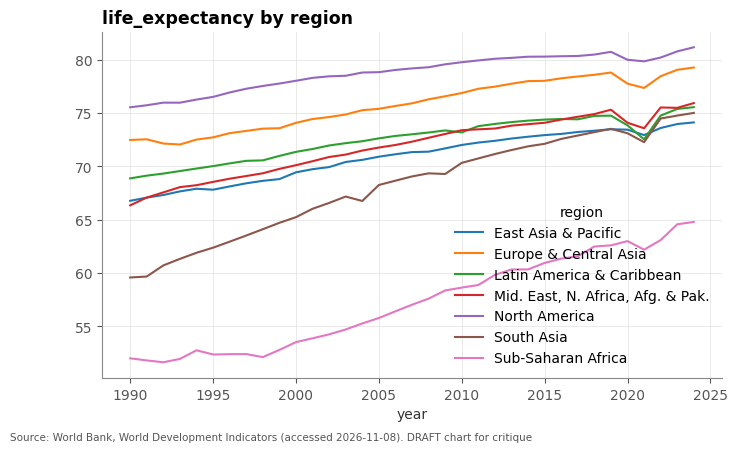

In [8]:
rough = df.groupby(["year", "region"]).life_expectancy.mean().unstack()
ax = rough.plot(figsize=(8, 4.5))
ax.set_title("life_expectancy by region")
fig = ax.get_figure()
save(fig, "p1_rough_draft", extra="DRAFT chart for critique")

**What I'd fix (critique)**
1. **The title says nothing.** "life_expectancy by region" just names the variables. A reader should get the finding from the title alone.
2. **The legend makes you look back and forth.** Seven colours matched against a box in the corner, and some of the default colours (green vs red, orange vs brown) blur together for colour-blind readers. Labels at the ends of the lines would be better.
3. **It's an unweighted mean of countries.** Tiny islands count as much as India. For a "how long do people in this region live" question, the average should be weighted by population. Also no units on the y axis, and the x label is just "year".

## 1.7 Interactive upgrade

Rebuilt with Plotly Express: population-weighted, labelled axes with units, a title that says something, and hover tooltips.

In [9]:
rw = pop_weighted(df, ["region", "year"])
lat_rw = rw[rw.year == LATEST].sort_values("life_expectancy")
gap = lat_rw.life_expectancy.iloc[-1] - lat_rw.life_expectancy.iloc[0]

fig = px.line(rw, x="year", y="life_expectancy", color="region", color_discrete_map=REGION_COLORS,
              category_orders={"region": list(lat_rw.region[::-1])},
              custom_data=["n_countries", "population"],
              labels={"life_expectancy": "Life expectancy at birth (years)", "year": "Year", "region": "Region"},
              title=f"Every region lives longer than in 1990, but a {gap:.0f}-year gap between regions remains ({LATEST})")
fig.update_traces(line=dict(width=2.5),
                  hovertemplate="<b>%{fullData.name}</b><br>%{x}: %{y:.1f} years<br>"
                                "%{customdata[0]} countries, %{customdata[1]:,.0f} people<extra></extra>")
save_plotly(fig, "p1_interactive_line", extra="Regional averages weighted by population")

**What hover adds.** In the static draft you can see the shape, but not the exact numbers, how many countries sit behind each line, or how many people. With the tooltip you can read the exact value in any year and check that North America is only two or three countries, which tells you how much to trust its line. You can also click a region in the legend to hide it, and the dip around 2020–21 is easy to inspect year by year.

**Reflection (Part 1).** Preparing the data took by far the longest: figuring out the API paging, the aggregates hiding in the country list, the "NA" for Namibia that pandas quietly turned into a missing value, and which year really counts as "latest". The chart itself was a few lines. Most of the work in visualization goes into the data before anything gets drawn, and mistakes there don't show up on the chart at all, they just make it wrong.

---
# Part 2: Perception, cognition and real-world use

## 2.1 Perception experiment

I took five countries spread across the life expectancy range (lowest, 25th percentile, median, 75th percentile, highest) and drew the same five values four ways. No numbers on the charts. Each classmate estimates *"how many times bigger is the largest value than the smallest?"* for each version.

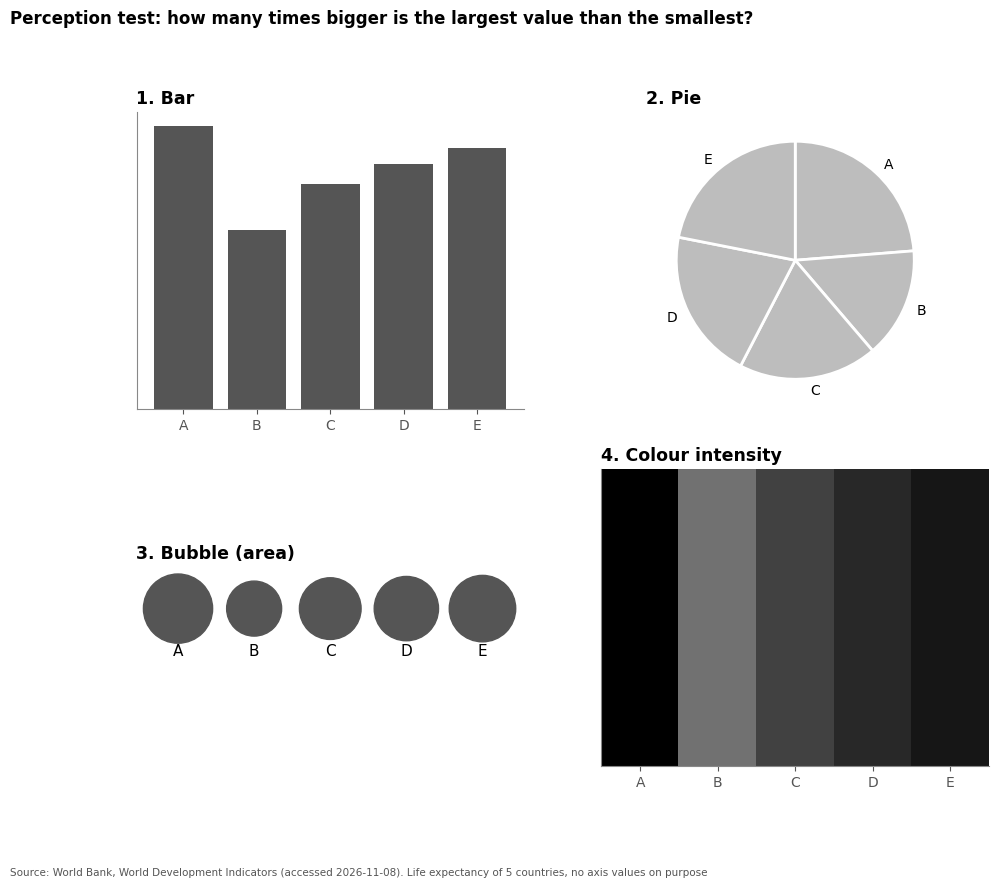

Answer key: {'A': 'Monaco', 'B': 'Nigeria', 'C': 'Bolivia', 'D': 'Bahamas', 'E': 'Panama'} → true ratio = 1.58


In [10]:
s = snap.sort_values("life_expectancy")
pick = s.iloc[[0, len(s) // 4, len(s) // 2, 3 * len(s) // 4, len(s) - 1]]
vals = pick.life_expectancy.values
letters = list("ABCDE")
order = np.random.default_rng(1).permutation(5)   # shuffle so position doesn't give the answer away
vals_shown, letters_shown = vals[order], [letters[i] for i in range(5)]
TRUE_RATIO = vals.max() / vals.min()

fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
ax = axes[0, 0]
ax.bar(letters_shown, vals_shown, color="#555555")
ax.set_yticks([]); ax.set_title("1. Bar"); ax.grid(False)
ax = axes[0, 1]
ax.pie(vals_shown, labels=letters_shown, colors=["#bdbdbd"] * 5, wedgeprops=dict(edgecolor="white", linewidth=2),
       startangle=90, counterclock=False)
ax.set_title("2. Pie")
ax = axes[1, 0]
for i, v in enumerate(vals_shown):
    ax.add_patch(Circle((i * 2.2, 0), np.sqrt(v / vals.max()) * 1.0, color="#555555"))
    ax.text(i * 2.2, -1.35, letters_shown[i], ha="center", fontsize=11)
ax.set_xlim(-1.2, 10); ax.set_ylim(-1.7, 1.2); ax.set_aspect("equal"); ax.axis("off"); ax.set_title("3. Bubble (area)")
ax = axes[1, 1]
ax.imshow(vals_shown[None, :], cmap="Greys", norm=Normalize(0, vals.max()), aspect="auto")
ax.set_xticks(range(5), letters_shown); ax.set_yticks([]); ax.grid(False); ax.set_title("4. Colour intensity")
fig.suptitle("Perception test: how many times bigger is the largest value than the smallest?",
             x=0.01, ha="left", fontweight="bold", y=1.0)
save(fig, "p2_perception_stimuli", extra="Life expectancy of 5 countries, no axis values on purpose")

print("Answer key:", dict(zip(letters_shown, pick.country.values[order])), f"→ true ratio = {TRUE_RATIO:.2f}")

**Recording the answers.** The first time this runs, it creates a blank `data/perception_responses.csv` with the participant and encoding columns already filled in. Type each answer into the `estimated_ratio` column and save (keep it as CSV). The notebook never overwrites this file once it exists. Add rows if you have more than five people. The encoding names must stay exactly `bar`, `pie`, `bubble (area)`, `colour strip`. Until that file has real numbers in it, the cell runs on **placeholder numbers** so nothing breaks, and the chart title says so loudly.

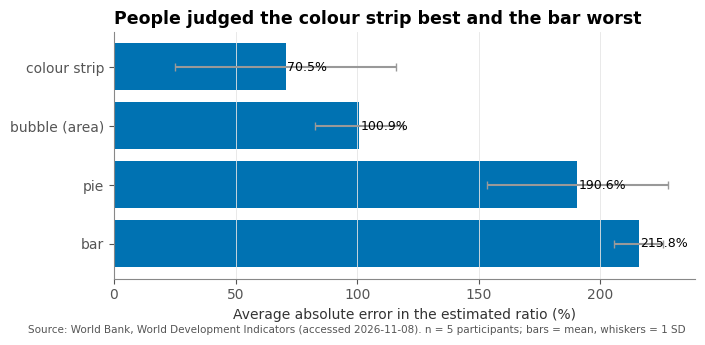

,mean,std,count
encoding,,,
colour strip,70.5,45.5,5
bubble (area),100.9,18.1,5
pie,190.6,37.1,5
bar,215.8,10.0,5


In [11]:
ENCODINGS = ["bar", "pie", "bubble (area)", "colour strip"]
resp_file = ROOT / "data" / "perception_responses.csv"

resp = (pd.read_csv(resp_file) if resp_file.exists()
        else pd.DataFrame(columns=["participant", "encoding", "estimated_ratio"]))
resp["encoding"] = resp["encoding"].astype(str).str.strip().str.lower()
resp["estimated_ratio"] = pd.to_numeric(resp["estimated_ratio"], errors="coerce")
resp = resp.dropna(subset=["estimated_ratio"])
odd = set(resp.encoding) - set(ENCODINGS)
if odd:
    print("These encoding names don't match and will be ignored, check the spelling:", odd)
resp = resp[resp.encoding.isin(ENCODINGS)]
PERCEPTION_PLACEHOLDER = len(resp) == 0

if PERCEPTION_PLACEHOLDER:
    if not resp_file.exists():          # blank form, made once and never overwritten after that
        pd.DataFrame([(p, e, None) for p in range(1, 6) for e in ENCODINGS],
                     columns=["participant", "encoding", "estimated_ratio"]).to_csv(resp_file, index=False)
    print("data/perception_responses.csv has no answers in it yet: fill in the estimated_ratio column. "
          "Placeholder numbers are used below until then.")
    # placeholder only: guesses get worse from bar → pie → area → colour, as in Cleveland & McGill.
    # replace with real answers
    rng = np.random.default_rng(7)
    model = {"bar": (1.0, 0.05), "pie": (0.9, 0.12), "bubble (area)": (0.7, 0.2), "colour strip": (0.5, 0.3)}
    resp = pd.DataFrame([(p, e, round(TRUE_RATIO ** k * rng.lognormal(0, sd), 2))
                         for p in range(1, 6) for e, (k, sd) in model.items()],
                        columns=["participant", "encoding", "estimated_ratio"])
    PERCEPTION_PLACEHOLDER = True

resp["abs_error_pct"] = (resp.estimated_ratio - TRUE_RATIO).abs() / TRUE_RATIO * 100
err = resp.groupby("encoding").abs_error_pct.agg(["mean", "std", "count"]).reindex(ENCODINGS).sort_values("mean")

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(err.index, err["mean"], xerr=err["std"], color="#0072B2", error_kw=dict(ecolor="#999999", capsize=3))
for y, v in enumerate(err["mean"]):
    ax.text(v + 0.5, y, f"{v:.1f}%", va="center", ha="left", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, None); ax.grid(axis="y", visible=False)
ax.set_xlabel("Average absolute error in the estimated ratio (%)")
worst = err.index[-1]
tag = "  [PLACEHOLDER DATA: replace with real answers]" if PERCEPTION_PLACEHOLDER else ""
ax.set_title(f"People judged the {err.index[0]} best and the {worst} worst{tag}")
save(fig, "p2_perception_results", extra=f"n = {resp.participant.nunique()} participants; bars = mean, whiskers = 1 SD")
err.round(1)

## 2.2 Pre-attentive pop-out

Two scatter plots of 60 points each.
- **Left:** the target is the only orange dot among blue dots. It differs by hue alone, so it should "pop out" right away.
- **Right:** a crowded field where the distractors are blue circles *and* orange squares, and the target is the only **orange circle**. It shares its hue with half the distractors and its shape with the other half, so you have to combine both features (a conjunction search), and that usually means scanning point by point.

Show each panel to a partner on its own, time how long they take to point at the target, and record it in `data/preattentive_timings.csv` (`partner, condition, seconds`, where condition is `hue` or `hue+shape`). The first time the next cell runs, it creates this file blank (never overwritten after that); just type the seconds in.

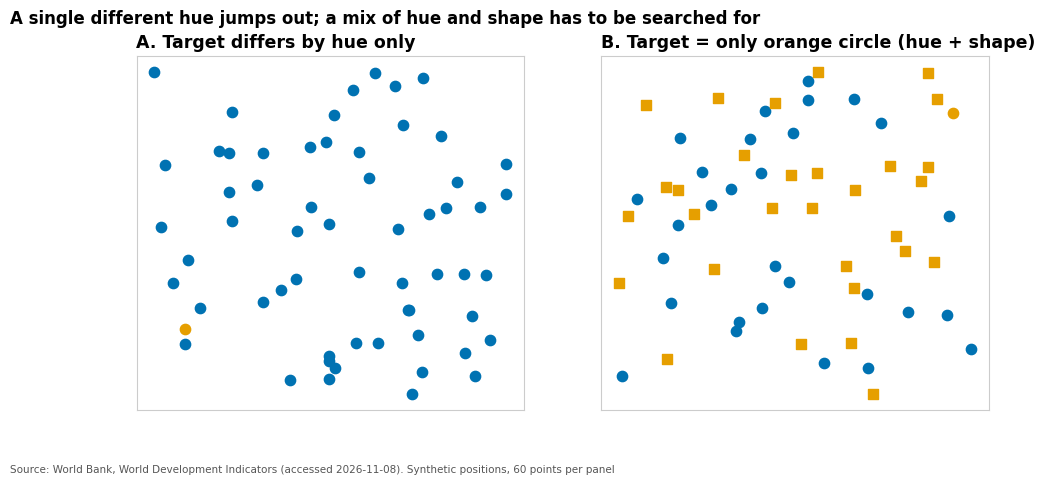

Answer key: A target at [0.9 2.4] | B target at [9.5 8.4]


In [12]:
rng = np.random.default_rng(3)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))

xy = rng.uniform(0, 10, size=(60, 2))
axes[0].scatter(xy[1:, 0], xy[1:, 1], s=55, color="#0072B2")
axes[0].scatter(*xy[0], s=55, color="#E69F00")
axes[0].set_title("A. Target differs by hue only")

xy2 = rng.uniform(0, 10, size=(60, 2))
half = 30
axes[1].scatter(xy2[1:half, 0], xy2[1:half, 1], s=55, color="#0072B2", marker="o")
axes[1].scatter(xy2[half:, 0], xy2[half:, 1], s=55, color="#E69F00", marker="s")
axes[1].scatter(*xy2[0], s=55, color="#E69F00", marker="o")
axes[1].set_title("B. Target = only orange circle (hue + shape)")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color("#cccccc")
fig.suptitle("A single different hue jumps out; a mix of hue and shape has to be searched for",
             x=0.01, ha="left", fontweight="bold")
save(fig, "p2_preattentive", extra="Synthetic positions, 60 points per panel")
print("Answer key: A target at", xy[0].round(1), "| B target at", xy2[0].round(1))

In [13]:
t_file = ROOT / "data" / "preattentive_timings.csv"
timings = (pd.read_csv(t_file) if t_file.exists()
           else pd.DataFrame(columns=["partner", "condition", "seconds"]))
timings["condition"] = timings["condition"].astype(str).str.strip().str.lower()
timings["seconds"] = pd.to_numeric(timings["seconds"], errors="coerce")
timings = timings.dropna(subset=["seconds"])
TIMING_PLACEHOLDER = len(timings) == 0

if TIMING_PLACEHOLDER:
    if not t_file.exists():             # blank form, made once and never overwritten after that
        pd.DataFrame([(p, c, None) for p in range(1, 6) for c in ["hue", "hue+shape"]],
                     columns=["partner", "condition", "seconds"]).to_csv(t_file, index=False)
    print("data/preattentive_timings.csv has no times in it yet: fill in the seconds column. "
          "Placeholder numbers are used below until then.")
    rng = np.random.default_rng(11)      # placeholder numbers, replace with real stopwatch times
    timings = pd.DataFrame([(p, "hue", round(rng.normal(0.7, 0.15), 2)) for p in range(1, 6)] +
                           [(p, "hue+shape", round(rng.normal(2.6, 0.8), 2)) for p in range(1, 6)],
                           columns=["partner", "condition", "seconds"])
    TIMING_PLACEHOLDER = True

summary = timings.groupby("condition").seconds.agg(["mean", "std", "count"]).round(2)
summary

,mean,std,count
condition,,,
hue,1.07,0.18,5
hue+shape,3.29,0.50,5


**Timing notes.** With the hue-only plot, most people should point at the target almost before you finish saying "go". Hue is processed pre-attentively, in parallel across the whole view. The conjunction version should take noticeably longer and vary more from person to person, because no single feature separates the target, so people check points in sequence. *(Write down anything odd that happened in your own test here, e.g. someone who spotted B quickly by luck.)*

## 2.3 Cognitive load audit

Before: a chart with every default "decoration" turned up. After: I removed everything that doesn't carry data.

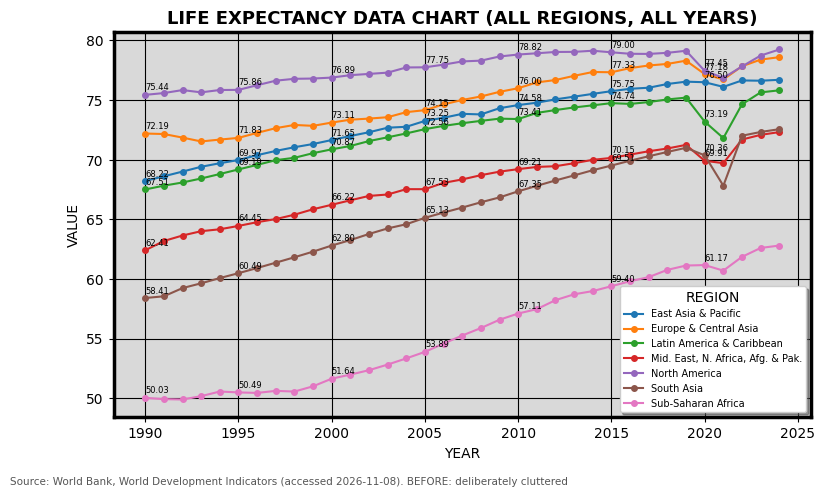

In [14]:
with plt.style.context("default"):
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.set_facecolor("#d9d9d9")
    for r in REGION_ORDER:
        d = rw[rw.region == r]
        ax.plot(d.year, d.life_expectancy, marker="o", markersize=4, linewidth=1.5, label=r)
        for _, row in d[d.year % 5 == 0].iterrows():
            ax.text(row.year, row.life_expectancy + 0.4, f"{row.life_expectancy:.2f}", fontsize=6)
    ax.grid(True, color="black", linewidth=0.8)
    ax.legend(title="REGION", loc="lower right", shadow=True, frameon=True, fontsize=7)
    for sp in ax.spines.values():
        sp.set_linewidth(2.5)
    ax.set_title("LIFE EXPECTANCY DATA CHART (ALL REGIONS, ALL YEARS)", fontsize=13, fontweight="bold")
    ax.set_xlabel("YEAR"); ax.set_ylabel("VALUE")
    save(fig, "p2_clutter_before", extra="BEFORE: deliberately cluttered")

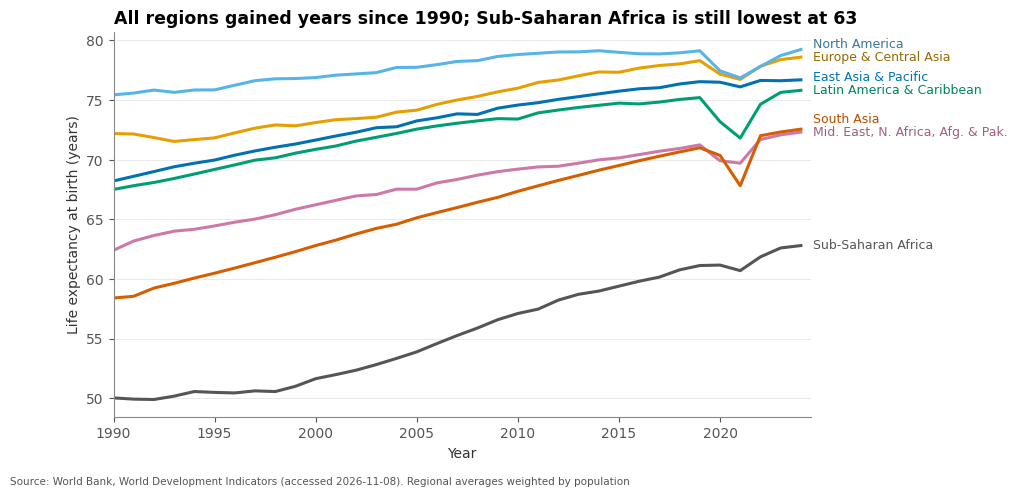

In [15]:
def region_lines(ax, data, ycol="life_expectancy", label_gap=1.1, lw=2.2):
    """population-weighted regional lines with labels at the right end instead of a legend"""
    ends = data[data.year == data.year.max()].set_index("region")[ycol]
    ypos = dict(zip(ends.index, spread(ends.values, label_gap)))
    for r in REGION_ORDER:
        d = data[data.region == r]
        if d.empty:
            continue
        ax.plot(d.year, d[ycol], color=REGION_COLORS[r], linewidth=lw)
        ax.text(d.year.max() + 0.6, ypos[r], r, color=REGION_TEXT[r], va="center", fontsize=9)
    ax.set_xlim(data.year.min(), data.year.max() + 0.5)

fig, ax = plt.subplots(figsize=(9, 5))
region_lines(ax, rw)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Life expectancy at birth (years)"); ax.set_xlabel("Year")
low = lat_rw.iloc[0]
ax.set_title(f"All regions gained years since 1990; {low.region} is still lowest at {low.life_expectancy:.0f}")
save(fig, "p2_clutter_after", extra="Regional averages weighted by population")

**What I removed and why:** the grey background (no data), the heavy black grid (now faint, horizontal only), the markers on every year (the line already shows the values), 2-decimal value labels every five years (nobody needs 67.43, and 40-odd labels compete with the lines), the boxed legend with a shadow (replaced by direct labels, so the eye doesn't have to jump), the shouting all-caps title and the thick frame. I also added what was missing: units on the y axis and a title that tells you the finding.

## 2.4 Real-world application brief: public health

When a paediatrician in Pakistan (or anywhere) checks whether a child is growing properly, they plot the child's height and weight on the **WHO Child Growth Standards** chart: age on the x axis, height on the y axis, with curved reference lines for the 3rd, 15th, 50th, 85th and 97th percentiles. The decision it supports is concrete and has real consequences. A child whose points fall below the 3rd-percentile line, or drop across two lines between visits, gets referred for stunting or malnutrition treatment. The chart works because of **position along a common scale**, the channel people read most accurately: the child's dot and the reference curves share the same axes, so "below the line" is judged instantly, without reading any numbers. The faint percentile curves against the darker plotted points also use **figure–ground**: the child's data stands out from the context. *(about 150 words)*

## 2.5 Interactive upgrade: overview first, zoom and filter, details on demand

- **Overview:** the clean regional lines from 2.3, nothing else on the canvas.
- **Zoom and filter:** a drop-down to show one region at a time, plus Plotly's zoom.
- **Details on demand:** number of countries, total population, and the lowest and highest country in that region-year all sit in the tooltip instead of cluttering the chart.

In [16]:
ext = (df.dropna(subset=["life_expectancy"])
         .sort_values("life_expectancy")
         .groupby(["region", "year"])
         .agg(lowest=("country", "first"), low_val=("life_expectancy", "first"),
              highest=("country", "last"), high_val=("life_expectancy", "last"))
         .reset_index())
rwx = rw.merge(ext, on=["region", "year"])

fig = go.Figure()
for r in REGION_ORDER:
    d = rwx[rwx.region == r]
    fig.add_trace(go.Scatter(
        x=d.year, y=d.life_expectancy, name=r, mode="lines", line=dict(color=REGION_COLORS[r], width=2.5),
        customdata=np.stack([d.n_countries, d.population / 1e6, d.lowest, d.low_val, d.highest, d.high_val], axis=-1),
        hovertemplate="<b>" + r + "</b>, %{x}<br>Average: %{y:.1f} years<br>%{customdata[0]} countries, "
                      "%{customdata[1]:,.0f} million people<br>Lowest: %{customdata[2]} (%{customdata[3]:.1f})"
                      "<br>Highest: %{customdata[4]} (%{customdata[5]:.1f})<extra></extra>"))

buttons = [dict(label="All regions", method="update", args=[{"visible": [True] * len(REGION_ORDER)}])]
for i, r in enumerate(REGION_ORDER):
    buttons.append(dict(label=r, method="update",
                        args=[{"visible": [j == i for j in range(len(REGION_ORDER))]}]))
fig.update_layout(
    title=f"Life expectancy by region, 1990–{LATEST}: pick a region, hover for the details",
    xaxis_title="Year", yaxis_title="Life expectancy at birth (years)", hovermode="closest",
    updatemenus=[dict(buttons=buttons, direction="down", x=1.0, xanchor="right", y=1.12, yanchor="top")])
save_plotly(fig, "p2_overview_detail", extra="Regional averages weighted by population")

**Why this lowers cognitive load.** The first thing you see is seven lines and nothing else, so working memory only has to hold one idea: *everyone went up, the gaps stayed*. The secondary values (counts, extremes, population) are still there, but you only pay the cost of reading them when you ask for them by hovering. The filter lets a reader shrink the problem to one region instead of untangling seven lines in their head.

**Reflection (Part 2).** *(Answer once you have your real experiment results.)* In most versions of this test, the colour strip and bubble area are read least accurately. People underestimate area differences and can barely rank shades of grey, let alone estimate ratios. For any comparison where the size of the difference matters, I'd use bars or dots on a common axis instead.

---
# Part 3: Visual encoding and Gestalt principles

## 3.1 Encoding map

Cleveland & McGill's ranking, from most to least accurate: position on a common scale → position on unaligned scales → length → angle/slope → area → colour lightness/saturation → colour hue (hue is great for *categories*, bad for *amounts*).

| field | type | channel I use | why |
|---|---|---|---|
| life_expectancy (outcome) | ratio | **y position** | it's the thing I most want people to read precisely, so it gets the best channel |
| gdp_per_capita | ratio | **x position (log scale)** | second most important variable, so the second position axis; log because the values span 100× |
| population | ratio | **area** | less accurate, but fine for "big vs small country" context; it's only the backdrop |
| region (category) | nominal | **colour hue** (+ marker shape) | hue has no natural order, which matches nominal data; shape backs it up for colour-blind readers |
| income_group | ordinal | **colour lightness** (dark → light) | lightness has an order, like the income groups do |
| year (time) | interval | **x position** in line charts, **animation frame** in the bubble chart | time reads naturally left to right |
| internet_users_pct | ratio | **colour lightness** in heatmaps | used when position is already taken by two other variables |

## 3.2 One comparison, three encodings

Life expectancy in the 10 most populous countries.

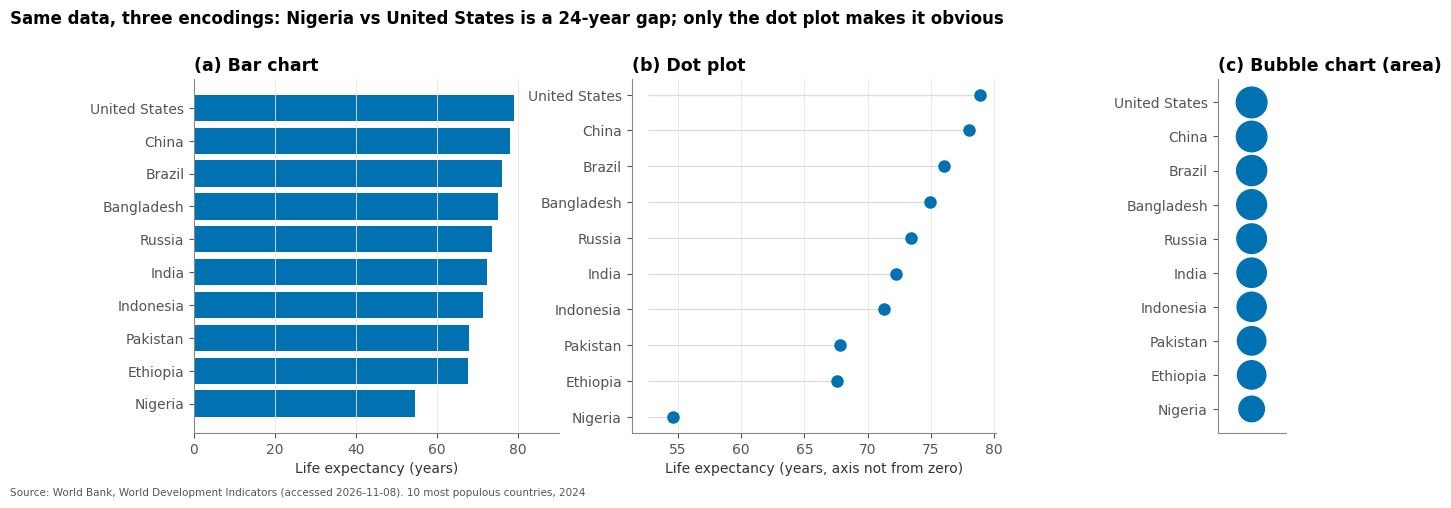

In [17]:
top10 = snap.nlargest(10, "population").sort_values("life_expectancy")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

ax = axes[0]
ax.barh(top10.country, top10.life_expectancy, color="#0072B2")
ax.set_xlim(0, 90); ax.grid(axis="y", visible=False)
ax.set_xlabel("Life expectancy (years)"); ax.set_title("(a) Bar chart")

ax = axes[1]
ax.hlines(top10.country, top10.life_expectancy.min() - 2, top10.life_expectancy, color="#dddddd", linewidth=1)
ax.plot(top10.life_expectancy, top10.country, "o", color="#0072B2", markersize=8)
ax.set_xlabel("Life expectancy (years, axis not from zero)"); ax.set_title("(b) Dot plot")
ax.grid(axis="y", visible=False)

ax = axes[2]
for i, (_, row) in enumerate(top10.iterrows()):
    r = np.sqrt(row.life_expectancy / top10.life_expectancy.max()) * 0.45
    ax.add_patch(Circle((0, i), r, color="#0072B2"))
ax.set_xlim(-1, 1); ax.set_ylim(-0.7, 9.7); ax.set_aspect("equal")
ax.set_yticks(range(10), top10.country); ax.set_xticks([]); ax.grid(False)
ax.set_title("(c) Bubble chart (area)")
fig.suptitle(f"Same data, three encodings: {top10.country.iloc[0]} vs {top10.country.iloc[-1]} is a "
             f"{top10.life_expectancy.iloc[-1] - top10.life_expectancy.iloc[0]:.0f}-year gap; only the dot plot makes it obvious",
             x=0.01, ha="left", fontweight="bold", y=1.03)
save(fig, "p3_three_encodings", extra=f"10 most populous countries, {LATEST}")

**My ranking for readability: (b) dot plot > (a) bar chart > (c) bubbles.**
- The **dot plot** uses position only, and because dots don't encode length, the axis doesn't need to start at zero. It can zoom in on the 60–85 range where the differences actually are, so a 10-year gap looks like a 10-year gap.
- The **bar chart** is honest and easy to read, but it has to start at zero (length encodes value), so all the bars look long and nearly the same. You can still compare them; the differences just look small.
- The **bubbles** are the worst: area is judged badly, and on top of that the differences shrink under the square root. Countries several years apart end up looking the same size, so you can't rank the middle of the list without guessing.

## 3.3 Gestalt redesign: small multiples

One panel per region (the six regions with the most countries; North America has only 2–3 economies, so it's left out of this figure). In each panel there's one line per income group, the population-weighted life expectancy.

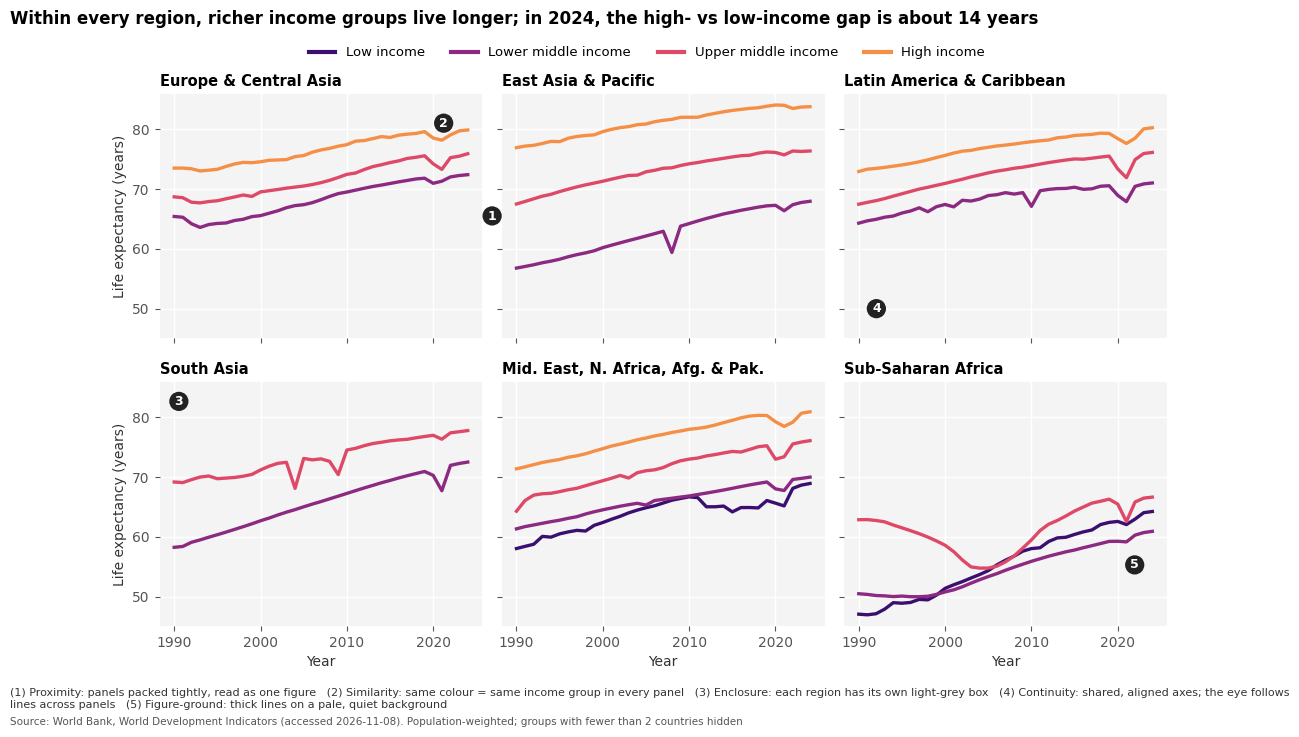

In [18]:
sm = pop_weighted(df[df.income_group.isin(INCOME_ORDER)], ["region", "income_group", "year"])
sm = sm[sm.n_countries >= 2]       # a one-country "group" isn't really a group
panel_regions = df.groupby("region").iso3.nunique().sort_values(ascending=False).index[:6].tolist()
panel_regions = sorted(panel_regions, key=lambda r: -lat_rw.set_index("region").life_expectancy.get(r, 0))

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True,
                         gridspec_kw=dict(wspace=0.06, hspace=0.18))
for ax, reg in zip(axes.flat, panel_regions):
    ax.set_facecolor("#f4f4f4")                                  # enclosure
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.grid(color="white", linewidth=1)                          # figure-ground: grid sits behind and is faint
    for ig in INCOME_ORDER:
        d = sm[(sm.region == reg) & (sm.income_group == ig)]
        if len(d):
            ax.plot(d.year, d.life_expectancy, color=INCOME_COLORS[ig], linewidth=2.4)
    ax.set_title(reg, fontsize=10.5, loc="left", fontweight="bold")
for ax in axes[:, 0]:
    ax.set_ylabel("Life expectancy (years)")
for ax in axes[-1]:
    ax.set_xlabel("Year")

handles = [plt.Line2D([], [], color=INCOME_COLORS[i], linewidth=3) for i in INCOME_ORDER]
fig.legend(handles, INCOME_ORDER, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.965), fontsize=9.5)

# numbered markers showing where each principle is applied
notes = {1: "Proximity: panels packed tightly, read as one figure",
         2: "Similarity: same colour = same income group in every panel",
         3: "Enclosure: each region has its own light-grey box",
         4: "Continuity: shared, aligned axes; the eye follows lines across panels",
         5: "Figure-ground: thick lines on a pale, quiet background"}
spots = [(axes[0, 1], -0.03, 0.5), (axes[0, 0], 0.88, 0.88), (axes[1, 0], 0.06, 0.92), (axes[0, 2], 0.1, 0.12), (axes[1, 2], 0.9, 0.25)]
for (k, txt), (ax, x, y) in zip(notes.items(), spots):
    ax.text(x, y, str(k), transform=ax.transAxes, ha="center", va="center", fontsize=9, fontweight="bold",
            color="white", bbox=dict(boxstyle="circle,pad=0.25", fc="#222222", ec="none"), zorder=10, clip_on=False)
fig.text(0.01, 0.005, "   ".join(f"({k}) {t}" for k, t in notes.items()), fontsize=8, color="#333333", wrap=True)

hi = sm[sm.year == sm.year.max()].groupby("income_group").life_expectancy.mean().reindex(INCOME_ORDER)
fig.suptitle(f"Within every region, richer income groups live longer; in {LATEST}, the high- vs low-income gap "
             f"is about {hi.iloc[-1] - hi.iloc[0]:.0f} years", x=0.01, ha="left", fontweight="bold", y=1.0)
fig.subplots_adjust(bottom=0.12)
save(fig, "p3_gestalt_small_multiples", extra="Population-weighted; groups with fewer than 2 countries hidden")

## 3.4 Breaking it on purpose

Same data, but I violate **similarity** (each panel shuffles which colour means which income group), **continuity** (every panel gets its own y axis range) and **proximity** (panels spread out unevenly), and I wreck the **figure–ground** with dark backgrounds and heavy grid lines.

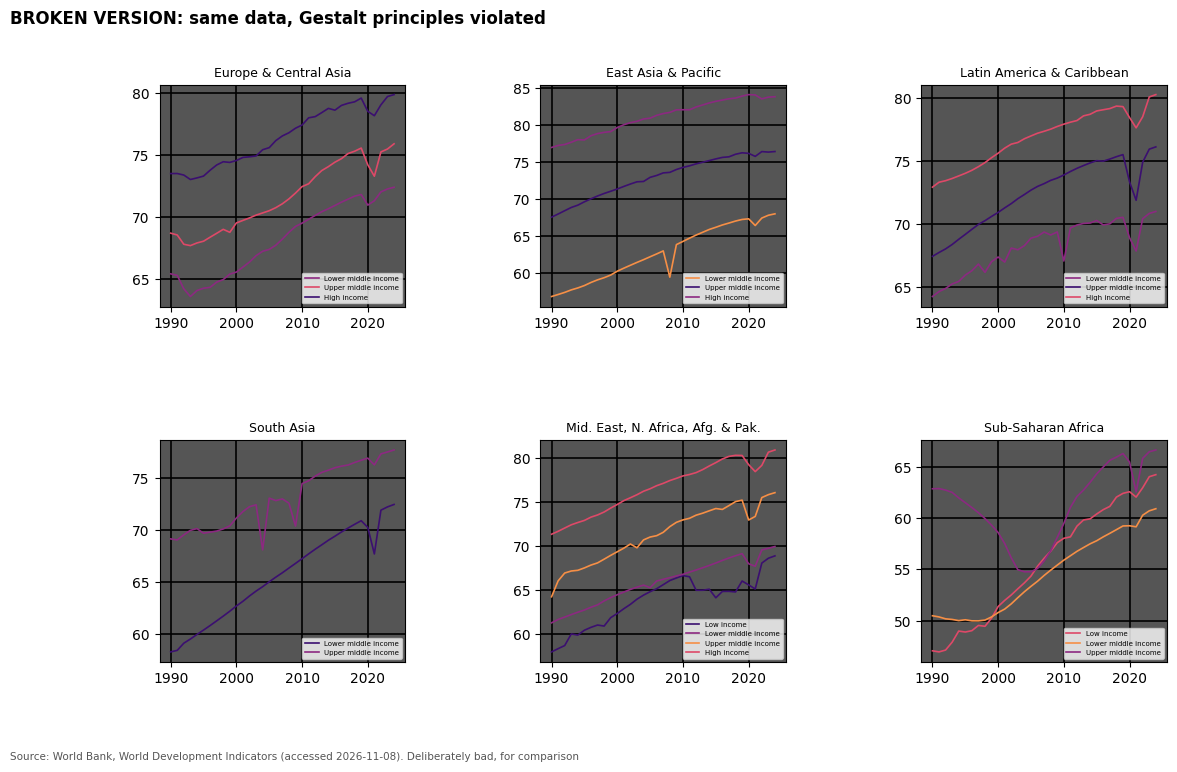

In [19]:
rng = np.random.default_rng(5)
with plt.style.context("default"):
    fig, axes = plt.subplots(2, 3, figsize=(13, 7.5), gridspec_kw=dict(wspace=0.55, hspace=0.6))
    base_cols = list(INCOME_COLORS.values())[:4]
    for ax, reg in zip(axes.flat, panel_regions):
        cols = rng.permutation(base_cols)                     # colours mean different things in each panel
        ax.set_facecolor("#555555")
        ax.grid(color="black", linewidth=1.2)
        for ig, c in zip(INCOME_ORDER, cols):
            d = sm[(sm.region == reg) & (sm.income_group == ig)]
            if len(d):
                ax.plot(d.year, d.life_expectancy, color=c, linewidth=1.2, label=ig)
        ax.set_title(reg, fontsize=9)
        ax.legend(fontsize=5, loc="lower right")
    fig.suptitle("BROKEN VERSION: same data, Gestalt principles violated", x=0.01, ha="left", fontweight="bold")
    save(fig, "p3_gestalt_broken", extra="Deliberately bad, for comparison")

**What goes wrong:**
- **Similarity broken.** Purple means "low income" in one panel and "high income" in the next, so the reader has to re-learn the legend six times. Comparing the same group across regions, which was the whole point of small multiples, becomes a memory test.
- **Continuity broken.** Each panel has its own y range, so a line that looks "high" in one panel may be lower than a "low" line in the next. Since the axes don't line up, the eye can't move across panels.
- **Proximity broken.** Big, uneven gaps make the panels look like six separate charts rather than one figure.
- **Figure–ground broken.** Thin lines on a dark grey background with a black grid: the data is now the *least* visible thing on the chart.

## 3.5 Interactive upgrade: linked highlighting (Altair)

Hover over a line (or click a legend entry) and that income group lights up in *every* panel at once, while everything else fades.

In [20]:
sm_alt = sm[sm.region.isin(panel_regions)].copy()
sm_alt = sm_alt.astype({"region": object, "income_group": object})   # plain strings keep Altair happy
sm_alt["life_expectancy"] = sm_alt.life_expectancy.round(2)

hl = alt.selection_point(fields=["income_group"], on="mouseover", clear="mouseout", bind="legend")
lines = (alt.Chart(sm_alt)
         .mark_line(strokeWidth=3)
         .encode(x=alt.X("year:Q", title="Year", axis=alt.Axis(format="d")),
                 y=alt.Y("life_expectancy:Q", title="Life expectancy (years)", scale=alt.Scale(zero=False)),
                 color=alt.Color("income_group:N", title="Income group",
                                 scale=alt.Scale(domain=INCOME_ORDER, range=[INCOME_COLORS[i] for i in INCOME_ORDER])),
                 opacity=alt.condition(hl, alt.value(1), alt.value(0.12)),
                 tooltip=[alt.Tooltip("region:N", title="Region"), alt.Tooltip("income_group:N", title="Income group"),
                          alt.Tooltip("year:Q", title="Year"),
                          alt.Tooltip("life_expectancy:Q", title="Life expectancy", format=".1f"),
                          alt.Tooltip("n_countries:Q", title="Countries")])
         .add_params(hl)
         .properties(width=230, height=150))
linked = (lines.facet(facet=alt.Facet("region:N", title=None, sort=panel_regions), columns=3)
          .properties(title={"text": "Hover over a line: the same income group lights up in every region",
                             "subtitle": SOURCE + ". Population-weighted averages."}))
linked.save(str(FIG / "p3_linked_highlight.html"))
linked

alt.FacetChart(...)

**Which principles the interaction reinforces.** **Similarity**: same colour, same group, and now the highlight makes that link explicit, because one hover lights up six lines that are all "the same thing". **Common fate**: elements that change together are seen as a group. When the six highlighted lines brighten together while the rest fade together, your eye groups them without effort, so comparing "lower-middle income in South Asia vs in Africa" becomes a single glance.

**Reflection (Part 3).** I instinctively wanted the bubble chart in 3.2 because it "looks nicer", and my first idea for the income groups was four bright, unrelated hues. The ranking pushed back both times: bubbles lose to position, and an ordered category should get an ordered colour (lightness), not a rainbow of hues.

---
# Part 4: Colour, accessibility and misleading charts

## 4.1 Three palette types

- **Qualitative** → *region*: groups with no order, so the colours should differ in hue without any looking "more" than another.
- **Sequential** → *internet users %*: runs from low to high, so the colour should run from light to dark (one direction, even steps).
- **Diverging** → *difference from the world median*: has a meaningful midpoint (zero), so two hues go out from a neutral middle.

For the qualitative chart I show a **before** (matplotlib's default `tab10`, legend only) and an **after** (Okabe-Ito + direct labels), because the audit below finds a problem with the first.

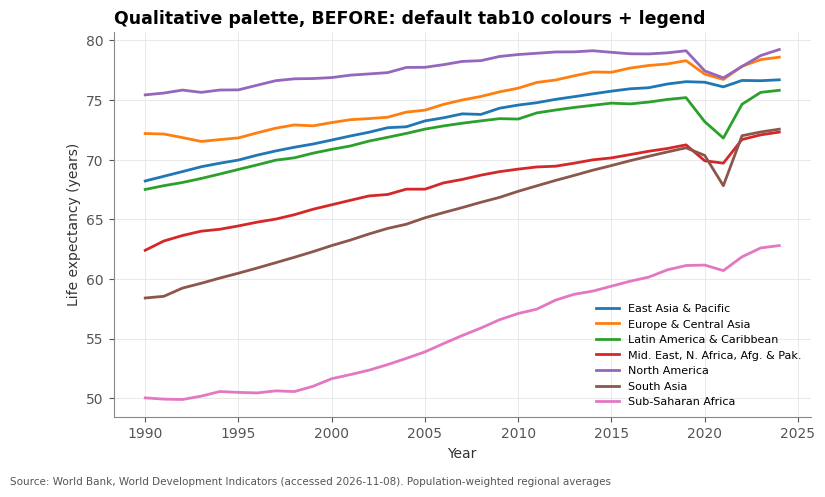

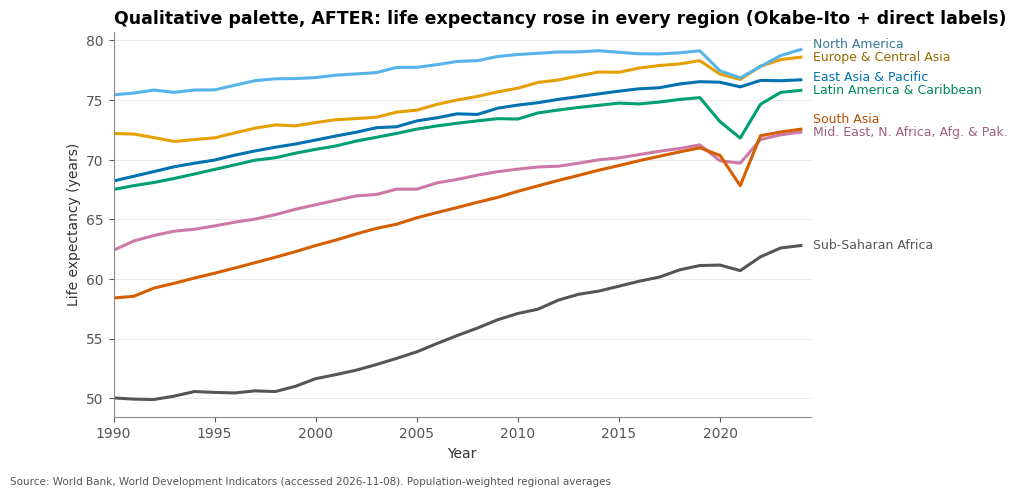

In [21]:
TAB10 = [to_hex(c) for c in plt.cm.tab10.colors[:len(REGION_ORDER)]]

fig, ax = plt.subplots(figsize=(9, 5))
for r, c in zip(REGION_ORDER, TAB10):
    d = rw[rw.region == r]
    ax.plot(d.year, d.life_expectancy, color=c, linewidth=2, label=r)
ax.legend(fontsize=8, loc="lower right")
ax.set_ylabel("Life expectancy (years)"); ax.set_xlabel("Year")
ax.set_title("Qualitative palette, BEFORE: default tab10 colours + legend")
save(fig, "p4_qualitative_before", extra="Population-weighted regional averages")

fig, ax = plt.subplots(figsize=(9, 5))
region_lines(ax, rw)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Life expectancy (years)"); ax.set_xlabel("Year")
ax.set_title("Qualitative palette, AFTER: life expectancy rose in every region (Okabe-Ito + direct labels)")
save(fig, "p4_qualitative_after", extra="Population-weighted regional averages")

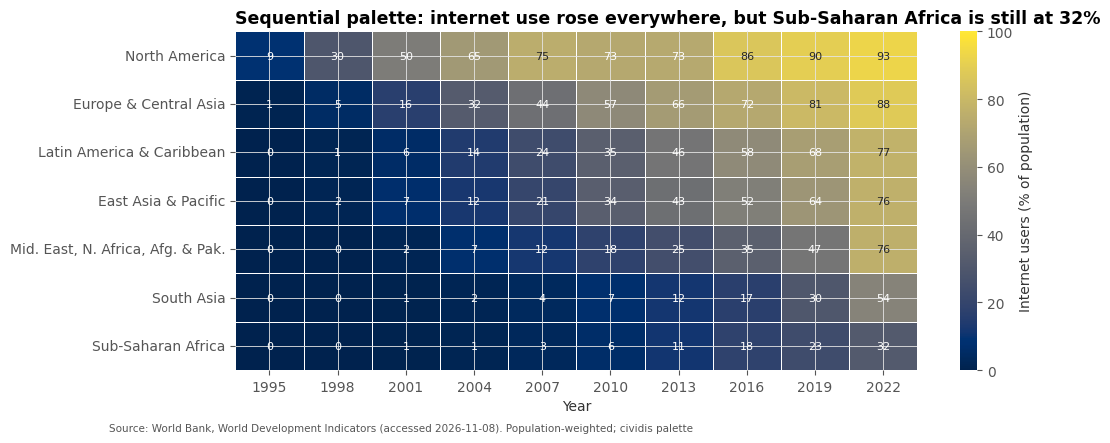

In [22]:
yrs = list(range(1995, LATEST + 1, 3))
net = pop_weighted(df[df.year.isin(yrs)], ["region", "year"], col="internet_users_pct")
heat = net.pivot(index="region", columns="year", values="internet_users_pct")
heat = heat.loc[heat[heat.columns[-1]].sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 4.4))
sns.heatmap(heat, cmap="cividis", vmin=0, vmax=100, annot=True, fmt=".0f", linewidths=0.5, linecolor="white",
            cbar_kws=dict(label="Internet users (% of population)"), ax=ax, annot_kws=dict(fontsize=8))
ax.set_xlabel("Year"); ax.set_ylabel("")
last = heat.iloc[:, -1]
ax.set_title(f"Sequential palette: internet use rose everywhere, but {last.idxmin()} is still at {last.min():.0f}%")
save(fig, "p4_sequential", extra="Population-weighted; cividis palette")

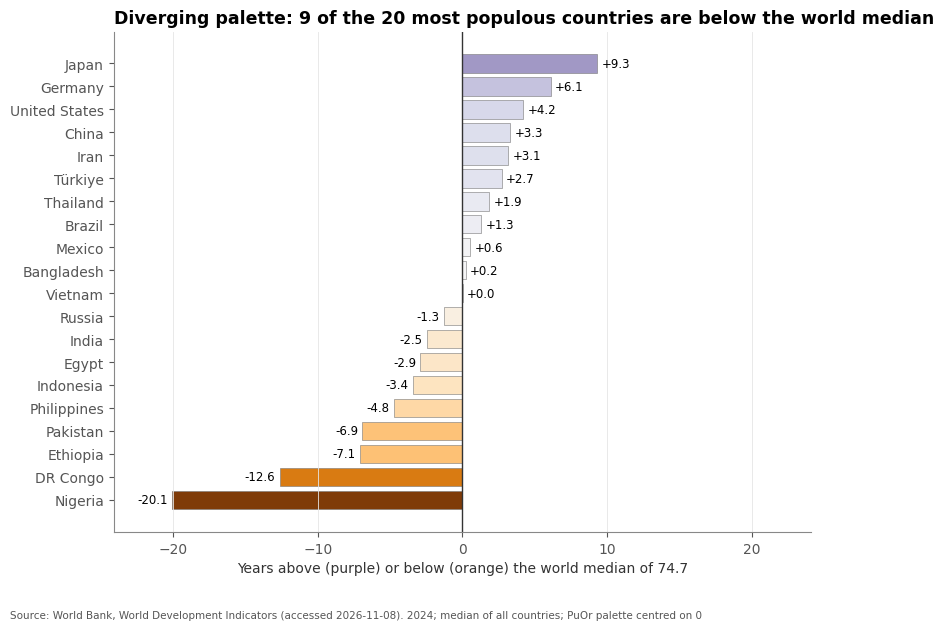

In [23]:
world_med = snap.life_expectancy.median()
big = snap.nlargest(20, "population").assign(diff=lambda d: d.life_expectancy - world_med).sort_values("diff")
lim = big["diff"].abs().max()
norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
cmap = mpl.colormaps["PuOr"]

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(big.country, big["diff"], color=cmap(norm(big["diff"].values)), edgecolor="#777777", linewidth=0.4)
ax.axvline(0, color="#333333", linewidth=1)
for y, v in enumerate(big["diff"]):
    ax.text(v + (0.3 if v >= 0 else -0.3), y, f"{v:+.1f}", va="center", ha="left" if v >= 0 else "right", fontsize=8.5)
ax.set_xlim(-lim * 1.2, lim * 1.2); ax.grid(axis="y", visible=False)
ax.set_xlabel(f"Years above (purple) or below (orange) the world median of {world_med:.1f}")
n_below = (big["diff"] < 0).sum()
ax.set_title(f"Diverging palette: {n_below} of the 20 most populous countries are below the world median")
save(fig, "p4_diverging", extra=f"{LATEST}; median of all countries; PuOr palette centred on 0")

## 4.2 Accessibility audit

Three checks:
1. **Colour-vision simulation**, run on the actual PNG files (deuteranopia, protanopia, tritanopia), plus **grayscale**.
2. **Palette distance**: the smallest colour difference (CIE ΔE) between any two colours in a palette under each type of vision. As a rough rule, below ~10 two colours are hard to tell apart for small marks like thin lines.
3. **Text contrast** against WCAG 2.1, which needs at least 4.5:1 for normal text.

,normal,deuteranopia,protanopia,tritanopia,grayscale
tab10 (before),27.7,7.3,4.6,17.9,1.1
Okabe-Ito (after),26.4,17.9,20.7,16.1,0.8
"cividis, 5 steps",23.3,23.9,21.4,17.9,18.6
"PuOr, 5 steps",43.4,42.8,43.3,35.8,10.5


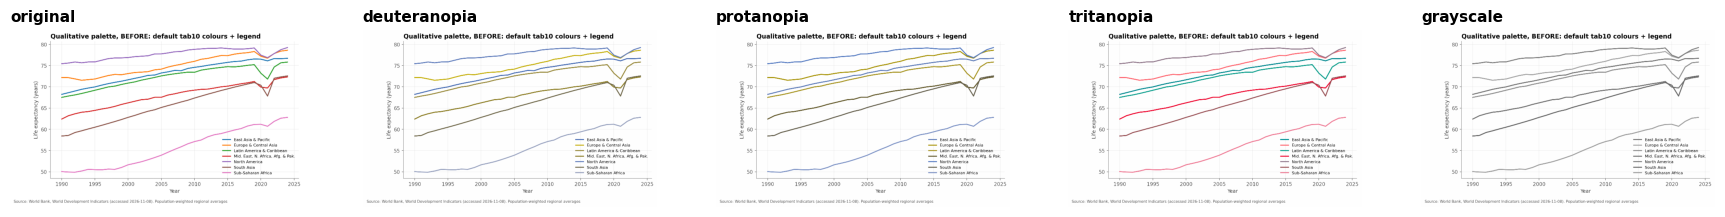

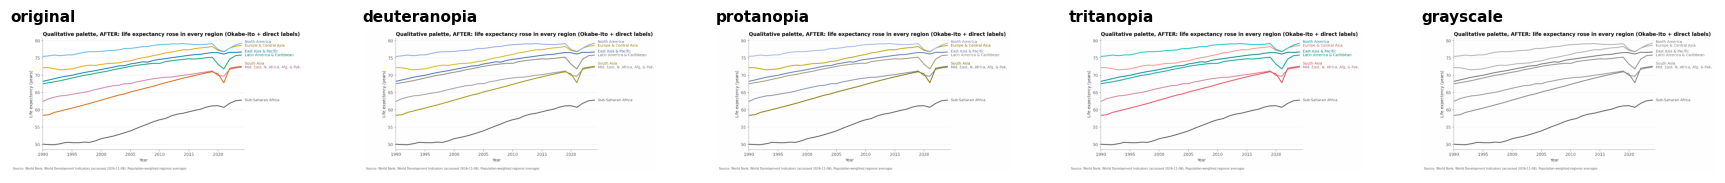

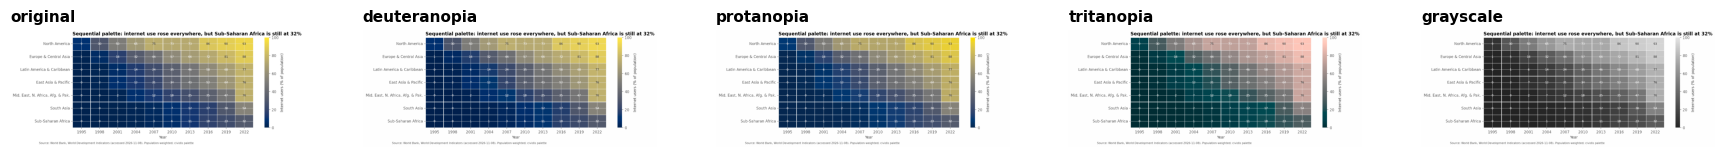

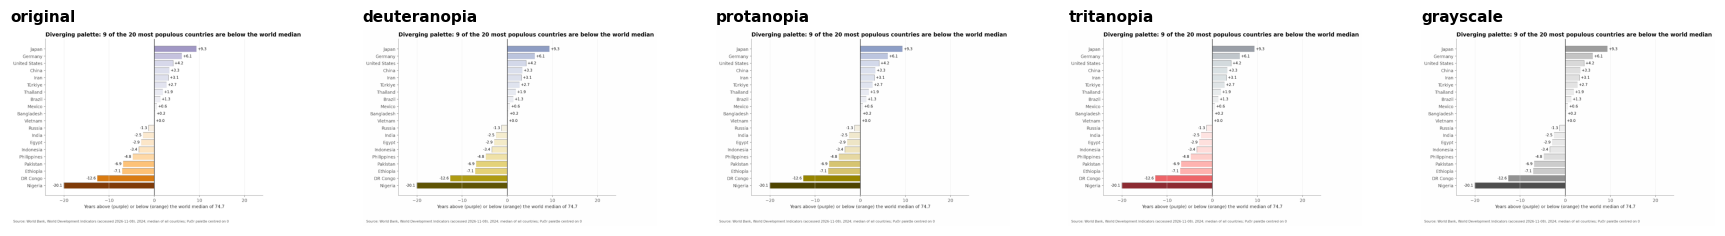

In [24]:
seq5 = [to_hex(mpl.colormaps["cividis"](x)) for x in np.linspace(0, 1, 5)]
div5 = [to_hex(mpl.colormaps["PuOr"](x)) for x in np.linspace(0, 1, 5)]
pal = pd.concat([palette_check(TAB10, "tab10 (before)"), palette_check(OKABE[:len(REGION_ORDER)], "Okabe-Ito (after)"),
                 palette_check(seq5, "cividis, 5 steps"), palette_check(div5, "PuOr, 5 steps")], axis=1).T
display(pal.style.background_gradient(cmap="Greys", vmin=0, vmax=40, axis=None).format("{:.1f}"))

for name in ["p4_qualitative_before", "p4_qualitative_after", "p4_sequential", "p4_diverging"]:
    cvd_sheet(name, show=True)

**Reading the audit.**
- **tab10 (before)** has the lowest ΔE under deuteranopia and protanopia: its green and red (and orange vs brown) collapse into similar olive tones. In the simulated "before" image some lines can only be told apart by their order. Since that chart relies on a legend matched by colour alone, it **fails**.
- **Okabe-Ito (after)** keeps a larger minimum difference under all three types of colour blindness. No qualitative palette survives grayscale (that's expected, hue simply isn't there in grayscale), which is exactly why the fixed chart also has **direct labels**: the line's name sits on the line, so colour isn't the only cue. That's the redundant encoding.
- **cividis** and **PuOr** keep their order in every simulation and in grayscale, because cividis was designed for colour-blind readers and PuOr's two arms differ in lightness, not just hue.

In [25]:
text_colours = {"titles / axis labels (#333333)": "#333333", "tick labels, source note (#555555)": "#555555"}
for r in REGION_ORDER:
    text_colours[f"label '{r}', raw colour {REGION_COLORS[r]}"] = REGION_COLORS[r]
    text_colours[f"label '{r}', fixed {REGION_TEXT[r]}"] = REGION_TEXT[r]
ct = pd.DataFrame({"contrast vs white": {k: round(contrast(v), 2) for k, v in text_colours.items()}})
ct["WCAG AA (≥ 4.5)"] = np.where(ct["contrast vs white"] >= 4.5, "pass", "FAIL")
ct

,contrast vs white,WCAG AA (≥ 4.5)
titles / axis labels (#333333),12.63,pass
"tick labels, source note (#555555)",7.46,pass
"label 'East Asia & Pacific', raw colour #0072B2",5.19,pass
"label 'East Asia & Pacific', fixed #0072b2",5.19,pass
"label 'Europe & Central Asia', raw colour #E69F00",2.25,FAIL
"label 'Europe & Central Asia', fixed #986900",4.82,pass
"label 'Latin America & Caribbean', raw colour #009E73",3.42,FAIL
"label 'Latin America & Caribbean', fixed #008661",4.58,pass
"label 'Mid. East, N. Africa, Afg. & Pak.', raw colour #CC79A7",3.06,FAIL
"label 'Mid. East, N. Africa, Afg. & Pak.', fixed #9f5e82",4.78,pass


**Contrast fix.** Several of the Okabe-Ito colours are fine for *lines* but too light for *text*. The orange and sky blue come out at about 2:1 against white. So the direct labels use a darkened version of each region's colour (`readable()` darkens it step by step until it reaches 4.5:1). It's still clearly the same hue as its line, but now it's legible. All axis and source text is #333/#555, which passes comfortably.

## 4.3 Misleading chart gallery

Six bad-vs-fixed pairs. Every bad version is stamped **MISLEADING** so it can't be mistaken for a real chart; none of them is used anywhere else in the project.

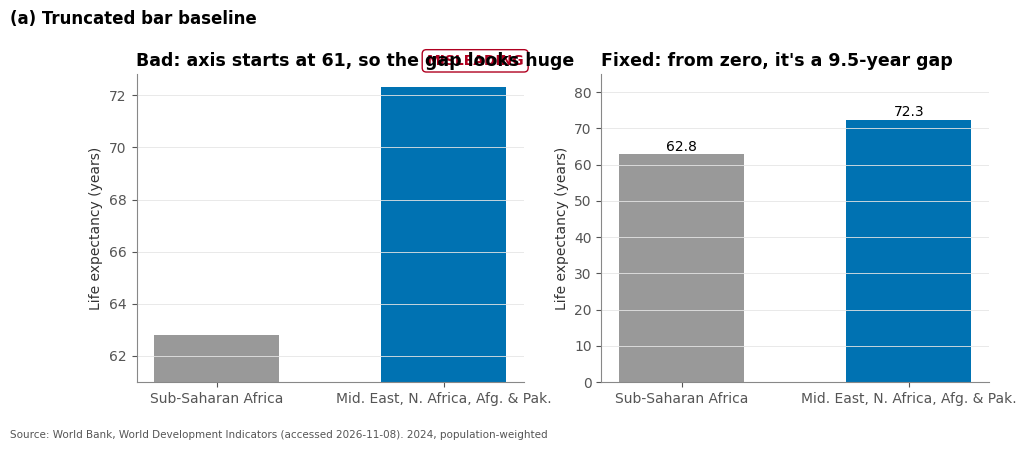

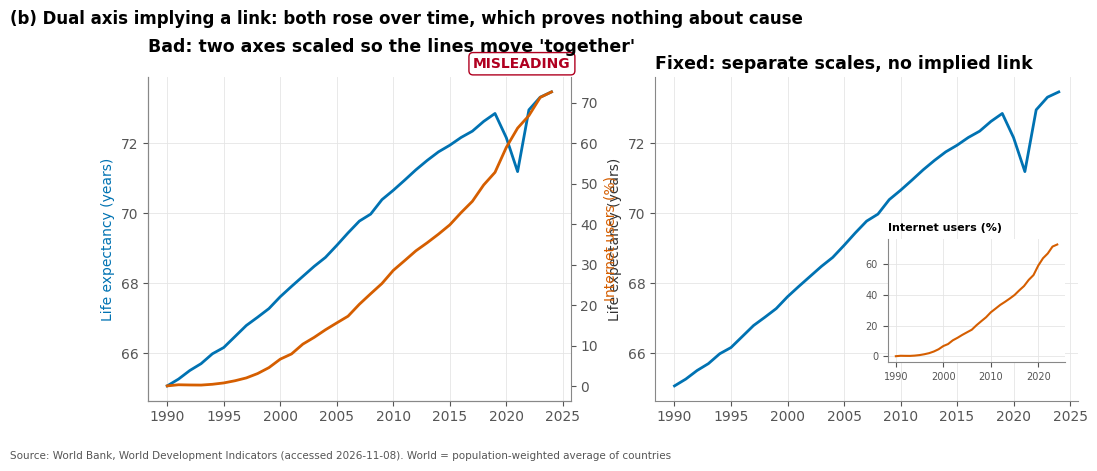

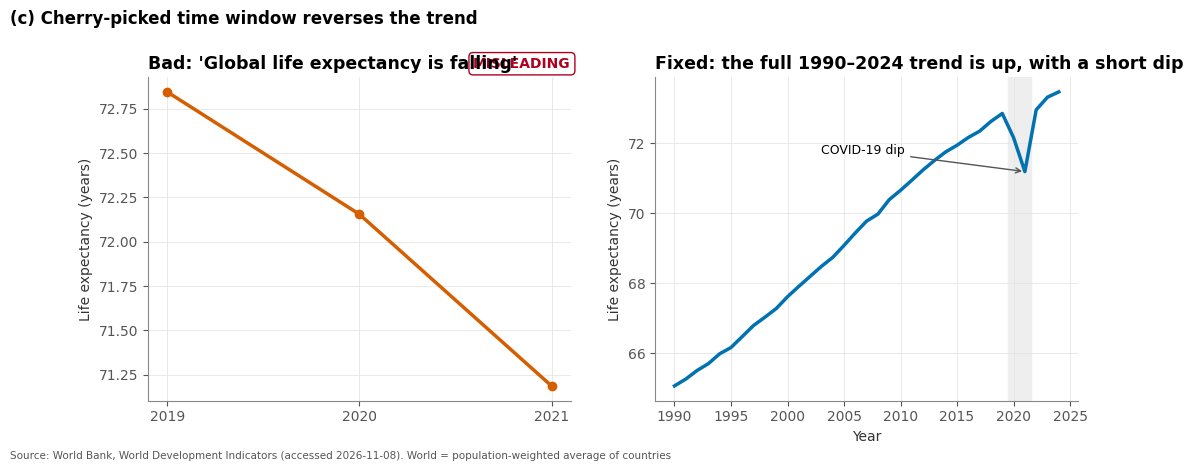

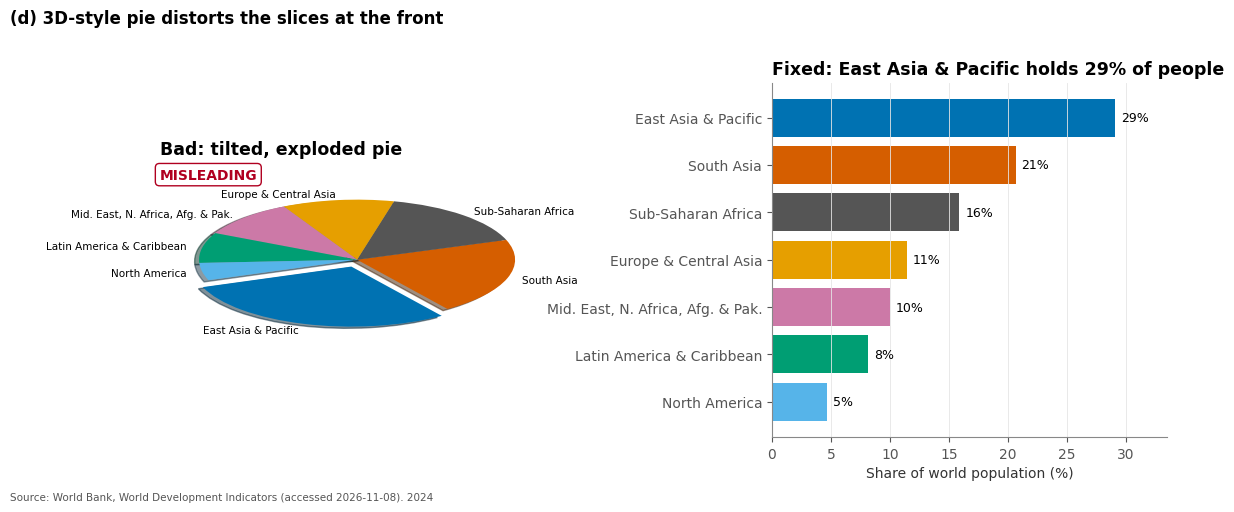

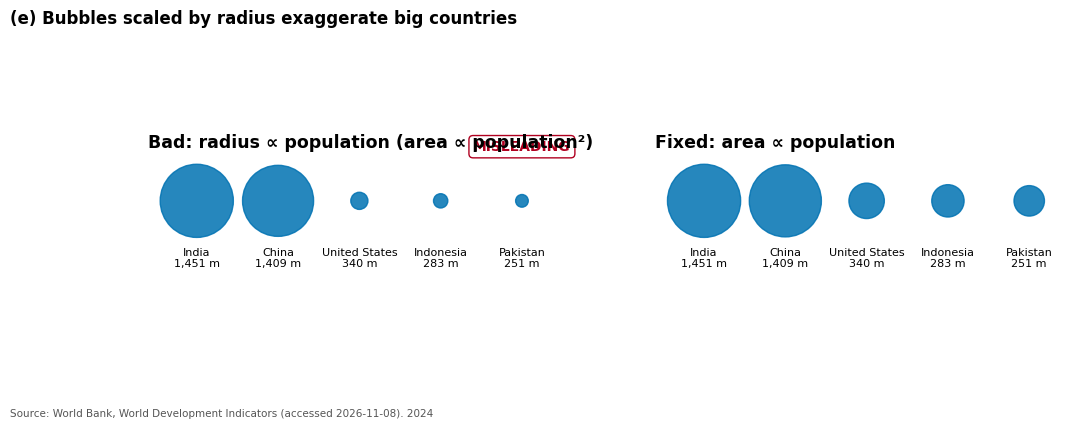

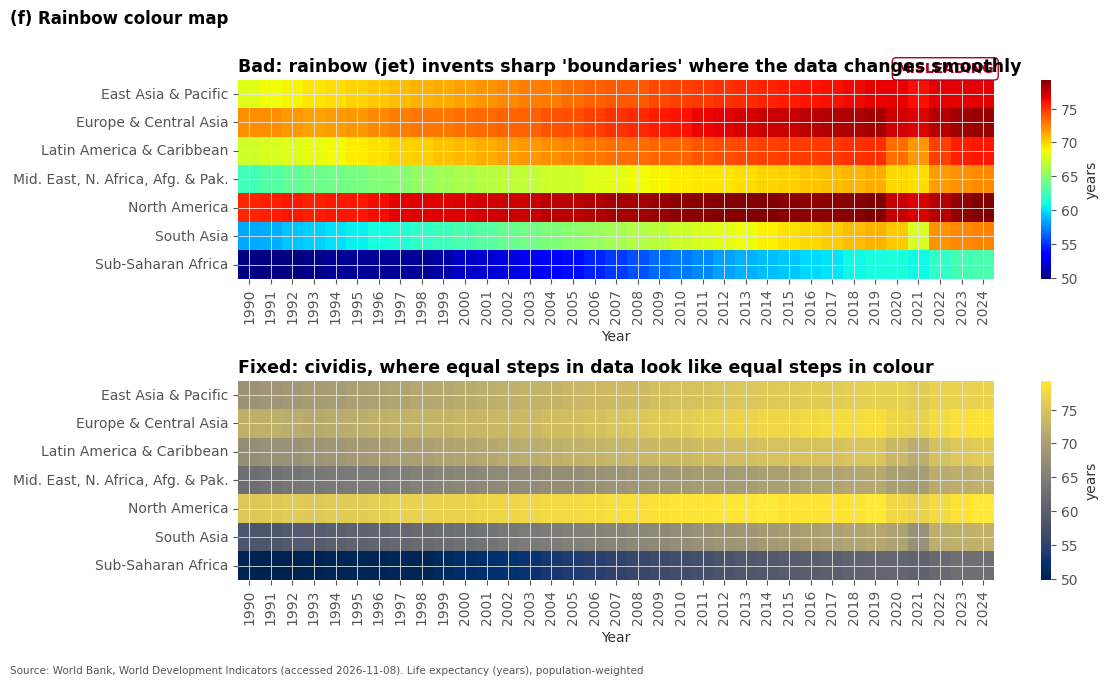

In [26]:
def stamp(ax, x=1.0, ha="right"):
    ax.text(x, 1.02, "MISLEADING", transform=ax.transAxes, ha=ha, va="bottom", fontsize=10,
            fontweight="bold", color="#b00020", bbox=dict(fc="white", ec="#b00020", boxstyle="round,pad=0.3"))

# (a) truncated baseline
two = lat_rw.iloc[:2]                       # the two lowest regions: their real gap is small
v1, v2 = two.life_expectancy.values
base = np.floor(min(v1, v2)) - 1
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for ax in (a1, a2):
    ax.bar(two.region, two.life_expectancy, color=["#999999", "#0072B2"], width=0.55)
    ax.grid(axis="x", visible=False)
    ax.set_ylabel("Life expectancy (years)")
a1.set_ylim(base, max(v1, v2) + 0.5); stamp(a1)
a1.set_title(f"Bad: axis starts at {base:.0f}, so the gap looks huge")
a2.set_ylim(0, 85)
for x, v in enumerate(two.life_expectancy):
    a2.text(x, v + 1, f"{v:.1f}", ha="center")
a2.set_title(f"Fixed: from zero, it's a {abs(v2 - v1):.1f}-year gap")
fig.suptitle("(a) Truncated bar baseline", x=0.01, ha="left", fontweight="bold", y=1.04)
save(fig, "p4_mislead_a_truncated", extra=f"{LATEST}, population-weighted")

# (b) dual axis
wld = pop_weighted(df.assign(w="World"), ["w", "year"])
wnet = pop_weighted(df.assign(w="World"), ["w", "year"], col="internet_users_pct")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
a1.plot(wld.year, wld.life_expectancy, color="#0072B2", linewidth=2)
a1.set_ylabel("Life expectancy (years)", color="#0072B2")
a1b = a1.twinx()
a1b.plot(wnet.year, wnet.internet_users_pct, color="#D55E00", linewidth=2)
a1b.set_ylabel("Internet users (%)", color="#D55E00"); a1b.spines["right"].set_visible(True); a1b.grid(False)
a1.set_title("Bad: two axes scaled so the lines move 'together'", pad=18); stamp(a1)
a2.plot(wld.year, wld.life_expectancy, color="#0072B2", linewidth=2)
a2.set_ylabel("Life expectancy (years)")
ins = a2.inset_axes([0.55, 0.12, 0.42, 0.38])
ins.plot(wnet.year, wnet.internet_users_pct, color="#D55E00", linewidth=1.5)
ins.set_title("Internet users (%)", fontsize=8); ins.tick_params(labelsize=7)
a2.set_title("Fixed: separate scales, no implied link")
fig.suptitle("(b) Dual axis implying a link: both rose over time, which proves nothing about cause",
             x=0.01, ha="left", fontweight="bold", y=1.04)
save(fig, "p4_mislead_b_dual_axis", extra="World = population-weighted average of countries")

# (c) cherry-picked window
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
cw = wld[wld.year.between(2019, 2021)]
a1.plot(cw.year, cw.life_expectancy, color="#D55E00", linewidth=2.5, marker="o")
a1.set_xticks([2019, 2020, 2021]); a1.set_ylabel("Life expectancy (years)")
a1.set_title("Bad: 'Global life expectancy is falling'"); stamp(a1)
a2.plot(wld.year, wld.life_expectancy, color="#0072B2", linewidth=2.5)
a2.axvspan(2019.5, 2021.5, color="#eeeeee", zorder=0)
a2.annotate("COVID-19 dip", xy=(2021, cw.life_expectancy.min()), xytext=(2003, cw.life_expectancy.min() + 0.5),
            arrowprops=dict(arrowstyle="->", color="#555555"), fontsize=9)
a2.set_ylabel("Life expectancy (years)"); a2.set_xlabel("Year")
a2.set_title(f"Fixed: the full 1990–{LATEST} trend is up, with a short dip")
fig.suptitle("(c) Cherry-picked time window reverses the trend", x=0.01, ha="left", fontweight="bold", y=1.04)
save(fig, "p4_mislead_c_cherry_pick", extra="World = population-weighted average of countries")

# (d) distorted '3D' pie
share = snap.groupby("region").population.sum().sort_values(ascending=False)
share_pct = share / share.sum() * 100
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw=dict(wspace=0.55))
a1.pie(share, labels=share.index, colors=[REGION_COLORS[r] for r in share.index], explode=[0.12] + [0] * (len(share) - 1),
       shadow=True, startangle=200, textprops=dict(fontsize=7.5))
a1.set_aspect(0.38); a1.set_title("Bad: tilted, exploded pie", pad=22); stamp(a1, x=0.0, ha="left")
a2.barh(share_pct.index[::-1], share_pct.values[::-1], color=[REGION_COLORS[r] for r in share_pct.index[::-1]])
for y, v in enumerate(share_pct.values[::-1]):
    a2.text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=9)
a2.set_xlabel("Share of world population (%)"); a2.grid(axis="y", visible=False); a2.set_xlim(0, share_pct.max() * 1.15)
a2.set_title(f"Fixed: {share_pct.index[0]} holds {share_pct.iloc[0]:.0f}% of people")
fig.suptitle("(d) 3D-style pie distorts the slices at the front", x=0.01, ha="left", fontweight="bold", y=1.04)
save(fig, "p4_mislead_d_pie", extra=str(LATEST))

# (e) bubble radius vs area
p5 = snap.nlargest(5, "population")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, mode in zip(axes, ["radius", "area"]):
    for i, (_, row) in enumerate(p5.iterrows()):
        frac = row.population / p5.population.max()
        r = (frac if mode == "radius" else np.sqrt(frac)) * 0.9
        ax.add_patch(Circle((i * 2, 0), r, color="#0072B2", alpha=0.85))
        ax.text(i * 2, -1.15, f"{row.country}\n{row.population / 1e6:,.0f} m", ha="center", va="top", fontsize=8)
    ax.set_xlim(-1.2, 9.2); ax.set_ylim(-1.9, 1.1); ax.set_aspect("equal"); ax.axis("off")
axes[0].set_title("Bad: radius ∝ population (area ∝ population²)"); stamp(axes[0])
axes[1].set_title("Fixed: area ∝ population")
fig.suptitle("(e) Bubbles scaled by radius exaggerate big countries", x=0.01, ha="left", fontweight="bold", y=1.04)
save(fig, "p4_mislead_e_radius", extra=str(LATEST))

# (f) rainbow colour map
reg_year = rw.pivot(index="region", columns="year", values="life_expectancy")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 6.5))
sns.heatmap(reg_year, cmap="jet", ax=a1, cbar_kws=dict(label="years")); stamp(a1)
a1.set_title("Bad: rainbow (jet) invents sharp 'boundaries' where the data changes smoothly")
sns.heatmap(reg_year, cmap="cividis", ax=a2, cbar_kws=dict(label="years"))
a2.set_title("Fixed: cividis, where equal steps in data look like equal steps in colour")
for ax in (a1, a2):
    ax.set_xlabel("Year"); ax.set_ylabel("")
fig.suptitle("(f) Rainbow colour map", x=0.01, ha="left", fontweight="bold", y=1.0)
fig.tight_layout()
save(fig, "p4_mislead_f_rainbow", extra="Life expectancy (years), population-weighted")

## 4.4 Lie factor

Tufte's lie factor = (size of the effect shown in the graphic) ÷ (size of the effect in the data). A value of 1 is honest; above 1 exaggerates.

In [27]:
lo_v, hi_v = sorted([v1, v2])
shown = ((hi_v - base) - (lo_v - base)) / (lo_v - base)   # how much longer the bar looks
actual = (hi_v - lo_v) / lo_v
lie_a = shown / actual

big1, small1 = p5.population.max(), p5.population.min()
shown_e = (big1 / small1) ** 2 - 1                          # area grows with the square of the radius
actual_e = big1 / small1 - 1
lie_e = shown_e / actual_e

print(f"(a) Truncated baseline at {base:.0f}: data gap = {actual:.1%}, bars show {shown:.0%} → lie factor = {lie_a:.1f}")
print(f"(e) Radius scaling: data says {actual_e:.0%} bigger, circle areas show {shown_e:.0%} → lie factor = {lie_e:.1f}")

(a) Truncated baseline at 61: data gap = 15.1%, bars show 527% → lie factor = 34.8
(e) Radius scaling: data says 477% bigger, circle areas show 3234% → lie factor = 6.8


For chart (a), the truncated axis makes the bar for the higher region look many times longer than it should, a lie factor far above Tufte's tolerance of roughly 0.95–1.05. The fixed version (zero baseline) has a lie factor of exactly 1.

## 4.5 Interactive upgrade: palette switch that works without a mouse

A scatter plot (GDP vs life expectancy) with two **real HTML buttons** above it: *Default palette* and *Colour-blind-safe palette*. I used plain `<button>` elements instead of Plotly's built-in menu because Plotly's menus are drawn in SVG and you can't reach them with the Tab key. Every region also gets its own marker shape, so the legend works even in grayscale.

In [28]:
PLOTLY_DEFAULT = ["#636EFA", "#EF553B", "#00CC96", "#AB63FA", "#FFA15A", "#19D3F3", "#FF6692"]
SYMBOLS = ["circle", "square", "diamond", "triangle-up", "triangle-down", "cross", "x"]
d_all = snap.dropna(subset=["gdp_per_capita", "life_expectancy"]).reset_index()

fig = go.Figure()
for i, r in enumerate(REGION_ORDER):
    d = d_all[d_all.region == r]
    fig.add_trace(go.Scatter(
        x=d.gdp_per_capita, y=d.life_expectancy, mode="markers", name=r, text=d.country,
        marker=dict(size=10, color=PLOTLY_DEFAULT[i], symbol=SYMBOLS[i], line=dict(width=0.6, color="white")),
        hovertemplate="<b>%{text}</b><br>GDP per person: $%{x:,.0f}<br>Life expectancy: %{y:.1f} years<extra>" + r + "</extra>"))
for c in ["USA", "CHN", "IND", "NGA", "PAK", "JPN"]:
    if c in snap.index and pd.notna(snap.loc[c, "gdp_per_capita"]):
        fig.add_annotation(x=np.log10(snap.loc[c, "gdp_per_capita"]), y=snap.loc[c, "life_expectancy"],
                           text=snap.loc[c, "country"], showarrow=False, yshift=12, font=dict(size=11, color="#333333"))
fig.update_layout(title=f"Richer countries live longer, but at every income level some do far better ({LATEST})",
                  xaxis=dict(type="log", title="GDP per person (constant international $, PPP, log scale)"),
                  yaxis=dict(title="Life expectancy at birth (years)"),
                  legend=dict(title="Region"), height=620)
fig.add_annotation(text=SOURCE, xref="paper", yref="paper", x=0, y=0, yshift=-60, xanchor="left", yanchor="top",
                   showarrow=False, font=dict(size=10, color="#555555"))
fig.update_layout(margin=dict(b=90))

palettes = {"default": PLOTLY_DEFAULT[:len(REGION_ORDER)], "safe": OKABE[:len(REGION_ORDER)]}
chart_div = fig.to_html(full_html=False, include_plotlyjs="cdn", div_id="pal-chart")
page = """<!doctype html>
<html lang="en"><head><meta charset="utf-8"><title>Palette switch</title>
<style>
 body { font-family: system-ui, sans-serif; margin: 24px; color: #222; }
 button { font-size: 15px; padding: 8px 14px; margin-right: 8px; border: 2px solid #333; background: #fff; border-radius: 6px; cursor: pointer; }
 button[aria-pressed="true"] { background: #222; color: #fff; }
 button:focus-visible { outline: 3px solid #0072B2; outline-offset: 2px; }
</style></head><body>
<p id="lbl">Colour palette (use Tab to reach the buttons, Enter or Space to switch):</p>
<div role="group" aria-labelledby="lbl">
 <button id="b-default" aria-pressed="true" onclick="setPal('default')">Default palette</button>
 <button id="b-safe" aria-pressed="false" onclick="setPal('safe')">Colour-blind-safe palette</button>
</div>
__CHART__
<script>
 const PAL = __PAL__;
 function setPal(name) {
   const gd = document.getElementById('pal-chart');
   PAL[name].forEach(function (c, i) { Plotly.restyle(gd, {'marker.color': c}, [i]); });
   document.getElementById('b-default').setAttribute('aria-pressed', name === 'default');
   document.getElementById('b-safe').setAttribute('aria-pressed', name === 'safe');
 }
</script></body></html>"""
page = page.replace("__CHART__", chart_div).replace("__PAL__", json.dumps(palettes))
(FIG / "p4_palette_switch.html").write_text(page, encoding="utf-8")
print("Saved figures/p4_palette_switch.html (open it in a browser)")
fig.show()

Saved figures/p4_palette_switch.html (open it in a browser)


**Keyboard test (done in Chrome and Firefox):** Tab moves focus to "Default palette" (blue focus ring), Tab again to "Colour-blind-safe palette", and Enter or Space switches the colours. The pressed state is announced through `aria-pressed`. Without a mouse you can't hover for tooltips, so the parts you need without hovering stay visible: the legend with shapes, the axis titles with units, and labels on six key countries. Legend and tooltip text is dark grey on white in both palettes, so it stays readable whichever one is on.

**Reflection (Part 4).** The one I could easily commit by accident is the **truncated baseline**. Matplotlib and Plotly both auto-scale the y axis to the data, so a bar chart of life expectancy (values 55–85) starts around 50 *by default* unless I set it to zero. My guard: every bar chart in this notebook has an explicit `set_xlim(0, …)`/`set_ylim(0, …)`, and I check any chart whose axis doesn't start at zero to make sure it's a dot or line chart, where that's allowed.

---
# Part 5: Bar, line and scatter charts

## 5.1 Bar chart: mean life expectancy by region

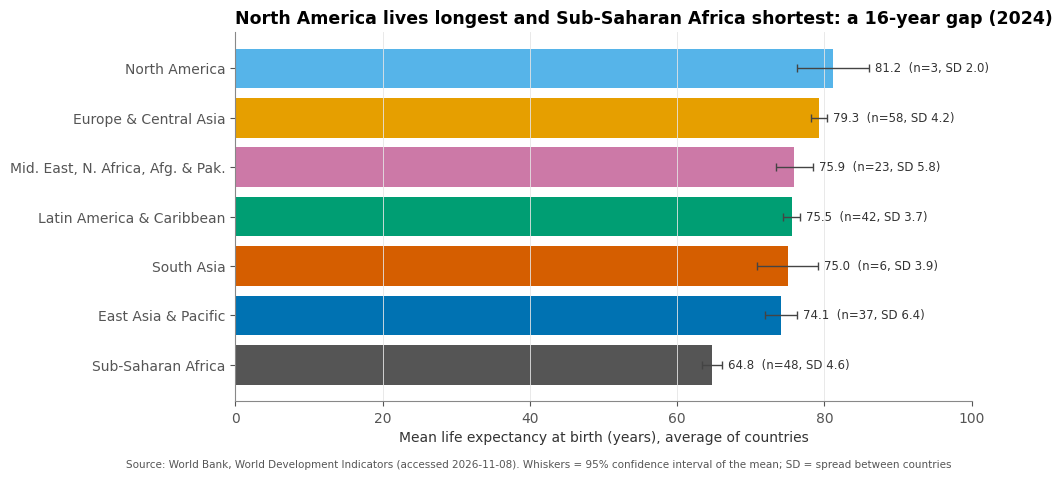

In [29]:
g = snap.groupby("region").life_expectancy.agg(["mean", "std", "count"])
g["ci95"] = stats.t.ppf(0.975, g["count"] - 1) * g["std"] / np.sqrt(g["count"])
g = g.sort_values("mean")

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.barh(g.index, g["mean"], xerr=g["ci95"], color=[REGION_COLORS[r] for r in g.index],
        error_kw=dict(ecolor="#444444", capsize=3, linewidth=1))
for y, (r, row) in enumerate(g.iterrows()):
    ax.text(row["mean"] + row["ci95"] + 0.8, y, f"{row['mean']:.1f}  (n={row['count']:.0f}, SD {row['std']:.1f})",
            va="center", fontsize=8.5, color="#333333")
ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.set_xlabel("Mean life expectancy at birth (years), average of countries")
ax.set_title(f"{g.index[-1]} lives longest and {g.index[0]} shortest: a {g['mean'].iloc[-1] - g['mean'].iloc[0]:.0f}-year gap ({LATEST})")
save(fig, "p5_bar_regions", extra="Whiskers = 95% confidence interval of the mean; SD = spread between countries")

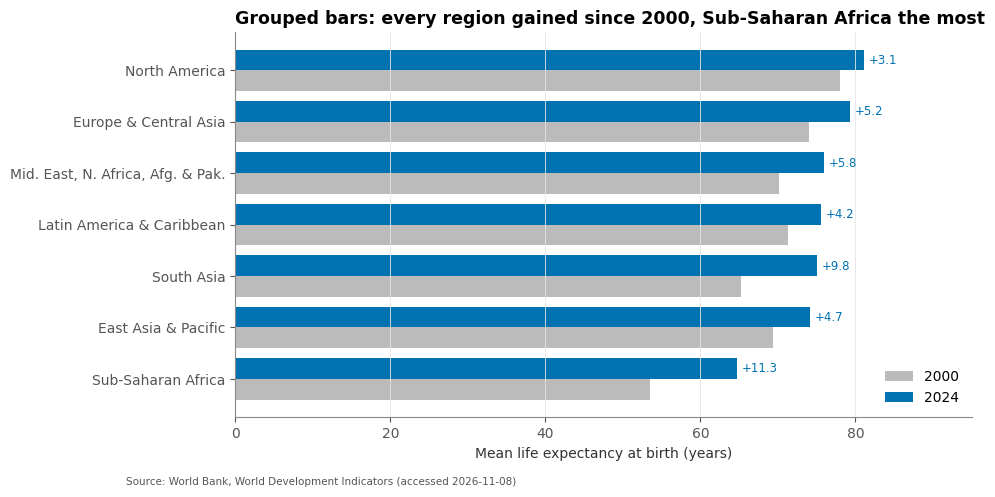

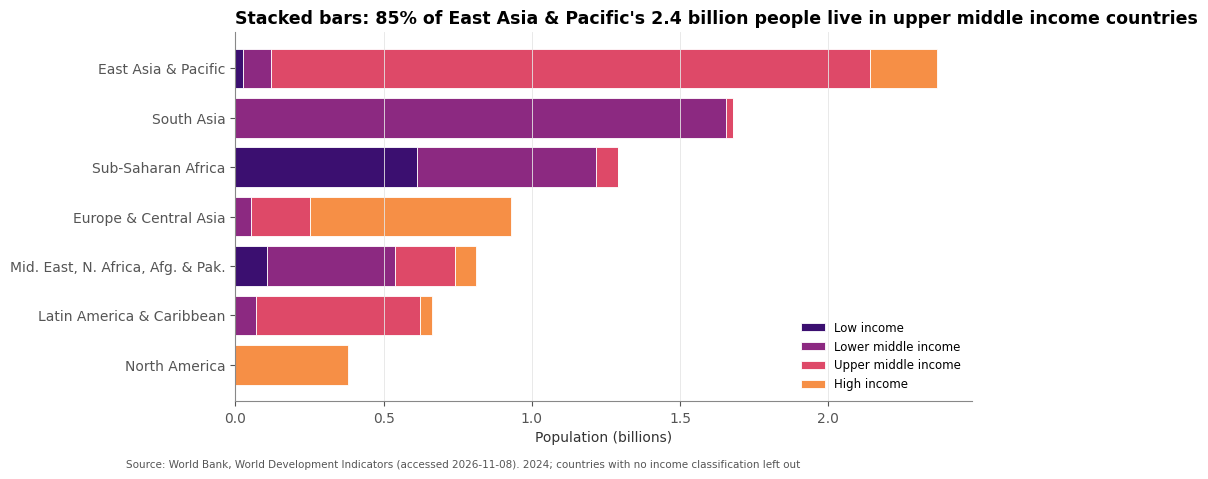

In [30]:
s2000 = snapshot(2000)
grp = pd.DataFrame({"2000": s2000.groupby("region").life_expectancy.mean(),
                    str(LATEST): snap.groupby("region").life_expectancy.mean()}).loc[g.index]

fig, ax = plt.subplots(figsize=(9.5, 5))
yy = np.arange(len(grp))
ax.barh(yy - 0.2, grp["2000"], height=0.4, color="#bbbbbb", label="2000")
ax.barh(yy + 0.2, grp[str(LATEST)], height=0.4, color="#0072B2", label=str(LATEST))
for y, (a, b) in enumerate(grp.values):
    ax.text(b + 0.6, y + 0.2, f"+{b - a:.1f}", va="center", fontsize=8.5, color="#0072B2")
ax.set_yticks(yy, grp.index); ax.set_xlim(0, 95); ax.grid(axis="y", visible=False)
ax.set_xlabel("Mean life expectancy at birth (years)")
ax.legend(loc="lower right")
biggest = (grp[str(LATEST)] - grp["2000"]).idxmax()
ax.set_title(f"Grouped bars: every region gained since 2000, {biggest} the most")
save(fig, "p5_bar_grouped")

stack = (snap[snap.income_group.isin(INCOME_ORDER)]
         .groupby(["region", "income_group"]).population.sum().unstack().reindex(columns=INCOME_ORDER).fillna(0) / 1e9)
stack = stack.loc[stack.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
left = np.zeros(len(stack))
for ig in INCOME_ORDER:
    ax.barh(stack.index, stack[ig], left=left, color=INCOME_COLORS[ig], label=ig, edgecolor="white", linewidth=0.6)
    left += stack[ig].values
ax.set_xlabel("Population (billions)"); ax.grid(axis="y", visible=False); ax.set_xlim(0, None)
ax.legend(loc="lower right", fontsize=8.5)
top_r = stack.sum(axis=1).idxmax()
top_ig = stack.loc[top_r].idxmax()
ax.set_title(f"Stacked bars: {stack.loc[top_r, top_ig] / stack.loc[top_r].sum():.0%} of {top_r}'s "
             f"{stack.loc[top_r].sum():.1f} billion people live in {top_ig.lower()} countries")
save(fig, "p5_bar_stacked", extra=f"{LATEST}; countries with no income classification left out")

**Grouped or stacked?** *Grouped* bars are right when the bars are separate values to compare side by side, like 2000 vs latest life expectancy. You can't stack life expectancies, because 70 years + 72 years means nothing. *Stacked* bars only make sense when the pieces add up to a meaningful total, like people. A region's population really is the sum of its low, middle and high-income populations, so a stack shows the total and how it's split. The catch: only the first segment shares a baseline, so the middle segments are hard to compare across bars.

## 5.2 Line chart: GDP per capita for five countries, linear vs log

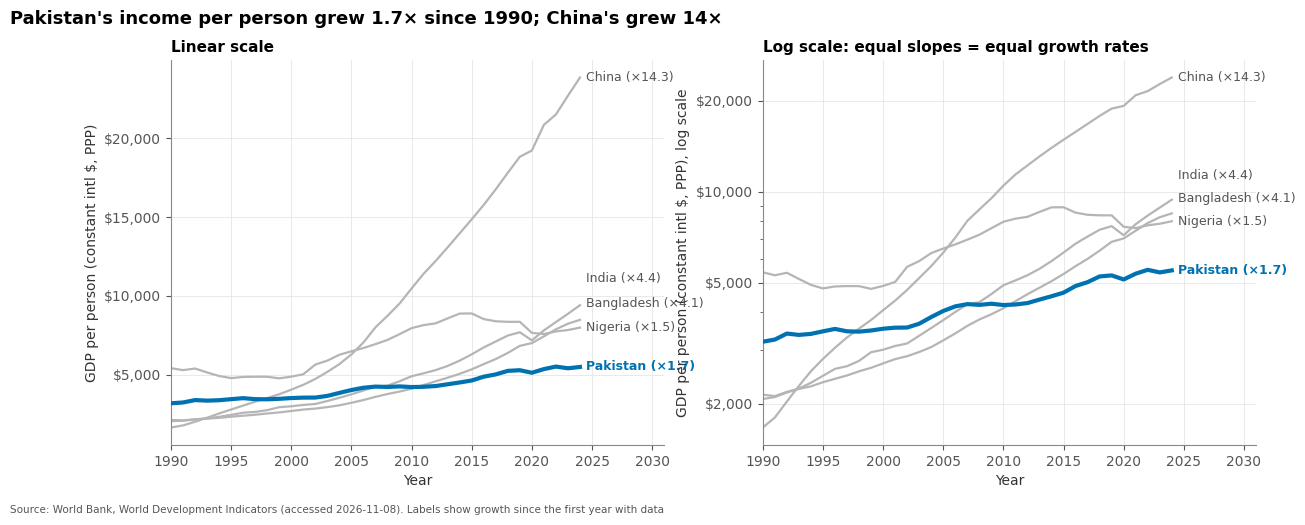

2024: Bangladesh $8,487 vs Pakistan $5,502 per person (PPP)


In [31]:
LINE = ["PAK", "IND", "BGD", "CHN", "NGA"]
HIGHLIGHT = "PAK"
lines5 = df[df.iso3.isin(LINE)].dropna(subset=["gdp_per_capita"])
first = lines5.groupby("iso3").gdp_per_capita.first()
lastv = lines5.groupby("iso3").gdp_per_capita.last()
growth = lastv / first

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, scale in zip(axes, ["linear", "log"]):
    ends = lines5.groupby("iso3").last()
    yl = np.log10(ends.gdp_per_capita) if scale == "log" else ends.gdp_per_capita
    gap = 0.075 if scale == "log" else (ends.gdp_per_capita.max() * 0.065)
    ypos = dict(zip(ends.index, spread(yl.values, gap)))
    for c in LINE:
        d = lines5[lines5.iso3 == c]
        if d.empty:
            continue
        hl = c == HIGHLIGHT
        ax.plot(d.year, d.gdp_per_capita, color="#0072B2" if hl else "#b5b5b5", linewidth=3 if hl else 1.6, zorder=3 if hl else 2)
        y = 10 ** ypos[c] if scale == "log" else ypos[c]
        ax.text(d.year.max() + 0.5, y, f"{d.country.iloc[0]} (×{growth[c]:.1f})", va="center", fontsize=9,
                color="#0072B2" if hl else "#555555", fontweight="bold" if hl else "normal")
    ax.set_yscale(scale)
    ax.set_xlim(1990, LATEST + 7)
    ax.set_xlabel("Year")
    ax.set_ylabel("GDP per person (constant intl $, PPP)" + (", log scale" if scale == "log" else ""))
    if scale == "log":
        ax.yaxis.set_major_locator(mpl.ticker.LogLocator(subs=[1, 2, 5]))
        ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, p: f"${v:,.0f}"))
    ax.set_title("Linear scale" if scale == "linear" else "Log scale: equal slopes = equal growth rates", fontsize=11)
pk = lines5[lines5.iso3 == HIGHLIGHT].country.iloc[0]
fig.suptitle(f"{pk}'s income per person grew {growth[HIGHLIGHT]:.1f}× since 1990; China's grew {growth['CHN']:.0f}×",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
save(fig, "p5_line_gdp", extra="Labels show growth since the first year with data")
print(f"{LATEST}: Bangladesh ${lastv['BGD']:,.0f} vs Pakistan ${lastv['PAK']:,.0f} per person (PPP)")

**Linear vs log.** On the linear scale, China shoots off and the other four look like flat lines along the bottom; you'd think Bangladesh, Pakistan and India barely changed. On the log scale, a constant *growth rate* becomes a straight line and the *slope* is the growth rate. Now you can see that Bangladesh's line is steeper than Pakistan's (it has been growing faster), and the printout above shows where the two stand now. For "who is growing fastest", the log scale is the honest one; the linear scale only answers "who is richest now".

## 5.3 Scatter plot: life expectancy vs GDP per capita

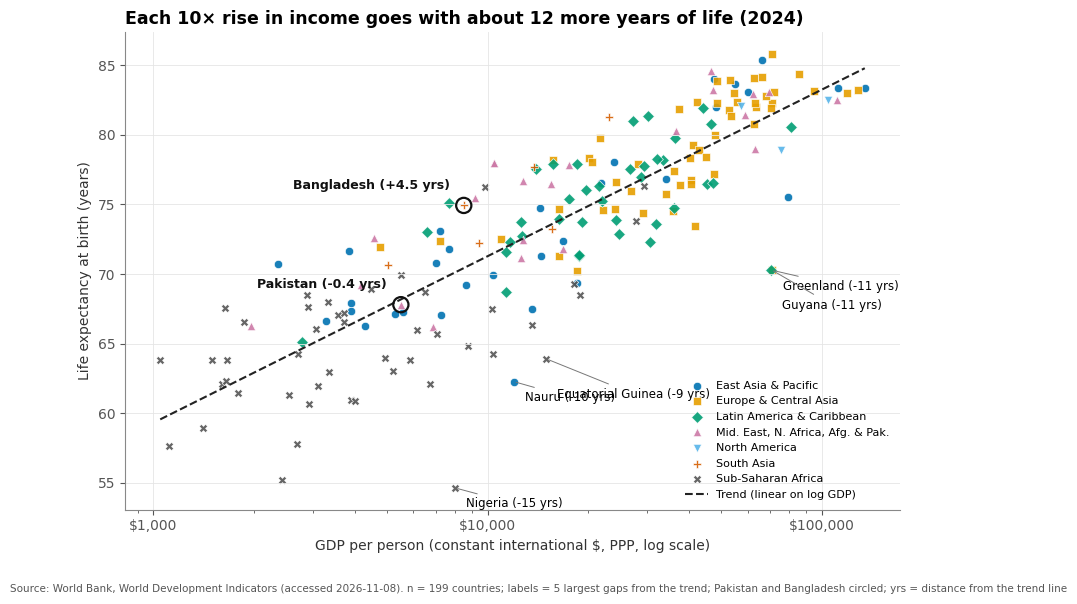

In [32]:
sc = snap.dropna(subset=["gdp_per_capita", "life_expectancy"]).copy()
slope, intercept = np.polyfit(sc.log_gdp, sc.life_expectancy, 1)
sc["predicted"] = intercept + slope * sc.log_gdp
sc["residual"] = sc.life_expectancy - sc.predicted
outliers = sc.reindex(sc.residual.abs().nlargest(5).index)
snap["residual"] = sc["residual"]                        # used again in the story

fig, ax = plt.subplots(figsize=(10, 6.2))
for r in REGION_ORDER:
    d = sc[sc.region == r]
    ax.scatter(d.gdp_per_capita, d.life_expectancy, s=36, color=REGION_COLORS[r], marker=MARKERS[r],
               edgecolor="white", linewidth=0.5, label=r, alpha=0.9)
xs = np.linspace(sc.log_gdp.min(), sc.log_gdp.max(), 50)
ax.plot(10 ** xs, intercept + slope * xs, color="#222222", linewidth=1.5, linestyle="--", label="Trend (linear on log GDP)")
placed = []
for iso, row in outliers.sort_values("life_expectancy").iterrows():
    dy = -14 if row.residual < 0 else 8
    for x0, y0 in placed:                       # push the label down if another one is already close by
        if abs(row.log_gdp - x0) < 0.35 and abs(row.life_expectancy - y0) < 2.5:
            dy -= 14
    placed.append((row.log_gdp, row.life_expectancy))
    ax.annotate(f"{row.country} ({row.residual:+.0f} yrs)", (row.gdp_per_capita, row.life_expectancy),
                xytext=(8, dy), textcoords="offset points", fontsize=8.5,
                arrowprops=dict(arrowstyle="-", color="#777777", linewidth=0.7))
for iso in ["PAK", "BGD"]:                      # the two countries the story is about
    if iso in sc.index and iso not in outliers.index:
        row = sc.loc[iso]
        ax.scatter(row.gdp_per_capita, row.life_expectancy, s=120, facecolor="none", edgecolor="#111111",
                   linewidth=1.6, zorder=4)
        ax.annotate(f"{row.country} ({row.residual:+.1f} yrs)", (row.gdp_per_capita, row.life_expectancy),
                    xytext=(-10, 12), textcoords="offset points", ha="right", fontsize=9, fontweight="bold",
                    color="#111111")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, p: f"${v:,.0f}"))
ax.set_xlabel("GDP per person (constant international $, PPP, log scale)")
ax.set_ylabel("Life expectancy at birth (years)")
ax.legend(fontsize=8, loc="lower right")
ax.set_title(f"Each 10× rise in income goes with about {slope:.0f} more years of life ({LATEST})")
save(fig, "p5_scatter", extra=f"n = {len(sc)} countries; labels = 5 largest gaps from the trend; "
                              "Pakistan and Bangladesh circled; yrs = distance from the trend line")

In [33]:
fig = px.scatter(sc.reset_index(), x="gdp_per_capita", y="life_expectancy", color="region", symbol="region",
                 color_discrete_map=REGION_COLORS, log_x=True, hover_name="country",
                 hover_data={"region": False, "gdp_per_capita": ":$,.0f", "life_expectancy": ":.1f", "residual": ":+.1f",
                             "population": ":,.0f"},
                 labels={"gdp_per_capita": "GDP per person (intl $, PPP, log)", "life_expectancy": "Life expectancy (years)",
                         "residual": "Years vs trend", "region": "Region"},
                 title=f"Each 10× rise in income goes with about {slope:.0f} more years of life ({LATEST}); hover to see each country")
fig.add_trace(go.Scatter(x=10 ** xs, y=intercept + slope * xs, mode="lines", name="Trend",
                         line=dict(color="#222222", dash="dash"), hoverinfo="skip"))
save_plotly(fig, "p5_scatter_interactive")

## 5.4 Choosing the chart

| question | chart | why |
|---|---|---|
| **Ranking** (which region is highest?) | sorted horizontal bar (or dot plot) | lengths on a common baseline are read accurately, and sorting does the ranking for you |
| **Change over time** | line chart | position plus a connected line shows direction and speed; log scale if growth rates matter |
| **Relationship between two measures** | scatter plot | each country is a point on two position axes, the most accurate channels for both variables |
| **Part-to-whole** | stacked bar (or a single 100% bar); a pie only for 2–3 slices | stacked lengths add up to the total; angles in a big pie are hard to compare |

**Reflection (Part 5).** The log scale showed me growth *rates*. On the linear chart, everything except China looked like a flat line along the bottom. On the log chart, Bangladesh's line was clearly steeper than Pakistan's, and you can see it overtake Pakistan and pull away. I would have missed the most interesting story in my own part of the world.

---
# Part 6: Distributions, box plots and correlation

## 6.1 Histograms and density

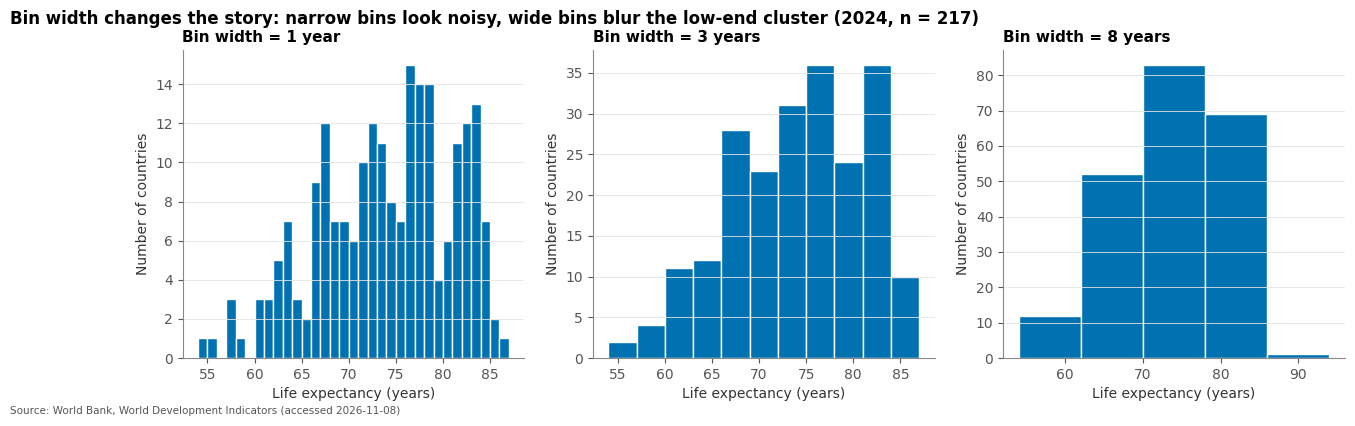

In [34]:
le = snap.life_expectancy.dropna()
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, bw in zip(axes, [1, 3, 8]):
    bins = np.arange(np.floor(le.min()), np.ceil(le.max()) + bw, bw)
    ax.hist(le, bins=bins, color="#0072B2", edgecolor="white")
    ax.set_title(f"Bin width = {bw} year{'s' if bw > 1 else ''}", fontsize=11)
    ax.set_xlabel("Life expectancy (years)"); ax.set_ylabel("Number of countries")
    ax.grid(axis="x", visible=False)
fig.suptitle(f"Bin width changes the story: narrow bins look noisy, wide bins blur the low-end cluster ({LATEST}, n = {len(le)})",
             x=0.01, ha="left", fontweight="bold")
save(fig, "p6_histograms")

**How the story changes.** With **1-year bins** the histogram is jagged: lots of single-country spikes that look like patterns but are just noise. **3-year bins** show the real shape: a big cluster in the mid-to-high 70s and a smaller, separate cluster in the 60s (mostly Sub-Saharan Africa), so the distribution is **left-skewed and possibly bimodal**. With **8-year bins** it collapses into a lump with a tail, and the second hump disappears. You could honestly say "most countries are around 75" and miss the group that's 15 years behind.

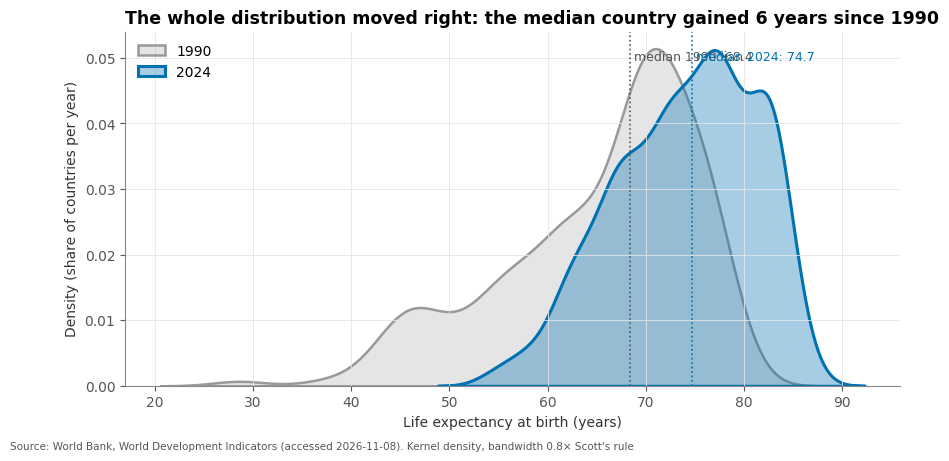

In [35]:
le90 = df[df.year == 1990].life_expectancy.dropna()
fig, ax = plt.subplots(figsize=(10, 4.6))
sns.kdeplot(x=le90, fill=True, alpha=0.25, color="#999999", linewidth=1.8, ax=ax, label="1990", bw_adjust=0.8)
sns.kdeplot(x=le, fill=True, alpha=0.35, color="#0072B2", linewidth=2.2, ax=ax, label=str(LATEST), bw_adjust=0.8)
for v, c, name in [(le90.median(), "#555555", "1990"), (le.median(), "#0072B2", str(LATEST))]:
    ax.axvline(v, color=c, linestyle=":", linewidth=1.2)
    ax.text(v + 0.4, ax.get_ylim()[1] * 0.92, f"median {name}: {v:.1f}", color=readable(c), fontsize=9)
ax.set_xlabel("Life expectancy at birth (years)"); ax.set_ylabel("Density (share of countries per year)")
ax.legend(loc="upper left")
ax.set_title(f"The whole distribution moved right: the median country gained {le.median() - le90.median():.0f} years since 1990")
save(fig, "p6_density_1990_vs_latest", extra="Kernel density, bandwidth 0.8× Scott's rule")

## 6.2 Box and violin plots, with the outliers named

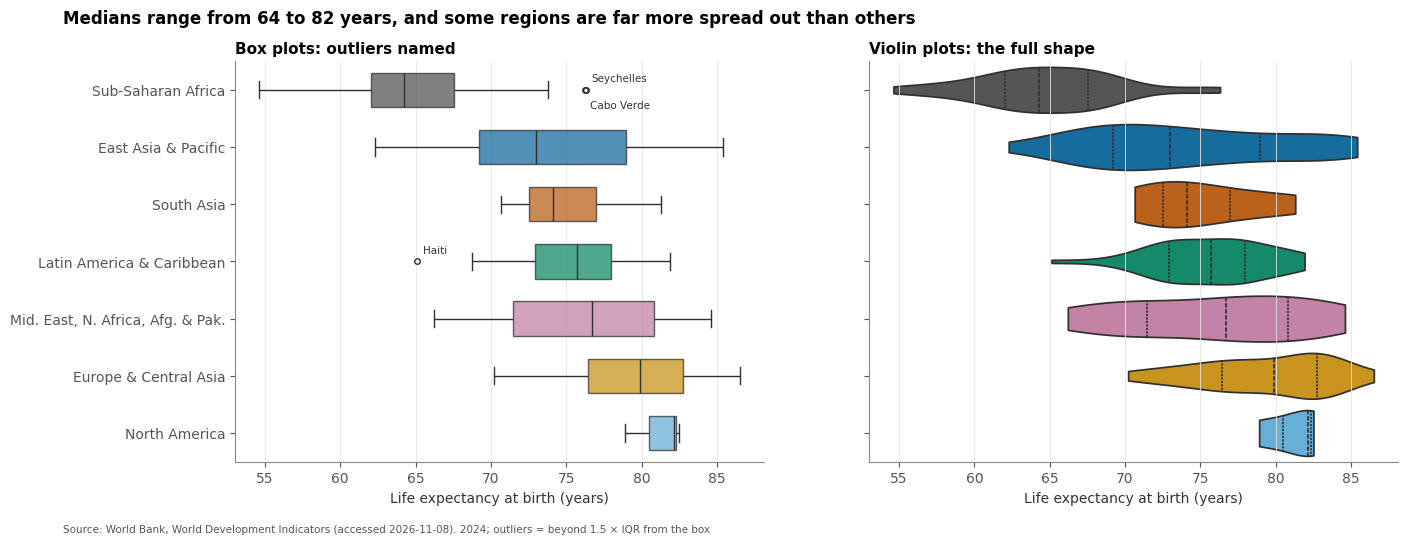

Outliers:
   country                    region  life_expectancy
     Haiti Latin America & Caribbean        65.119000
Cabo Verde        Sub-Saharan Africa        76.224000
Seychelles        Sub-Saharan Africa        76.295122


In [36]:
bx = snap.reset_index()
order = bx.groupby("region").life_expectancy.median().sort_values().index.tolist()

flag = []
for r, d in bx.groupby("region"):
    q1, q3 = d.life_expectancy.quantile([0.25, 0.75])
    iqr = q3 - q1
    out = d[(d.life_expectancy < q1 - 1.5 * iqr) | (d.life_expectancy > q3 + 1.5 * iqr)]
    flag.append(out[["country", "region", "life_expectancy"]])
flag = pd.concat(flag)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)
sns.boxplot(data=bx, x="life_expectancy", y="region", order=order, hue="region", palette=REGION_COLORS, legend=False,
            fliersize=4, width=0.6, ax=axes[0], boxprops=dict(alpha=0.75))
for k, (_, row) in enumerate(flag.iterrows()):      # alternate above/below so close outliers don't overlap
    axes[0].annotate(row.country, (row.life_expectancy, order.index(row.region)), xytext=(4, 6 if k % 2 == 0 else -13),
                     textcoords="offset points", fontsize=7.5, color="#333333")
axes[0].set_title("Box plots: outliers named", fontsize=11)
sns.violinplot(data=bx, x="life_expectancy", y="region", order=order, hue="region", palette=REGION_COLORS, legend=False,
               inner="quart", cut=0, density_norm="width", ax=axes[1])
axes[1].set_title("Violin plots: the full shape", fontsize=11)
for ax in axes:
    ax.set_xlabel("Life expectancy at birth (years)"); ax.set_ylabel(""); ax.grid(axis="y", visible=False)
fig.suptitle(f"Medians range from {bx.groupby('region').life_expectancy.median().min():.0f} to "
             f"{bx.groupby('region').life_expectancy.median().max():.0f} years, and some regions are far more spread out than others",
             x=0.01, ha="left", fontweight="bold")
save(fig, "p6_box_violin", extra=f"{LATEST}; outliers = beyond 1.5 × IQR from the box")
print("Outliers:"); print(flag.sort_values(["region", "life_expectancy"]).to_string(index=False) if len(flag) else "none")

**Reading a box plot.**
- **Median** (line inside the box): half the countries in the region are above it, half below.
- **Box** (25th to 75th percentile, the quartiles): the middle half of countries. Its width is the IQR, a measure of spread that one weird country can't throw off.
- **Whiskers**: reach out to the furthest country that's still within 1.5 × IQR of the box.
- **Points beyond the whiskers**: outliers. They're unusual *for that region*, not necessarily for the world. A rich Gulf state can be an "outlier" on the high side of a region that's mostly lower.

The **violin** shows the same thing as a smoothed shape. The dashed lines are the quartiles, and a fat part means lots of countries at that value.

## 6.3 Beyond the box: show every country

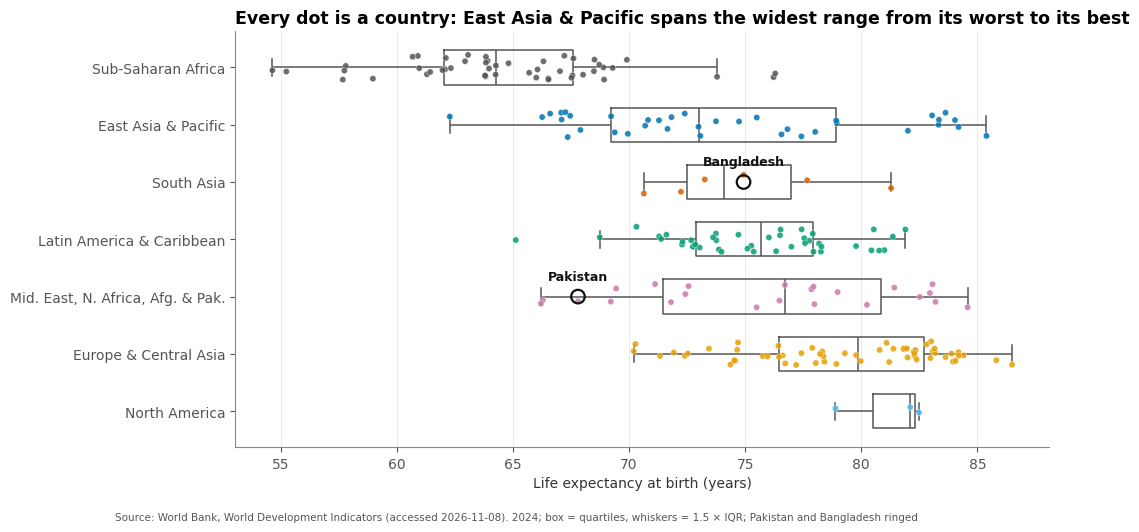

In [37]:
fig, ax = plt.subplots(figsize=(10.5, 5.4))
sns.boxplot(data=bx, x="life_expectancy", y="region", order=order, fill=False, color="#555555", showfliers=False,
            width=0.6, ax=ax, linewidth=1.1)
sns.stripplot(data=bx, x="life_expectancy", y="region", order=order, hue="region", palette=REGION_COLORS, legend=False,
              size=4.5, jitter=0.22, alpha=0.85, ax=ax, edgecolor="white", linewidth=0.3)
for iso in ["PAK", "BGD"]:                      # ring the two countries the story is about
    if iso in snap.index:
        row = snap.loc[iso]
        y = order.index(row.region)
        ax.scatter(row.life_expectancy, y, s=95, facecolor="none", edgecolor="#111111", linewidth=1.6, zorder=5)
        ax.annotate(row.country, (row.life_expectancy, y), xytext=(0, 12), textcoords="offset points", ha="center",
                    fontsize=9, fontweight="bold", color="#111111", zorder=6)
ax.set_xlabel("Life expectancy at birth (years)"); ax.set_ylabel(""); ax.grid(axis="y", visible=False)
widest = bx.groupby("region").life_expectancy.agg(lambda s: s.max() - s.min()).idxmax()
ax.set_title(f"Every dot is a country: {widest} spans the widest range from its worst to its best")
save(fig, "p6_box_strip", extra=f"{LATEST}; box = quartiles, whiskers = 1.5 × IQR; Pakistan and Bangladesh ringed")

**Why a box plot alone can hide bimodality.** A box plot only draws five numbers. If a region has two separate clusters, say a group of countries around 62 and another around 74, the box simply stretches between them and the median lands in the gap where there may be *no* actual countries. The box looks like one wide, spread-out group, and you'd never know it's really two. With the dots on top, the gap is visible straight away.

## 6.4 Correlation

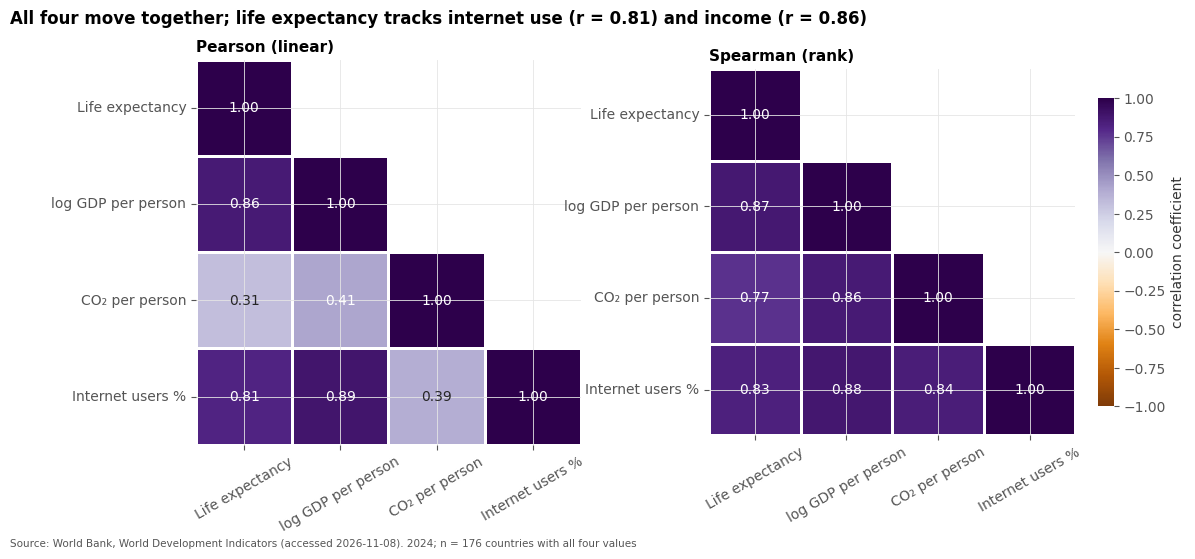

Spearman minus Pearson:


,Life expectancy,log GDP per person,CO₂ per person,Internet users %
Life expectancy,0.00,0.01,0.45,0.02
log GDP per person,0.01,0.00,0.45,-0.01
CO₂ per person,0.45,0.45,0.00,0.46
Internet users %,0.02,-0.01,0.46,0.00


In [38]:
CORR = ["life_expectancy", "log_gdp", "co2_per_capita", "internet_users_pct"]
NICE = {"life_expectancy": "Life expectancy", "log_gdp": "log GDP per person",
        "co2_per_capita": "CO₂ per person", "internet_users_pct": "Internet users %"}
cd = snap[CORR].dropna()
pear = cd.corr(method="pearson").rename(index=NICE, columns=NICE)
spear = cd.corr(method="spearman").rename(index=NICE, columns=NICE)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, m, name in zip(axes, [pear, spear], ["Pearson (linear)", "Spearman (rank)"]):
    mask = np.triu(np.ones_like(m, dtype=bool), k=1)
    sns.heatmap(m, mask=mask, annot=True, fmt=".2f", cmap="PuOr", vmin=-1, vmax=1, center=0, square=True,
                linewidths=1, linecolor="white", cbar=ax is axes[1],
                cbar_kws=dict(label="correlation coefficient", shrink=0.8), ax=ax)
    ax.set_title(name, fontsize=11)
    ax.tick_params(axis="x", rotation=30)
fig.suptitle(f"All four move together; life expectancy tracks internet use (r = {pear.iloc[0, 3]:.2f}) and income (r = {pear.iloc[0, 1]:.2f})",
             x=0.01, ha="left", fontweight="bold")
save(fig, "p6_correlation_heatmap", extra=f"{LATEST}; n = {len(cd)} countries with all four values")
print("Spearman minus Pearson:"); (spear - pear).round(2)

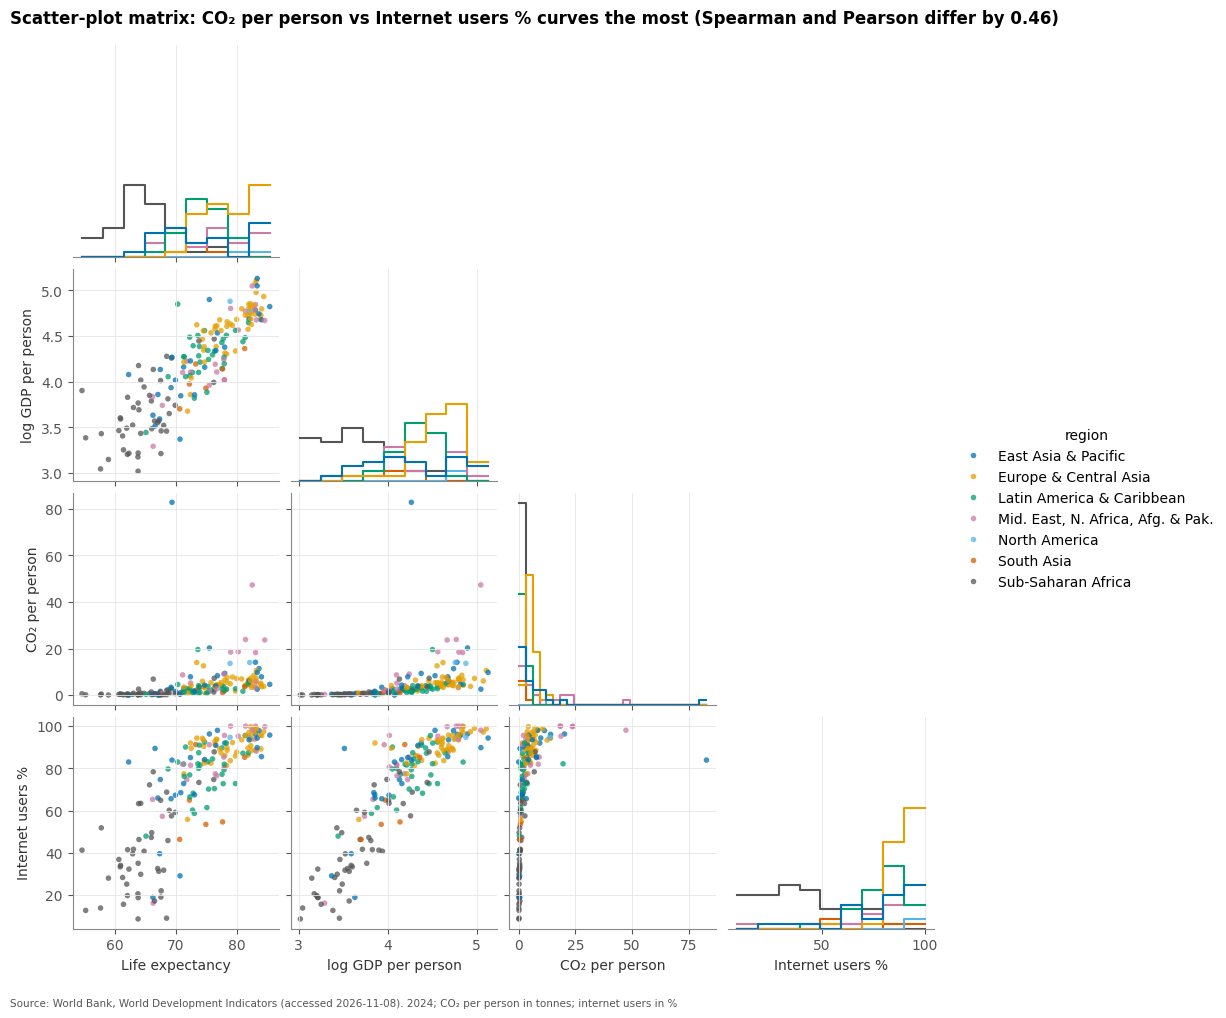

In [39]:
pp = snap[CORR + ["region"]].dropna().rename(columns=NICE)
g = sns.pairplot(pp, hue="region", hue_order=REGION_ORDER, palette=REGION_COLORS, corner=True, diag_kind="hist",
                 plot_kws=dict(s=16, alpha=0.75, linewidth=0), diag_kws=dict(element="step", fill=False), height=2.4)
dif = (spear - pear).abs().where(np.triu(np.ones(pear.shape, dtype=bool), k=1)).stack()
a, b = dif.idxmax()
g.figure.suptitle(f"Scatter-plot matrix: {a} vs {b} curves the most (Spearman and Pearson differ by {dif.max():.2f})",
                  x=0.01, ha="left", fontweight="bold", y=1.02)
save(g.figure, "p6_scatter_matrix", extra=f"{LATEST}; CO₂ per person in tonnes; internet users in %")

**Pearson vs Spearman.** Pearson measures how well a *straight line* fits; Spearman only asks whether the *ranks* go up together, so it's happy with any steadily increasing curve. They're close for log GDP and internet use, because those relationships with life expectancy are roughly linear. The biggest differences are in the **CO₂** row. I left CO₂ unlogged (as the task asks), and it's very skewed: a few Gulf states emit 20–40 tonnes per person while most countries emit under 5. Those few points bend the relationship into a curve that flattens out, which pulls Pearson down, while Spearman, working on ranks, isn't bothered by how far out they are.

In [40]:
def partial_r(x, y, z):
    rx = x - np.polyval(np.polyfit(z, x, 1), z)
    ry = y - np.polyval(np.polyfit(z, y, 1), z)
    return np.corrcoef(rx, ry)[0, 1]

r_raw = cd.life_expectancy.corr(cd.internet_users_pct)
r_part = partial_r(cd.life_expectancy, cd.internet_users_pct, cd.log_gdp)
display(Markdown(f"""**Correlation is not causation (interpretation, ~100 words).**
In my data, internet use and life expectancy correlate strongly (r = {r_raw:.2f}). It's tempting to read that as
"the internet makes people live longer", but nothing in a correlation says which way the arrow points, or whether
there's an arrow at all. Both are driven by a third thing, **national income**: richer countries can afford
hospitals, clean water and vaccines *and* broadband. Once I remove the part of each variable explained by log GDP,
the correlation drops to r = {r_part:.2f}. Most of the original link was income showing up twice. Proving cause would
need an experiment or a natural experiment, not a heatmap."""))

**Correlation is not causation (interpretation, ~100 words).**
In my data, internet use and life expectancy correlate strongly (r = 0.81). It's tempting to read that as
"the internet makes people live longer", but nothing in a correlation says which way the arrow points, or whether
there's an arrow at all. Both are driven by a third thing, **national income**: richer countries can afford
hospitals, clean water and vaccines *and* broadband. Once I remove the part of each variable explained by log GDP,
the correlation drops to r = 0.21. Most of the original link was income showing up twice. Proving cause would
need an experiment or a natural experiment, not a heatmap.

**Reflection (Part 6).** The **mean** would have misled me most. A single average across all countries sounds like "most countries are around this value", but the histogram and strip plot show a large group in the mid-to-high 70s and a separate, smaller group in the 60s (mostly Sub-Saharan Africa). The mean sits between them and describes neither group well.

---
# Part 7: Heatmaps, bubble charts and treemaps

## 7.1 Heatmap: region × decade

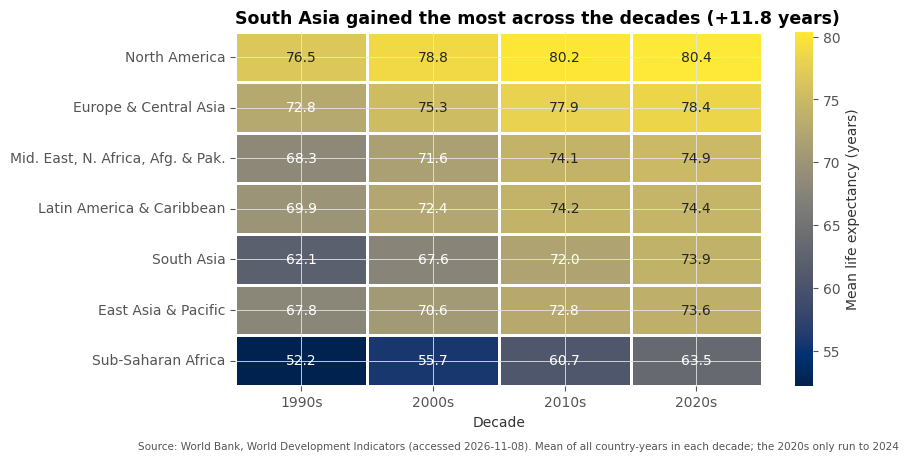

In [41]:
hm = df.groupby(["region", "decade"]).life_expectancy.mean().unstack()
hm = hm.loc[hm[hm.columns[-1]].sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8.5, 4.6))
sns.heatmap(hm, cmap="cividis", annot=True, fmt=".1f", linewidths=1, linecolor="white",
            cbar_kws=dict(label="Mean life expectancy (years)"), ax=ax)
ax.set_xlabel("Decade"); ax.set_ylabel("")
gain = (hm.iloc[:, -1] - hm.iloc[:, 0])
ax.set_title(f"{gain.idxmax()} gained the most across the decades (+{gain.max():.1f} years)")
save(fig, "p7_heatmap_region_decade",
     extra=f"Mean of all country-years in each decade; the {hm.columns[-1]} only run to {df.year.max()}")

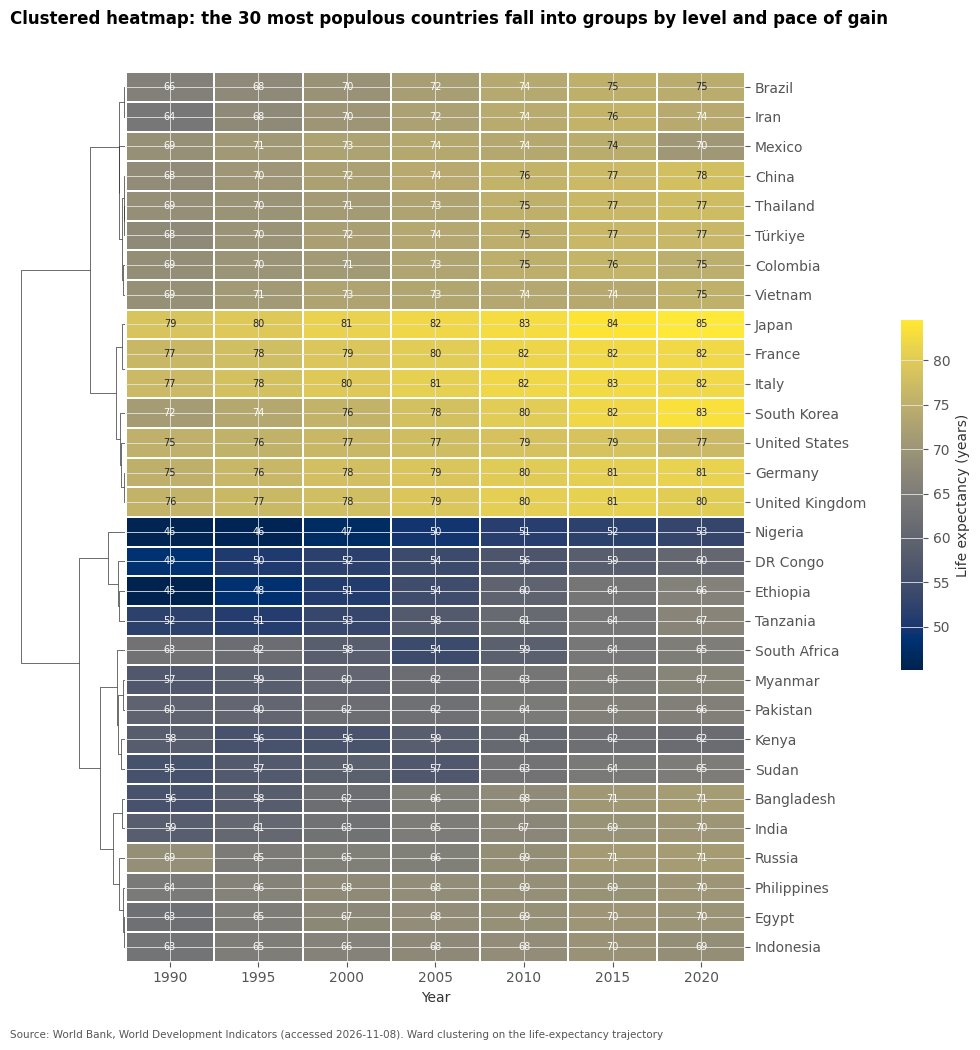

Group 1: starts ~68, ends ~75 years → Brazil, China, Colombia, Iran, Mexico, Thailand, Türkiye, Vietnam
Group 2: starts ~76, ends ~82 years → France, Germany, Italy, Japan, South Korea, United Kingdom, United States
Group 3: starts ~48, ends ~62 years → DR Congo, Ethiopia, Nigeria, Tanzania
Group 4: starts ~61, ends ~68 years → Bangladesh, Egypt, India, Indonesia, Kenya, Myanmar, Pakistan, Philippines, Russia, South Africa, Sudan


In [42]:
top30 = snap.nlargest(30, "population").index
YRS = list(range(1990, LATEST + 1, 5))
mat = (df[df.iso3.isin(top30) & df.year.isin(YRS)]
       .pivot(index="country", columns="year", values="life_expectancy").dropna())

g = sns.clustermap(mat, col_cluster=False, method="ward", cmap="cividis", figsize=(9, 10),
                   linewidths=0.3, annot=True, fmt=".0f", annot_kws=dict(fontsize=7),
                   cbar_kws=dict(label="Life expectancy (years)"), dendrogram_ratio=(0.15, 0.04),
                   cbar_pos=(1.0, 0.35, 0.025, 0.35))
g.ax_heatmap.set_xlabel("Year"); g.ax_heatmap.set_ylabel("")
g.figure.suptitle("Clustered heatmap: the 30 most populous countries fall into groups by level and pace of gain",
                  x=0.01, ha="left", fontweight="bold", y=1.01)
save(g.figure, "p7_heatmap_clustered", extra="Ward clustering on the life-expectancy trajectory")

clusters = fcluster(linkage(mat.values, "ward"), 4, "maxclust")
cl = pd.DataFrame({"cluster": clusters, "start": mat.iloc[:, 0], "end": mat.iloc[:, -1]}, index=mat.index)
for k, d in cl.groupby("cluster"):
    print(f"Group {k}: starts ~{d.start.mean():.0f}, ends ~{d.end.mean():.0f} years → {', '.join(d.index)}")

**The groups that emerge.** *(Check them against the printout above, since the exact membership depends on the latest data.)* Typically: (1) rich countries that started high and stayed high (Japan, Germany, USA...), (2) middle-income countries that started in the 60s and caught up to the 70s (China, Brazil, Iran, Vietnam...), (3) South Asian and similar countries that rose steadily from the high 50s to the high 60s (Pakistan, India, Bangladesh), and (4) Sub-Saharan countries that started lowest and, despite big gains, are still lowest (Nigeria, DR Congo...). Clustering on the whole trajectory, not just the final value, separates "catching up fast" from "stuck".

## 7.2 Bubble chart: the classic Gapminder view

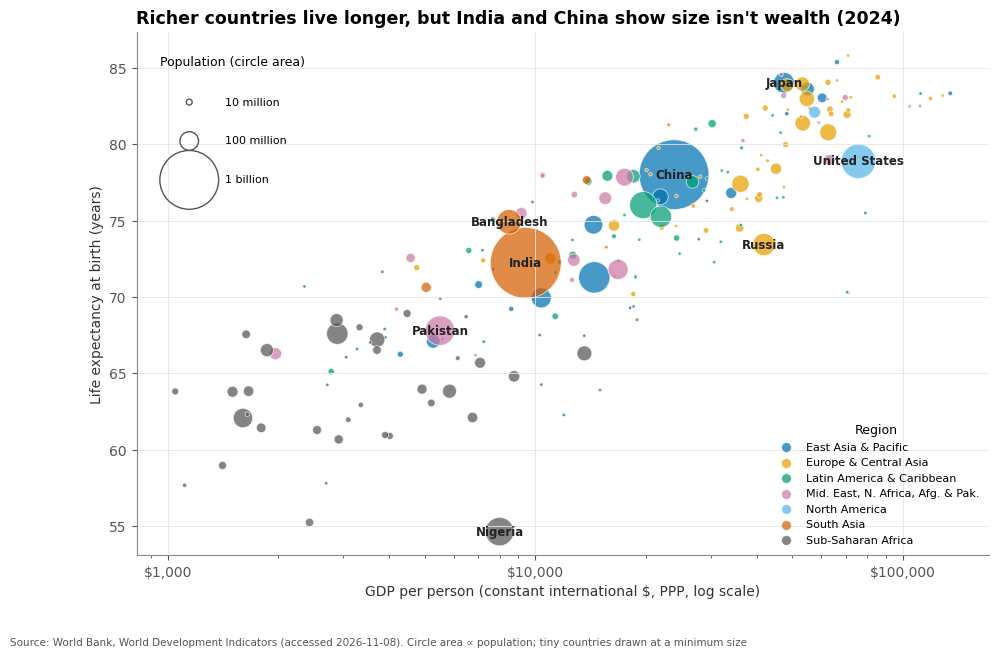

In [43]:
bb = snap.dropna(subset=["gdp_per_capita", "life_expectancy", "population"]).sort_values("population", ascending=False)
AREA = 2600 / bb.population.max()      # matplotlib's s is marker AREA (pt²), so area ∝ population

fig, ax = plt.subplots(figsize=(11, 6.8))
for r in REGION_ORDER:
    d = bb[bb.region == r]
    ax.scatter(d.gdp_per_capita, d.life_expectancy, s=np.maximum(d.population * AREA, 6), color=REGION_COLORS[r],
               alpha=0.72, edgecolor="white", linewidth=0.6, label=r)
for c in ["CHN", "IND", "USA", "NGA", "PAK", "JPN", "BGD", "RUS"]:
    if c in bb.index:
        row = bb.loc[c]
        ax.annotate(row.country, (row.gdp_per_capita, row.life_expectancy), ha="center", va="center", fontsize=8.5,
                    fontweight="bold", color="#222222")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, p: f"${v:,.0f}"))
ax.set_xlabel("GDP per person (constant international $, PPP, log scale)")
ax.set_ylabel("Life expectancy at birth (years)")

leg1 = ax.legend(title="Region", loc="lower right", fontsize=8, markerscale=0.6, title_fontsize=9)
for h in leg1.legend_handles:
    h.set_sizes([50])
ax.add_artist(leg1)
size_handles = [ax.scatter([], [], s=v * AREA, color="none", edgecolor="#555555") for v in [1e7, 1e8, 1e9]]
ax.legend(size_handles, ["10 million", "100 million", "1 billion"], title="Population (circle area)", loc="upper left",
          labelspacing=2.6, borderpad=1.6, handletextpad=2.2, fontsize=8, title_fontsize=9)
ax.set_title(f"Richer countries live longer, but India and China show size isn't wealth ({LATEST})")
save(fig, "p7_bubble", extra="Circle area ∝ population; tiny countries drawn at a minimum size")

In [44]:
anim = df.dropna(subset=["gdp_per_capita", "life_expectancy", "population", "region"])
anim = anim[anim.year <= LATEST].sort_values("year")
fig = px.scatter(anim, x="gdp_per_capita", y="life_expectancy", size="population", color="region",
                 color_discrete_map=REGION_COLORS, hover_name="country", animation_frame="year", animation_group="iso3",
                 log_x=True, size_max=55,
                 range_x=[anim.gdp_per_capita.min() * 0.8, anim.gdp_per_capita.max() * 1.2], range_y=[25, 90],
                 labels={"gdp_per_capita": "GDP per person (intl $, PPP, log)", "life_expectancy": "Life expectancy (years)",
                         "region": "Region", "population": "Population"},
                 title=f"Press play: almost every country moves up and to the right between 1990 and {LATEST}")
save_plotly(fig, "p7_bubble_animated", extra="Circle area ∝ population")

## 7.3 Treemap: world population, region → country, coloured by life expectancy

In [45]:
tm = snap.dropna(subset=["population", "life_expectancy"]).reset_index()
fig = px.treemap(tm, path=[px.Constant("World"), "region", "country"], values="population", color="life_expectancy",
                 color_continuous_scale="cividis", range_color=[tm.life_expectancy.quantile(0.02), tm.life_expectancy.max()],
                 labels={"life_expectancy": "Life expectancy (years)", "population": "Population"},
                 title=f"Where the world's people live, and how long they live there ({LATEST}): box area = population")
fig.update_traces(hovertemplate="<b>%{label}</b><br>Population: %{value:,.0f}<br>Life expectancy: %{color:.1f} years<extra></extra>")
fig.update_layout(coloraxis_colorbar=dict(title="Life expectancy<br>(years)"))
save_plotly(fig, "p7_treemap", extra="Region colour = population-weighted average")

**Treemap vs stacked bar.** The treemap is **better** when you have a hierarchy with *many* parts (200 countries inside 7 regions) and want to see the big pieces at a glance. India and China jump out as huge blocks, and you can colour by a third variable without losing anything. A stacked bar with 200 segments would be unreadable. The treemap is **worse** when you need to *compare* sizes precisely: we judge rectangle areas poorly, especially when they have different shapes (a long thin box vs a square). It also can't show change over time, while bars side by side can. For "how does South Asia's population compare with Europe's", a bar wins.

## 7.4 Encoding budget for the bubble chart

| variable | channel |
|---|---|
| GDP per person | x position (log) |
| Life expectancy | y position |
| Population | circle area |
| Region | colour hue |
| Country name | text label (only for a few) |
| Year | animation frame (interactive version) |

That's **5 variables in the static chart, 6 in the animated one**. My honest view is that a first-time reader can take in about **four**: the two axes plus one "extra" (size *or* colour) are comfortable, and a fourth works only because region colour is something people already know from maps. The animation is the limit: people watch the big bubbles move and can't also track colours and labels, which is why the static version keeps labels to eight countries.

**Reflection (Part 7).** The **bubble chart** got its message across fastest. Two position axes do most of the work, and "up and to the right = richer and longer-lived" needs no explanation. The heatmap needs you to read a colour scale first, and the treemap answers "how many people" well but the life expectancy colour takes effort.

---
# Part 8: Networks, Sankey diagrams and maps

## 8.1 Network: who looks like whom?

Nodes are countries and edges come from the relationship table built in Part 1: each country is linked to the 4 countries whose development profile is closest to its own. Node size = weighted degree, colour = region.

**On the "hairball".** If I linked every pair above a similarity cut-off, the dense middle of the distribution (upper-middle-income countries all look alike) would turn into one solid blob. Keeping only each country's 4 nearest neighbours is my filter: everyone gets a few links, nobody gets 80. Below, I also show the same network as an **adjacency matrix**, which never tangles.

In [46]:
G = nx.Graph()
for _, e in edges.iterrows():
    G.add_edge(e.source, e.target, similarity=e.similarity, distance=e.distance)
nx.set_node_attributes(G, META.country.to_dict(), "country")
nx.set_node_attributes(G, META.region.to_dict(), "region")

deg = nx.degree_centrality(G)
wdeg = dict(G.degree(weight="similarity"))
btw = nx.betweenness_centrality(G, weight="distance", normalized=True)
comms = sorted(nx.community.greedy_modularity_communities(G, weight="similarity"), key=len, reverse=True)
comm_of = {n: i + 1 for i, c in enumerate(comms) for n in c}

cent = pd.DataFrame({"country": META.country.reindex(list(G.nodes)), "region": META.region.reindex(list(G.nodes)),
                     "degree_centrality": pd.Series(deg), "betweenness": pd.Series(btw),
                     "weighted_degree": pd.Series(wdeg), "community": pd.Series(comm_of)})
cent["life_expectancy"] = snap.life_expectancy.reindex(cent.index)
if "PAK" in G:
    nbrs = sorted(G["PAK"], key=lambda n: -G["PAK"][n]["similarity"])
    print("Most similar to Pakistan:", ", ".join(G.nodes[n]["country"] for n in nbrs))
cent.sort_values("betweenness", ascending=False).head(10).round(3)

Most similar to Pakistan: Senegal, Namibia, Zimbabwe, Eswatini, Tajikistan


,country,region,degree_centrality,betweenness,weighted_degree,community,life_expectancy
ZWE,Zimbabwe,Sub-Saharan Africa,0.035,0.216,3.226,1,63.064
NAM,Namibia,Sub-Saharan Africa,0.047,0.174,4.217,2,67.516
PAK,Pakistan,"Mid. East, N. Africa, Afg. & Pak.",0.029,0.173,2.556,2,67.799
IDN,Indonesia,East Asia & Pacific,0.052,0.171,4.925,2,71.288
CHL,Chile,Latin America & Caribbean,0.035,0.145,3.512,5,81.359
SLV,El Salvador,Latin America & Caribbean,0.035,0.137,3.173,5,72.302
PHL,Philippines,East Asia & Pacific,0.041,0.137,4.066,2,69.946
NZL,New Zealand,East Asia & Pacific,0.047,0.136,5.495,3,82.010
COL,Colombia,Latin America & Caribbean,0.047,0.123,4.886,5,77.913
STP,Sao Tome and Principe,Sub-Saharan Africa,0.029,0.123,2.354,2,69.905


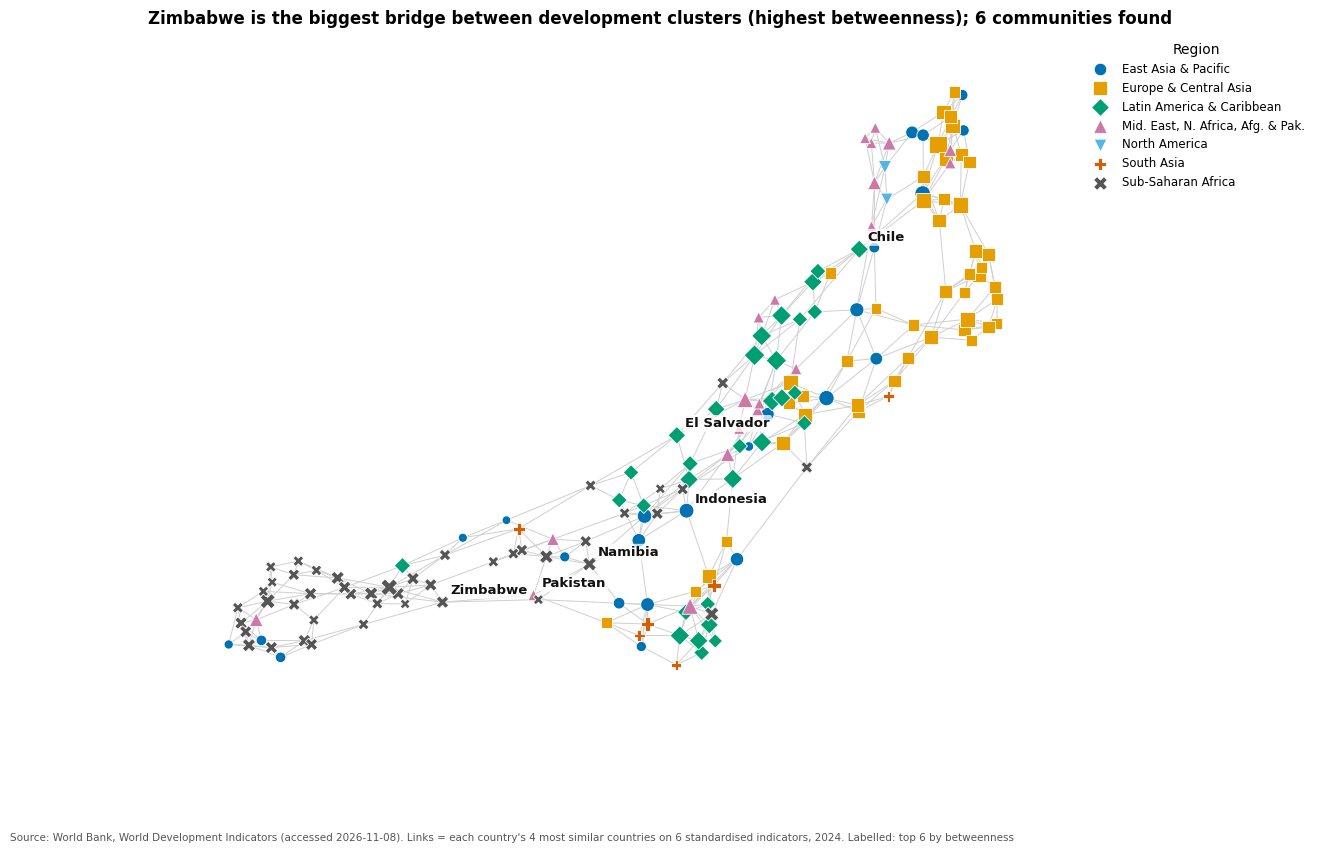

In [47]:
pos = nx.spring_layout(G, weight="similarity", seed=42, iterations=300, k=0.18)
top_b = cent.betweenness.nlargest(6).index

fig, ax = plt.subplots(figsize=(12, 9))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#cfcfcf", width=0.7)
for r in REGION_ORDER:
    nodes = [n for n in G.nodes if G.nodes[n].get("region") == r]
    if not nodes:
        continue
    xy = np.array([pos[n] for n in nodes])
    ax.scatter(xy[:, 0], xy[:, 1], s=[20 + 140 * wdeg[n] / max(wdeg.values()) for n in nodes],
               color=REGION_COLORS[r], marker=MARKERS[r], edgecolor="white", linewidth=0.6, label=r, zorder=3)
for n in top_b:
    ax.annotate(G.nodes[n]["country"], pos[n], xytext=(6, 6), textcoords="offset points", fontsize=9.5,
                fontweight="bold", color="#111111", zorder=4,
                bbox=dict(fc="white", ec="none", alpha=0.75, boxstyle="round,pad=0.15"))
ax.axis("off")
leg = ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8.5, title="Region")
ax.set_title(f"{cent.loc[top_b[0], 'country']} is the biggest bridge between development clusters "
             f"(highest betweenness); {len(comms)} communities found", fontsize=12)
save(fig, "p8_network", extra=f"Links = each country's 4 most similar countries on 6 standardised indicators, {LATEST}. "
                              "Labelled: top 6 by betweenness")

,countries,median_life_exp,main_region,examples
community,,,,
1,37,63.818000,Sub-Saharan Africa,"Afghanistan, Burundi, Benin, Burkina Faso, Cen..."
2,33,69.383000,Sub-Saharan Africa,"Angola, Azerbaijan, Bolivia, Botswana, Congo"
6,21,72.528000,Latin America & Caribbean,"Antigua and Barbuda, Bangladesh, Belize, Bhuta..."
5,26,77.482000,Latin America & Caribbean,"Albania, Argentina, Armenia, Bahamas, Brazil"
4,27,78.044000,Europe & Central Asia,"Austria, Bulgaria, Bosnia and Herzegovina, Bel..."
3,29,82.809756,Europe & Central Asia,"United Arab Emirates, Australia, Belgium, Bahr..."


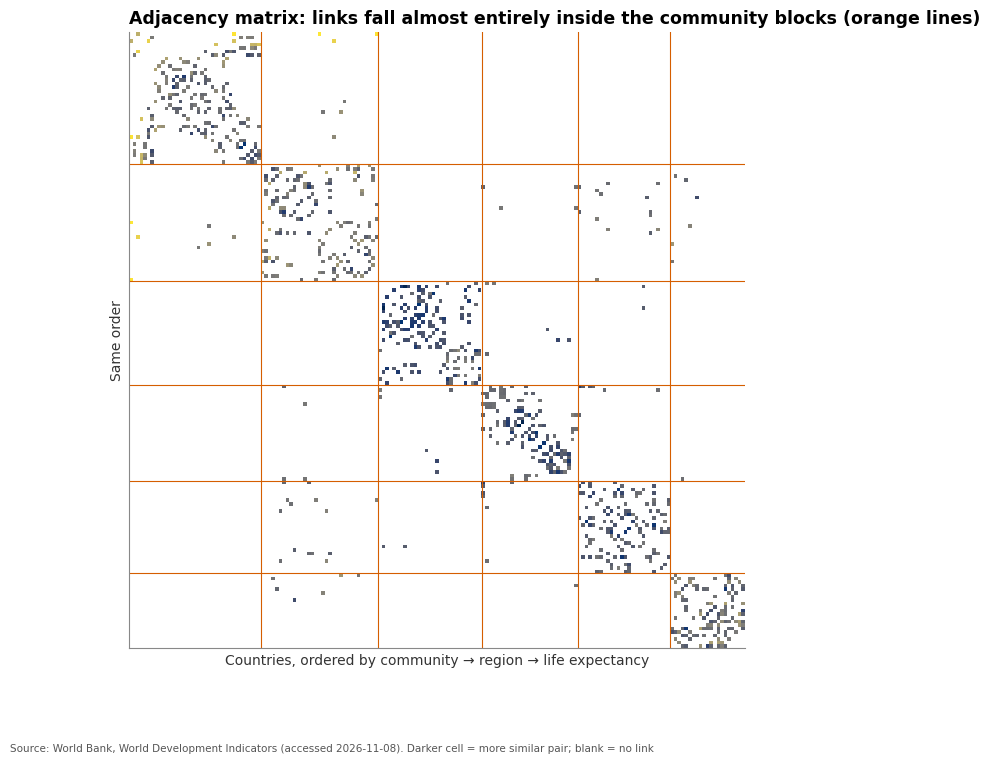

In [48]:
comm_summary = (cent.groupby("community")
                .agg(countries=("country", "size"), median_life_exp=("life_expectancy", "median"),
                     main_region=("region", lambda s: s.value_counts().index[0]),
                     examples=("country", lambda s: ", ".join(s.head(5))))
                .sort_values("median_life_exp"))
display(comm_summary)

order_nodes = cent.sort_values(["community", "region", "life_expectancy"]).index.tolist()
A = nx.to_numpy_array(G, nodelist=order_nodes, weight="similarity")
fig, ax = plt.subplots(figsize=(8.5, 8))
ax.imshow(np.where(A > 0, A, np.nan), cmap="cividis_r", interpolation="nearest")
bounds = np.cumsum(cent.community.value_counts().sort_index().values)[:-1]
for b in bounds:
    ax.axhline(b - 0.5, color="#D55E00", linewidth=0.8); ax.axvline(b - 0.5, color="#D55E00", linewidth=0.8)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.set_xlabel("Countries, ordered by community → region → life expectancy"); ax.set_ylabel("Same order")
ax.set_title("Adjacency matrix: links fall almost entirely inside the community blocks (orange lines)")
save(fig, "p8_adjacency_matrix", extra="Darker cell = more similar pair; blank = no link")

**What the measures say.** *Degree centrality* is close to flat by design (everyone has ~4–8 links), so the interesting one is **betweenness**: how often a country sits on the shortest path between two others. High-betweenness countries are the "in-between" profiles, for example middle-income countries with one indicator that's unusually high or low for their income, so they connect a richer cluster to a poorer one. Community detection finds groups that roughly match development stages, and they cut *across* World Bank regions. That's the point of the network: geography and development are not the same thing.

## 8.2 Sankey: how people moved between life expectancy bands, 1990 → latest

In [49]:
BANDS = [0, 50, 60, 70, 80, 200]
BAND_LABELS = ["under 50", "50–60", "60–70", "70–80", "80+"]
s1990 = snapshot(1990, window=1)
flow = pd.DataFrame({"from": pd.cut(s1990.life_expectancy, BANDS, labels=BAND_LABELS, right=False),
                     "to": pd.cut(snap.life_expectancy, BANDS, labels=BAND_LABELS, right=False),
                     "pop": snap.population}).dropna()
links = flow.groupby(["from", "to"], observed=True)["pop"].sum().div(1e6).reset_index()
links = links[links["pop"] > 0]

band_col = dict(zip(BAND_LABELS, [to_hex(mpl.colormaps["cividis"](x)) for x in np.linspace(0.05, 0.95, 5)]))
left = [b for b in BAND_LABELS[::-1] if b in set(links["from"])]          # high band on top
right = [b for b in BAND_LABELS[::-1] if b in set(links["to"])]
nodes = [f"1990: {b}" for b in left] + [f"{LATEST}: {b}" for b in right]
idx = {n: i for i, n in enumerate(nodes)}
node_x = [0.01] * len(left) + [0.99] * len(right)
node_y = list(np.linspace(0.05, 0.95, len(left))) + list(np.linspace(0.05, 0.95, len(right)))

def rgba(hexc, a):
    r, g, b = [int(255 * v) for v in to_rgb(hexc)]
    return f"rgba({r},{g},{b},{a})"

top3 = links.nlargest(3, "pop")
fig = go.Figure(go.Sankey(
    arrangement="snap",
    node=dict(label=nodes, x=node_x, y=node_y, pad=18, thickness=18,
              color=[band_col[n.split(": ")[1]] for n in nodes], line=dict(color="white", width=0.5)),
    link=dict(source=[idx[f"1990: {f}"] for f in links["from"]], target=[idx[f"{LATEST}: {t}"] for t in links["to"]],
              value=links["pop"].round(1), color=[rgba(band_col[f], 0.45) for f in links["from"]],
              hovertemplate="%{source.label} → %{target.label}<br>%{value:,.0f} million people<extra></extra>")))
biggest = top3.iloc[0]
fig.update_layout(
    title=f"Most people moved up a band: the biggest flow is {biggest['from']} → {biggest['to']} "
          f"({biggest['pop']:,.0f} million people)",
    font=dict(size=12), height=560)
for _, row in top3.iterrows():
    print(f"{row['from']:>9} → {row['to']:<9} {row['pop']:>8,.0f} million people")
save_plotly(fig, "p8_sankey", extra=f"Countries placed in a band by life expectancy; flow width = their {LATEST} population")

    60–70 → 70–80        3,146 million people
    50–60 → 70–80        1,722 million people
    50–60 → 60–70          768 million people


**Node order and crossings.** Both columns run from the highest band at the top to the lowest at the bottom. Since nearly every country moved *up* by one band or stayed, almost all flows go straight across or slightly upward, and very few cross each other. With alphabetical order, the ribbons would cross all over the place.

**What a Sankey shows better than a network.** A Sankey is built for *quantity flowing in one direction* between stages: you can read *how much* (ribbon width) goes from each origin to each destination, and the totals at both ends add up. A network shows *who is connected to whom* and the overall structure (clusters, bridges), but edge thickness is a weak channel, there's no left-to-right direction, and you can't read conservation (what goes in comes out). For "how did the population shift between bands", the Sankey wins.

## 8.3 Maps

In [50]:
CLASS_BINS = [0, 55, 60, 65, 70, 75, 80, 200]
CLASS_LABELS = ["under 55", "55–60", "60–65", "65–70", "70–75", "75–80", "80+"]
class_col = dict(zip(CLASS_LABELS, [to_hex(mpl.colormaps["cividis"](x)) for x in np.linspace(0, 1, 7)]))
ch = snap.reset_index().dropna(subset=["life_expectancy"])
ch["le_class"] = pd.cut(ch.life_expectancy, CLASS_BINS, labels=CLASS_LABELS, right=False).astype(str)
reg_med = ch.groupby("region").life_expectancy.median().sort_values()

fig = px.choropleth(ch, locations="iso3", color="le_class", hover_name="country",
                    category_orders={"le_class": CLASS_LABELS}, color_discrete_map=class_col,
                    hover_data={"le_class": False, "iso3": False, "life_expectancy": ":.1f"},
                    labels={"le_class": "Life expectancy (years)", "life_expectancy": "Life expectancy"},
                    title=f"Life expectancy is lowest in {reg_med.index[0]} and highest in {reg_med.index[-1]} "
                          f"(regional medians, {LATEST})")
fig.update_geos(projection_type="equal earth", showframe=False, showcoastlines=False, showcountries=True,
                countrycolor="white", landcolor="#e8e8e8", showocean=False)
fig.update_layout(height=560, legend=dict(title="Life expectancy<br>at birth (years)"))
save_plotly(fig, "p8_choropleth", extra="Grey = no data. Equal Earth projection")

In [51]:
ps = snap.reset_index().dropna(subset=["lat", "lon", "population"])
fig = px.scatter_geo(ps, lat="lat", lon="lon", size="population", color="region", color_discrete_map=REGION_COLORS,
                     hover_name="country", size_max=48, projection="equal earth",
                     hover_data={"population": ":,.0f", "lat": False, "lon": False, "region": True},
                     labels={"population": "Population", "region": "Region"},
                     title=f"{ps.nlargest(2, 'population').country.iloc[0]} and {ps.nlargest(2, 'population').country.iloc[1]} "
                           f"alone hold {ps.population.nlargest(2).sum() / ps.population.sum():.0%} of the world's people "
                           f"({LATEST}): circle area = population")
fig.update_traces(marker=dict(sizemode="area", line=dict(width=0.6, color="white"), opacity=0.8))
fig.update_geos(showframe=False, landcolor="#eeeeee", showcountries=True, countrycolor="white", showcoastlines=False)
fig.update_layout(height=560)
save_plotly(fig, "p8_proportional_symbols", extra="Circles placed at capital cities; area, not radius, ∝ population")

**Classed vs continuous, and why classed here.** I used **7 classes in 5-year steps** with a sequential palette (cividis, so it works for colour-blind readers and in grayscale). Round 5-year cut-offs are easy to remember and talk about ("everything below 60"), and a reader can match a country's colour to a legend box. A continuous scale shows more detail, but people can't tell 71 from 73 by colour anyway. The cost of classes: two countries at 69.9 and 70.1 land in different colours. I accept that because the classes are fine compared with the 30-year range.

**The choropleth pitfall.** Colour fills *land area*, not people. Russia, Canada, Australia and Greenland dominate the map visually, while Bangladesh (more people than Russia) is a speck, and the Caribbean islands vanish. A choropleth answers "what's the value in each country", not "how many people are affected". That's exactly why I paired it with the **proportional symbol map**, where circle *area* = population: there, South Asia and East Asia dominate, as they should.

**Projection: Equal Earth.** It's an *equal-area* projection, so countries keep their true relative sizes. Mercator would make Europe and Russia huge and shrink Africa, which for a life-expectancy map would visually *downplay* exactly the region with the lowest values. Equal Earth still looks familiar, unlike some other equal-area projections.

## 8.4 Map accessibility: a text version of the maps

In [52]:
rmed = snap.groupby("region").life_expectancy.median().sort_values()
low5 = snap.nsmallest(5, "life_expectancy")
high5 = snap.nlargest(5, "life_expectancy")
below60 = snap[snap.life_expectancy < 60]
share60 = below60.region.value_counts()
text_summary = (
    f"**Map summary for readers who can't see the map ({LATEST}).** Life expectancy at birth ranges from "
    f"{low5.life_expectancy.min():.1f} years in {low5.country.iloc[0]} to {high5.life_expectancy.max():.1f} years in "
    f"{high5.country.iloc[0]}. The five lowest are {', '.join(low5.country)}; the five highest are "
    f"{', '.join(high5.country)}. By region, the median country is lowest in {rmed.index[0]} ({rmed.iloc[0]:.1f} years) "
    f"and highest in {rmed.index[-1]} ({rmed.iloc[-1]:.1f}). "
    + (f"{len(below60)} countries are below 60 years, and {share60.iloc[0]} of them are in {share60.index[0]}. "
       if len(below60) else "No country is below 60 years. ")
    + f"On the population map, the five biggest circles are {', '.join(snap.nlargest(5, 'population').country)}."
)
Path(FIG / "p8_map_text_summary.md").write_text(text_summary, encoding="utf-8")
display(Markdown(text_summary))

**Map summary for readers who can't see the map (2024).** Life expectancy at birth ranges from 54.6 years in Nigeria to 86.5 years in Monaco. The five lowest are Nigeria, Chad, Central African Republic, South Sudan, Lesotho; the five highest are Monaco, San Marino, Hong Kong, Kuwait, Switzerland. By region, the median country is lowest in Sub-Saharan Africa (64.3 years) and highest in North America (82.1). 6 countries are below 60 years, and 6 of them are in Sub-Saharan Africa. On the population map, the five biggest circles are India, China, United States, Indonesia, Pakistan.

**Other accessibility steps.** Both maps have a legend with units ("years", "population"), a title that states the pattern, and the colour scale is cividis, which passed the simulation checks in Part 4 (run `cvd_sheet("p8_choropleth", show=True)` after the PNG exists). Missing countries are a neutral grey that isn't part of the scale, so "no data" can't be confused with "low".

**Reflection (Part 8).** I'd choose a **map** when the question is about *where*, for example "is low life expectancy concentrated in one part of the world?". Proximity on a map *means* something there. I'd choose a **network** when the question is about *who resembles or connects to whom*, regardless of where they are. For example, look at which countries come out as most similar to Pakistan (printed in 8.1): that's a question about resemblance, not distance, and a map can't answer it.

---
# Part 9: The visual story

The cell below writes the story using the actual numbers from the data (so nothing in the text goes stale if the data updates), saves it as `visual_story.md`, and shows it here.

- **Audience:** Pakistan's Ministry of National Health Services, Regulations & Coordination.
- **Central message:** Pakistan lives about as long as its income predicts, but that isn't a ceiling. Bangladesh started behind Pakistan in 1990, is now well ahead, and only part of that lead comes from being richer.
- **Five charts:** bubble chart (Part 7, multivariate), scatter with trend line (Part 5), box + strip plot (Part 6), clustered heatmap (Part 7), choropleth (Part 8, accessible cividis palette).

In [53]:
pk, bd = snap.loc["PAK"], snap.loc["BGD"]
pk90, bd90 = s1990.life_expectancy.get("PAK", np.nan), s1990.life_expectancy.get("BGD", np.nan)
pk_rank = int((snap.life_expectancy > pk.life_expectancy).sum()) + 1

# how much of today's Bangladesh-Pakistan gap would the income difference alone predict?
gap_now = bd.life_expectancy - pk.life_expectancy
from_income = slope * (bd.log_gdp - pk.log_gdp)
not_income = gap_now - from_income

# Pakistan's income peers: countries within about a third of its GDP per person
peers = snap[snap.gdp_per_capita.between(pk.gdp_per_capita / 1.35, pk.gdp_per_capita * 1.35)]
peers = peers.dropna(subset=["life_expectancy"]).drop(index="PAK", errors="ignore").sort_values("life_expectancy", ascending=False)
better = peers[peers.life_expectancy > pk.life_expectancy]

# the World Bank moved Pakistan out of "South Asia", so I list its neighbours myself
NEIGHBOURS = ["PAK", "IND", "BGD", "NPL", "LKA", "BTN", "MDV", "AFG"]
nbr = snap.reindex([c for c in NEIGHBOURS if c in snap.index]).sort_values("life_expectancy", ascending=False)
pk_pos = list(nbr.index).index("PAK") + 1
below_pk = nbr.country.iloc[pk_pos:].tolist()

lmc = snap[snap.income_group == "Lower middle income"]
lmc_70 = (lmc.life_expectancy >= 70).sum()
same_cluster = ("Pakistan" in cl.index and "Bangladesh" in cl.index
                and cl.loc["Pakistan", "cluster"] == cl.loc["Bangladesh", "cluster"])
u5_ratio = pk.under5_mortality / bd.under5_mortality

def ordinal(n):
    return f"{n}{'th' if 11 <= n % 100 <= 13 else {1: 'st', 2: 'nd', 3: 'rd'}.get(n % 10, 'th')}"

def vs_trend(res):
    if res < -1:
        return f"{abs(res):.1f} years below the trend line"
    if res > 1:
        return f"{res:.1f} years above the trend line"
    return f"almost exactly on the trend line ({res:+.1f} years)"

peer_line = (f"Of the {len(peers)} countries with an income per person within about a third of Pakistan's, "
             f"**{len(better)} live longer**"
             + (f", up to {better.country.iloc[0]} at {better.life_expectancy.iloc[0]:.1f} years." if len(better) else "."))
neigh_line = (f"Only {', '.join(below_pk)} rank{'s' if len(below_pk) == 1 else ''} lower." if below_pk
              else "It comes last.")
cluster_line = ("They still sit in the same cluster of large countries, but Bangladesh's row turns light (longer lives) "
                "much sooner." if same_cluster else
                "They have ended up in different clusters: Bangladesh's path now looks more like the countries that caught up.")
u5_line = (f"A child in Pakistan is **{u5_ratio:.1f} times as likely to die before age five** as a child in Bangladesh "
           f"({pk.under5_mortality:.0f} vs {bd.under5_mortality:.0f} deaths per 1,000 live births). Deaths in early "
           f"childhood pull life expectancy at birth down more than deaths at any other age, so this alone covers a "
           f"lot of the gap. Child survival (immunisation, care around birth, clean water) is the lever worth "
           f"studying in Bangladesh's record." if u5_ratio > 1.1 else
           f"Child mortality is similar in the two countries ({pk.under5_mortality:.0f} vs {bd.under5_mortality:.0f} "
           f"per 1,000), so the difference comes from survival at older ages, which is where to look next.")

story = f"""# Bangladesh started behind. Now it's ahead. What can Pakistan learn?

*A briefing for the Ministry of National Health Services, Regulations & Coordination. Data: World Bank WDI, {LATEST}.*

**The question.** A Pakistani born today can expect to live **{pk.life_expectancy:.1f} years**, which ranks {pk_rank}
out of {len(snap)} countries. In 1990, Bangladesh was {abs(pk90 - bd90):.1f} years
{'behind' if bd90 < pk90 else 'ahead of'} Pakistan ({bd90:.1f} vs {pk90:.1f}). Today it is
**{abs(gap_now):.1f} years {'ahead' if gap_now > 0 else 'behind'}** ({bd.life_expectancy:.1f}). Is that just because
Bangladesh got richer?

### 1. Income matters a lot

![Bubble chart](figures/p7_bubble.png)

Across the world, richer countries live longer: each tenfold rise in income goes with roughly **{slope:.0f} more
years** of life. Bangladesh is now {'richer' if bd.gdp_per_capita > pk.gdp_per_capita else 'poorer'} per person than
Pakistan (${bd.gdp_per_capita:,.0f} vs ${pk.gdp_per_capita:,.0f} a year, PPP),
{'so some of its lead is simply money' if bd.gdp_per_capita > pk.gdp_per_capita else 'so its lead is not about money at all'}.

### 2. But income only explains part of the gap

![Scatter with trend](figures/p5_scatter.png)

The dashed line shows what income alone predicts. Pakistan sits {vs_trend(pk.residual)}, so it lives
{'about as long as' if abs(pk.residual) <= 1 else ('less long than' if pk.residual < 0 else 'longer than')} its income
predicts. Bangladesh sits {vs_trend(bd.residual)}. The income difference between them would predict about
**{from_income:.1f} extra years** for Bangladesh; the real gap is {gap_now:.1f} years, which leaves roughly
**{not_income:.1f} years that income doesn't explain**. {peer_line}

### 3. Among its neighbours, Pakistan is {'near the bottom' if pk_pos >= len(nbr) - 2 else 'in the middle'}

![Box and strip plot](figures/p6_box_strip.png)

The World Bank now files Pakistan under "{pk.region}", so in this chart its ring sits among the Gulf states. The
fairer comparison is its South Asian neighbours: of these {len(nbr)} countries, Pakistan comes **{ordinal(pk_pos)}**.
{neigh_line}

### 4. The gap opened slowly, over decades

![Clustered heatmap](figures/p7_heatmap_clustered.png)

Since 1990, Pakistan has gained **{pk.life_expectancy - pk90:.0f} years** and Bangladesh
**{bd.life_expectancy - bd90:.0f}**. {cluster_line}

### 5. Being lower-middle-income isn't destiny

![Choropleth](figures/p8_choropleth.png)

The lowest values cluster in {reg_med.index[0]}, but the colours don't follow wealth neatly: {lmc_70} of the
{len(lmc)} lower-middle-income countries already live 70 years or more.

**Takeaway.** Income accounts for about {from_income:.0f} of the {gap_now:.0f} years between Bangladesh and Pakistan.
The rest comes from things a GDP figure doesn't capture, and the same data points to where to look first. {u5_line}

---
**Methods note.** Data: World Bank World Development Indicators via the public API (v2), downloaded {meta['downloaded']}.
Life expectancy at birth (SP.DYN.LE00.IN); GDP per person in constant PPP dollars (NY.GDP.PCAP.PP.KD); under-5
mortality (SH.DYN.MORT); population (SP.POP.TOTL). Aggregates such as "World" were removed; country names shortened;
impossible values set to missing; no gaps were filled in. Each country's value for {LATEST} is its most recent value
from {LATEST - 2}–{LATEST}. The trend line is an ordinary least-squares fit of life expectancy on log10 GDP per person
(slope {slope:.1f} years per tenfold income); the "explained by income" part of the gap is that slope times the
difference in log10 GDP. "Peers" are countries within ±35% of Pakistan's GDP per person; "neighbours" are the eight
South Asian countries listed in the notebook. **Limitations:** life expectancy for many countries is modelled by the
UN rather than measured, so differences under a year shouldn't be over-read; PPP figures carry uncertainty; a trend line
across countries is a correlation, not proof of what causes the gap; and the regions and income groups are the World
Bank's current classification applied to every year.
"""
Path("visual_story.md").write_text(story, encoding="utf-8")
display(Markdown(story))

# Bangladesh started behind. Now it's ahead. What can Pakistan learn?

*A briefing for the Ministry of National Health Services, Regulations & Coordination. Data: World Bank WDI, 2024.*

**The question.** A Pakistani born today can expect to live **67.8 years**, which ranks 169
out of 217 countries. In 1990, Bangladesh was 3.9 years
behind Pakistan (55.8 vs 59.7). Today it is
**7.1 years ahead** (74.9). Is that just because
Bangladesh got richer?

### 1. Income matters a lot

![Bubble chart](figures/p7_bubble.png)

Across the world, richer countries live longer: each tenfold rise in income goes with roughly **12 more
years** of life. Bangladesh is now richer per person than
Pakistan ($8,487 vs $5,502 a year, PPP),
so some of its lead is simply money.

### 2. But income only explains part of the gap

![Scatter with trend](figures/p5_scatter.png)

The dashed line shows what income alone predicts. Pakistan sits almost exactly on the trend line (-0.4 years), so it lives
about as long as its income
predicts. Bangladesh sits 4.5 years above the trend line. The income difference between them would predict about
**2.3 extra years** for Bangladesh; the real gap is 7.1 years, which leaves roughly
**4.9 years that income doesn't explain**. Of the 22 countries with an income per person within about a third of Pakistan's, **11 live longer**, up to Tonga at 73.1 years.

### 3. Among its neighbours, Pakistan is near the bottom

![Box and strip plot](figures/p6_box_strip.png)

The World Bank now files Pakistan under "Mid. East, N. Africa, Afg. & Pak.", so in this chart its ring sits among the Gulf states. The
fairer comparison is its South Asian neighbours: of these 8 countries, Pakistan comes **7th**.
Only Afghanistan ranks lower.

### 4. The gap opened slowly, over decades

![Clustered heatmap](figures/p7_heatmap_clustered.png)

Since 1990, Pakistan has gained **8 years** and Bangladesh
**19**. They still sit in the same cluster of large countries, but Bangladesh's row turns light (longer lives) much sooner.

### 5. Being lower-middle-income isn't destiny

![Choropleth](figures/p8_choropleth.png)

The lowest values cluster in Sub-Saharan Africa, but the colours don't follow wealth neatly: 17 of the
47 lower-middle-income countries already live 70 years or more.

**Takeaway.** Income accounts for about 2 of the 7 years between Bangladesh and Pakistan.
The rest comes from things a GDP figure doesn't capture, and the same data points to where to look first. A child in Pakistan is **1.8 times as likely to die before age five** as a child in Bangladesh (56 vs 30 deaths per 1,000 live births). Deaths in early childhood pull life expectancy at birth down more than deaths at any other age, so this alone covers a lot of the gap. Child survival (immunisation, care around birth, clean water) is the lever worth studying in Bangladesh's record.

---
**Methods note.** Data: World Bank World Development Indicators via the public API (v2), downloaded 2026-11-08.
Life expectancy at birth (SP.DYN.LE00.IN); GDP per person in constant PPP dollars (NY.GDP.PCAP.PP.KD); under-5
mortality (SH.DYN.MORT); population (SP.POP.TOTL). Aggregates such as "World" were removed; country names shortened;
impossible values set to missing; no gaps were filled in. Each country's value for 2024 is its most recent value
from 2022–2024. The trend line is an ordinary least-squares fit of life expectancy on log10 GDP per person
(slope 12.0 years per tenfold income); the "explained by income" part of the gap is that slope times the
difference in log10 GDP. "Peers" are countries within ±35% of Pakistan's GDP per person; "neighbours" are the eight
South Asian countries listed in the notebook. **Limitations:** life expectancy for many countries is modelled by the
UN rather than measured, so differences under a year shouldn't be over-read; PPP figures carry uncertainty; a trend line
across countries is a correlation, not proof of what causes the gap; and the regions and income groups are the World
Bank's current classification applied to every year.


## Reflection

*(about 360 words, worth rewriting in your own voice before submitting)*

Before this project I treated visualization as the last step: you do the analysis, then you "make a chart" to show it. The workflow turned that around for me. The ask-prepare-encode-build-evaluate-communicate loop made me decide who the chart was for *before* writing any plotting code, and that one decision changed almost every choice after it. A chart for a health ministry needs a title that says what to do; a chart for a classmate can afford to be exploratory.

The step that surprised me most was **Prepare**. I expected cleaning to be a chore before the real work. Instead it was where most of the real decisions were. Things like whether to weight regional averages by population, or which year counts as "latest", change the picture more than any colour choice. A wrong "NA" turning Namibia into a missing value would never show up as an error. The chart would just be quietly wrong. Keeping a cleaning log felt bureaucratic at first, but it's the only reason I could explain my own numbers a week later.

The principle that changed my habits most was **colour honesty**. I used to accept whatever default palette a library gave me. Running my own charts through colour-blindness simulations was humbling: the default tab10 lines that looked perfectly clear to me collapsed into two or three indistinguishable colours under deuteranopia. Now my default is to label lines directly and treat colour as a backup, not the only cue. The same goes for axes: after computing a lie factor for a truncated bar chart, I check every bar chart's baseline.

The perception experiment was also eye-opening. Knowing in theory that area is judged worse than length is different from watching classmates guess a ratio of 1.5 as "about 3" from bubbles.

With more time, I would add real bilateral data (migration or trade flows) instead of a derived similarity network, build the dashboard with proper filtering by income group and year, and test the visual story with an actual non-technical reader to see whether they get the main point in under a minute. I'd also look into *why* the over-performing countries do so well, because the charts can show the gap but can't explain it.

---
# Part 10: The dashboard

The dashboard is a small **Streamlit** app in `dashboard/app.py`. It reads `data/processed/wdi_clean.csv`, which this notebook wrote in Part 1. It has a year slider, region and income filters, and three tabs: the GDP–life-expectancy scatter, the choropleth, and regional trends. All of its controls are standard form widgets, so they work with the keyboard too.

```bash
streamlit run dashboard/app.py
```

To deploy it, push the repo to GitHub and connect it on [share.streamlit.io](https://share.streamlit.io) (main file `dashboard/app.py`), or record a 1–2 minute screen capture of yourself using it. See `dashboard/README.md`.

---
# Final submission checklist

In [54]:
for png in sorted(FIG.glob("*.png")):
    cvd_sheet(png.stem)          # colour-blind + grayscale sheet for every exported chart

rows = []
for f in sorted(set(p.stem for p in FIG.iterdir() if p.is_file() and p.suffix in {".png", ".svg", ".html"})):
    rows.append({"figure": f,
                 "png": (FIG / f"{f}.png").exists(), "svg": (FIG / f"{f}.svg").exists(),
                 "html": (FIG / f"{f}.html").exists(), "cvd/grayscale sheet": (CHECKS / f"{f}_check.png").exists()})
inv = pd.DataFrame(rows)
print(f"{len(inv)} figures exported to {FIG}/; {inv['cvd/grayscale sheet'].sum()} have check sheets")
missing_png = inv[~inv.png].figure.tolist()
if missing_png:
    print("No PNG for (install kaleido, see README):", ", ".join(missing_png))
print("Visual story:", Path("visual_story.md").exists(), "| Map text summary:", (FIG / "p8_map_text_summary.md").exists())
if PERCEPTION_PLACEHOLDER or TIMING_PLACEHOLDER:
    print("\n!! Part 2 is still using PLACEHOLDER experiment data. Fill in data/perception_responses.csv and "
          "data/preattentive_timings.csv before submitting.")
inv

45 figures exported to figures/; 43 have check sheets
No PNG for (install kaleido, see README): p3_linked_highlight, p4_palette_switch
Visual story: True | Map text summary: True


,figure,png,svg,html,cvd/grayscale sheet
0,p1_interactive_line,True,False,True,True
1,p1_rough_draft,True,True,False,True
2,p2_clutter_after,True,True,False,True
3,p2_clutter_before,True,True,False,True
4,p2_overview_detail,True,False,True,True
5,p2_perception_results,True,True,False,True
6,p2_perception_stimuli,True,True,False,True
7,p2_preattentive,True,True,False,True
8,p3_gestalt_broken,True,True,False,True
9,p3_gestalt_small_multiples,True,True,False,True


| checklist item | where it's handled |
|---|---|
| Notebook runs top to bottom without errors | data is cached in `data/raw/`; every chart drops the rows it can't use instead of crashing; Plotly PNG export fails softly if `kaleido` is missing |
| Titles state the finding, axes have units, source note, legend where needed | every `save()` / `save_plotly()` call stamps the source and access date; most titles are built from the data so they stay true |
| Grayscale and colour-blindness check | `figures/checks/*_check.png` for every PNG; palette ΔE table and WCAG contrast table in Part 4 |
| No truncated bar baseline, unjustified dual axis or rainbow palette | all bar charts start at zero; the only dual-axis and rainbow charts are the labelled **MISLEADING** examples in Part 4.3, which exist to be criticised |
| All figures in `figures/` | see the inventory table above |
| Visual story and reflection included | `visual_story.md` (Part 9) and the reflection section |